# Workstream A · A1: ranked fast-feature table

**Owner:** Tenor · **Sprint deliverable:** A1 (Day 2) · **Branch:** `tenor/a1-fast-features` (steps 1–8), `tenor/a1-beat-detection-v2` (step 9)

**Question:** which fast (beat-to-beat) features differ between the stress classes, per ring, and how big is the difference when we count **surveys**, not windows?

**Steps in this notebook**

| Step | What | Status |
|---|---|---|
| 1 | Run Anisha's Python feature code on the sample file and check it against the MATLAB logic | done |
| 2 | Run it on Rings 3, 4 and 1; window counts and drops | done |
| 3 | Clean-pulse quality gate (separate, labelled step) | done |
| 4 | One value per survey; raw / per-person / per-day normalisation | done |
| 5 | Effect sizes (Cliff's δ, survey-bootstrap CI), ranked table + CSV | done |
| 6 | Per-class distribution plots | done |
| 7 | Supporting: window-size check (input for Yaxian, Workstream C) | done |
| 8 | Findings-table rows | done |
| 9 | Follow-up (19 Nov meeting): beat detection v2 for HR/HRV, tested and re-run | done |

**Decisions used here** (agreed with Tenor before running):
- Unit of evidence = one **survey × label** segment (a survey whose `Period`s carry different labels is split); bootstrap resamples whole `Survey_ID`s.
- Day-0 baseline files are **included** (the team's models used them) and marked `is_baseline`.
- Study **days 0–10 only**, to match Workstream B (Anisha's B1). This drops Ring 1's day 12 and 13 files (1,447 windows). `*_new_format*` files are **excluded** (team decision).
- Anisha's 30 s warm-up drop is **kept** as written, and counted.

In [1]:
import io, re, time, contextlib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import butter, filtfilt, lfilter, lfilter_zi, find_peaks

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)
%matplotlib inline

# ---- Paths: edit these if your folders live elsewhere -------------------------------
# The notebook sits in m3x/PilotPhaseC/analysis/. Data and the sample file are outside the repo.
REPO_ROOT  = Path.cwd().resolve().parents[1]                 # .../m3x
WORKSPACE  = REPO_ROOT.parent                                 # folder that holds m3x/, data/, feature_code/
DATA_DIR   = WORKSPACE / 'data' / '3_cohort_01_for_data_analysis'
SAMPLE_CSV = WORKSPACE / 'feature_code' / 'sophia_day5_raw.csv'
CACHE_DIR  = WORKSPACE / 'cache' / 'A1'                       # window-level features (derived data, NOT committed)
OUT_DIR    = Path.cwd() / 'outputs'                           # small result tables / figures that go in the PR
for p in (CACHE_DIR, OUT_DIR):
    p.mkdir(parents=True, exist_ok=True)

RINGS = {  # ring key -> folder name. Rings 3 and 4 are the main focus, Ring 1 is secondary.
    'R3': 'Ring_03_PID_102',
    'R4': 'Ring_04_PID_101',
    'R1': 'Ring_01_PID_104',
}
CLASSES_4 = ['relax', 'eustress', 'distress', 'eustress+distress']
TO_2CLASS = {'relax': 'good', 'eustress': 'good', 'distress': 'bad', 'eustress+distress': 'bad'}

# Chart colours (reference categorical palette, fixed order)
C_BLUE, C_ORANGE, C_AQUA, C_GREY = '#2a78d6', '#eb6834', '#1baf7a', '#898781'
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.edgecolor': '#c3c2b7', 'axes.grid': True, 'grid.color': '#e1e0d9',
                     'grid.linewidth': 0.6, 'axes.labelcolor': '#52514e', 'xtick.color': '#52514e',
                     'ytick.color': '#52514e', 'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb'})
print('data  :', DATA_DIR, DATA_DIR.exists())
print('sample:', SAMPLE_CSV, SAMPLE_CSV.exists())
print('cache :', CACHE_DIR)

data  : /Users/tenor/Documents/m3x_work/data/3_cohort_01_for_data_analysis True
sample: /Users/tenor/Documents/m3x_work/feature_code/sophia_day5_raw.csv True
cache : /Users/tenor/Documents/m3x_work/cache/A1


## Step 1 · Anisha's feature code, copied as is

The next three code cells are copied **word for word** from `M3X_Ring_Feature_Extraction.ipynb` (Anisha's repo, `feature_code/m3x-feature-model/`). The signal processing is not changed. The only edits:

- Her load / check / process cells are wrapped in functions (`load_m3x_file`, `extract_features`) so they can run on many files. The bodies are unchanged.
- Lines marked **`# [A1 ADDED]`** only *keep* more columns on each output row: the survey answers and `RealTime` (needed for per-day normalisation and timing), and `n_rr_LED1` / `n_PA_LED1` (number of beat intervals and amplitudes, needed by the quality gate in step 3).
- Her per-window `print` output is silenced at the call site (`contextlib.redirect_stdout`), not removed.

Her settings and helpers (cells 5 and 7 of her notebook):

In [2]:
# ===== Anisha: "Signal processing settings" (verbatim) =====
low_cutoff = 0.5
high_cutoff = 3.0
fc_smooth = 2.5

min_peak_distance_max = 0.45
min_peak_distance_min = 0.45
min_time_after_min_to_max = 0.15

expected_samples = 112
expected_row_index = np.arange(112)

# ===== Anisha: "User settings" that the code below reads (values for an all-windows run) =====
analysis_mode = 'all_windows'
selected_windows = [26]
default_plot_windows = [26]
enable_visualization = False
skip_first_seconds = 30        # advisor: ignore windows that start in the first 30 s
LED_MAX = 524287               # sensor ceiling (2^19 - 1); readings here are clipped

In [3]:
# ===== Anisha: "Helper functions" (verbatim) =====
def get_numeric_column(df, name):
    """Case-insensitive column lookup, converted to float (bad text -> NaN), like getNumericColumn."""
    matches = [c for c in df.columns if str(c).lower() == name.lower()]
    if not matches:
        raise KeyError(f'Required column not found: {name}')
    return pd.to_numeric(df[matches[0]], errors='coerce').to_numpy(dtype=float)


def matlab_findpeaks(y, x, min_peak_distance=None):
    """
    Mimics MATLAB [pks, locs] = findpeaks(y, x, 'MinPeakDistance', d).
    - Local maxima only (no edge points)
    - Plateaus report their left-most sample
    - MinPeakDistance in x units: keep tallest first, drop neighbours within +/- d
    Returns (peaks, locs) sorted by location.
    """
    y = np.asarray(y, float).ravel()
    x = np.asarray(x, float).ravel()
    n = len(y)
    if n < 3:
        return np.array([]), np.array([])

    # find peaks, handling flat tops like MATLAB (left edge of plateau)
    idx = []
    i = 1
    while i < n - 1:
        if y[i] > y[i - 1]:
            j = i
            while j < n - 1 and y[j + 1] == y[i]:
                j += 1
            if j < n - 1 and y[j + 1] < y[i]:
                idx.append(i)
            i = j + 1
        else:
            i += 1
    idx = np.array(idx, dtype=int)
    if idx.size == 0:
        return np.array([]), np.array([])

    pks = y[idx]
    locs = x[idx]

    if min_peak_distance is not None and min_peak_distance > 0 and idx.size > 1:
        # sort by height descending (stable, ties keep location order)
        order = np.argsort(-pks, kind='stable')
        pks_s, locs_s = pks[order], locs[order]
        delete = np.zeros(len(pks_s), bool)
        for k in range(len(pks_s)):
            if not delete[k]:
                close = (locs_s >= locs_s[k] - min_peak_distance) & \
                        (locs_s <= locs_s[k] + min_peak_distance)
                delete |= close
                delete[k] = False
        keep = order[~delete]
        keep.sort()
        pks, locs = pks[keep], locs[keep]

    return pks, locs


def get_ppg_features(x_sub, t_sub, min_peak_distance_max,
                     min_peak_distance_min, min_time_after_min_to_max):
    """Python version of getPPGFeatures. Returns a dict."""
    nan = np.nan
    out = dict(HR=nan, n_rr=0, PA=nan, n_PA=0, PA_STD=nan, PA_RMSSD=nan,
               PA_CV=nan, SDNN=nan, RMSSD=nan,
               max_locs=np.array([]), max_peaks=np.array([]),
               min_locs=np.array([]), min_peaks=np.array([]))

    x_sub = np.asarray(x_sub, float).ravel()
    t_sub = np.asarray(t_sub, float).ravel()

    valid = np.isfinite(x_sub) & np.isfinite(t_sub)
    x_sub, t_sub = x_sub[valid], t_sub[valid]

    # unique(t, 'stable'): keep first occurrence, original order
    _, first_idx = np.unique(t_sub, return_index=True)
    first_idx = np.sort(first_idx)
    t_sub, x_sub = t_sub[first_idx], x_sub[first_idx]

    if len(x_sub) < 5:
        return out

    # Maxima
    max_peaks, max_locs = matlab_findpeaks(x_sub, t_sub, min_peak_distance_max)

    # Minima
    min_neg, min_locs = matlab_findpeaks(-x_sub, t_sub, min_peak_distance_min)
    min_peaks = -min_neg

    # Reject maxima too soon after the preceding minimum
    if max_locs.size and min_locs.size:
        keep = np.ones(max_locs.size, bool)
        for k, mloc in enumerate(max_locs):
            prev = np.where(min_locs < mloc)[0]
            if prev.size:
                if mloc - min_locs[prev[-1]] < min_time_after_min_to_max:
                    keep[k] = False
        max_locs, max_peaks = max_locs[keep], max_peaks[keep]

    out.update(max_locs=max_locs, max_peaks=max_peaks,
               min_locs=min_locs, min_peaks=min_peaks)

    # PA / PAV
    all_locs = np.concatenate([max_locs, min_locs])
    all_peaks = np.concatenate([max_peaks, min_peaks])
    all_peaks = all_peaks[np.argsort(all_locs, kind='stable')]

    if len(all_peaks) >= 2:
        amps = np.abs(np.diff(all_peaks))
        out['PA'] = np.mean(amps)
        out['n_PA'] = len(amps)
        if len(amps) >= 2:
            out['PA_STD'] = np.std(amps, ddof=1)
            out['PA_RMSSD'] = np.sqrt(np.mean(np.diff(amps) ** 2))
            if np.isfinite(out['PA']) and out['PA'] != 0:
                out['PA_CV'] = out['PA_STD'] / out['PA']

    # HR / HRV from minima
    if len(min_locs) >= 2:
        rr = np.diff(min_locs)
        rr = rr[np.isfinite(rr) & (rr > 0)]
        if rr.size:
            out['HR'] = 60.0 / np.mean(rr)
            out['n_rr'] = len(rr)
            if rr.size >= 2:
                out['SDNN'] = np.std(rr, ddof=1)
                out['RMSSD'] = np.sqrt(np.mean(np.diff(rr) ** 2))

    return out


def matlab_filtfilt(b, a, x):
    """filtfilt with MATLAB's pad length 3*(nfilt-1)."""
    nfilt = max(len(a), len(b))
    return filtfilt(b, a, x, padtype='odd', padlen=3 * (nfilt - 1))

Her loading, window-check and per-window processing cells, wrapped in functions (bodies verbatim apart from `# [A1 ADDED]` lines):

In [4]:
# ===== Anisha: "Load the labeled ring file" + "Read the columns we need" (verbatim body) =====
def load_m3x_file(filename):
    print(f'Loading file: {filename}')

    if str(filename).lower().endswith(('.xlsx', '.xls')):
        raw_data = pd.read_excel(filename)
    else:
        raw_data = pd.read_csv(filename, low_memory=False)

    print(f'Rows read: {len(raw_data)}')
    print(f'Columns: {list(raw_data.columns)}')

    data = pd.DataFrame({
        'raw_window_index': get_numeric_column(raw_data, 'Global_Window'),
        'row_index':        get_numeric_column(raw_data, 'Row_In_Window'),
        'timestamp_ms':     get_numeric_column(raw_data, 'Timestamp_ms'),
        'led1':             get_numeric_column(raw_data, 'LED1'),
        'led2':             get_numeric_column(raw_data, 'LED2'),
        'led3':             get_numeric_column(raw_data, 'LED3'),
        'temp':             get_numeric_column(raw_data, 'TempC_x100') / 100,   # -> degC
        'accx':             get_numeric_column(raw_data, 'AccX_mg') / 1000,     # mg -> g
        'accy':             get_numeric_column(raw_data, 'AccY_mg') / 1000,
        'accz':             get_numeric_column(raw_data, 'AccZ_mg') / 1000,
    })
    data['Label'] = raw_data['Label'].astype(str).values

    # keep a few ID columns if the file has them
    id_cols = [c for c in ['PID', 'Ring_ID', 'Session_ID', 'Window_In_Session', 'Survey_ID', 'Period']
               if c in raw_data.columns]
    id_cols += [c for c in ['RealTime', 'Survey_Completed', 'Opportunity_1to6',           # [A1 ADDED]
                            'Pressure_1to6', 'Stress_0to100'] if c in raw_data.columns]   # [A1 ADDED]
    for c in id_cols:
        data[c] = raw_data[c].values

    # [A1 ADDED] how many distinct Survey_ID / Period values each window has (her check only looks at Label)
    ambiguity = (raw_data.groupby('Global_Window')[['Survey_ID', 'Period']].nunique(dropna=False)   # [A1 ADDED]
                 if {'Survey_ID', 'Period'} <= set(raw_data.columns) else None)                    # [A1 ADDED]

    data = data.dropna(subset=['raw_window_index', 'row_index', 'timestamp_ms', 'led1', 'led2', 'led3',
                               'temp', 'accx', 'accy', 'accz']).reset_index(drop=True)
    data['raw_window_index'] = data['raw_window_index'].astype(int)
    data['row_index'] = data['row_index'].astype(int)

    print(f'Valid sensor rows: {len(data)}')
    print(f'Windows in file: {data.raw_window_index.nunique()}')
    return data, id_cols, ambiguity, len(raw_data)   # [A1 ADDED] return instead of globals


# ===== Anisha: "Check the windows" + "Choose windows" + "Process each window" + "Build table" (verbatim body) =====
def extract_features(data, id_cols):
    data = data.sort_values(['raw_window_index', 'row_index'], kind='stable').reset_index(drop=True)

    complete_window_ids = []
    check_rows = []
    for wid, w in data.groupby('raw_window_index', sort=True):
        rows = w['row_index'].to_numpy()
        start_ms = w['timestamp_ms'].iloc[0]
        one_label = w['Label'].nunique() == 1
        saturated = bool((w[['led1', 'led2', 'led3']] >= LED_MAX).any().any())

        if start_ms < skip_first_seconds * 1000:       # Timestamp_ms = time since the ring turned on
            status = f'Skipped_First_{skip_first_seconds}s'
        elif len(rows) != expected_samples or not np.array_equal(rows, expected_row_index):
            status = 'Skipped_Incomplete'
        elif not one_label:
            status = 'Skipped_Mixed_Label'
        else:
            status = 'Complete'
            complete_window_ids.append(int(wid))

        check_rows.append({'Raw_Window_Index': int(wid), 'Num_Rows': len(rows),
                           'Start_Time_ms': start_ms, 'Label': w['Label'].iloc[0],
                           'LED_Saturated': saturated, 'Status': status})

    window_check_table = pd.DataFrame(check_rows)
    print(window_check_table['Status'].value_counts().to_string())
    print(f"Windows with a saturated LED: {int(window_check_table['LED_Saturated'].sum())}")
    print(f'Complete 112-row windows: {len(complete_window_ids)}')

    mode = analysis_mode.lower()
    if mode == 'all_windows':
        windows_to_process = list(complete_window_ids)
        windows_to_plot = sorted(set(default_plot_windows) & set(complete_window_ids))
        output_tag = 'AllWindows'
    elif mode == 'selected_windows':
        windows_to_process = sorted(set(selected_windows) & set(complete_window_ids))  # intersect() sorts
        windows_to_plot = windows_to_process
        output_tag = 'SelectedWindows'
    else:
        raise ValueError("analysis_mode must be 'all_windows' or 'selected_windows'.")

    if not windows_to_process:
        raise ValueError('No valid complete windows selected for processing.')

    feature_rows = []

    for wid in windows_to_process:
        print('\n' + '=' * 47)
        print(f'Processing raw_window_index = {wid:g}')
        print('=' * 47)

        w = data[data['raw_window_index'] == wid].sort_values('row_index', kind='stable')
        row_this = w['row_index'].to_numpy()

        if len(row_this) != expected_samples or not np.array_equal(row_this, expected_row_index):
            print(f'Skipping window {wid:g}: row_index is not exactly 0:111.')
            continue

        t_ms = w['timestamp_ms'].to_numpy()
        led1, led2, led3 = (w[c].to_numpy() for c in ('led1', 'led2', 'led3'))
        temp = w['temp'].to_numpy()
        accx, accy, accz = (w[c].to_numpy() for c in ('accx', 'accy', 'accz'))

        # ---- Time ----
        t_sec = t_ms / 1000
        t_local = t_sec - t_sec[0]
        dt = np.diff(t_sec)
        valid_dt = dt[np.isfinite(dt) & (dt > 0)]
        if valid_dt.size == 0:
            print(f'Skipping window {wid:g}: invalid timestamps.')
            continue

        fs = 1 / np.median(valid_dt)
        duration = t_sec[-1] - t_sec[0]
        print(f'Samples      : {len(t_sec)}')
        print(f'Duration     : {duration:.3f} s')
        print(f'Estimated Fs : {fs:.6f} Hz')

        # ---- Filter design ----
        nyq = fs / 2
        if high_cutoff >= nyq:
            print(f'Skipping window {wid:g}: high cutoff >= Nyquist.'); continue
        if fc_smooth >= nyq:
            print(f'Skipping window {wid:g}: smoothing cutoff >= Nyquist.'); continue

        b_bp, a_bp = butter(4, [low_cutoff / nyq, high_cutoff / nyq], btype='bandpass')
        b_lp, a_lp = butter(4, fc_smooth / nyq, btype='low')

        min_required = 3 * (max(len(a_bp), len(b_bp)) - 1)
        if len(led1) <= min_required:
            print(f'Skipping window {wid:g}: insufficient samples for filtfilt.'); continue

        # ---- Filter LEDs ----
        led1_filt = matlab_filtfilt(b_bp, a_bp, led1); led1_smooth = matlab_filtfilt(b_lp, a_lp, led1_filt)
        led2_filt = matlab_filtfilt(b_bp, a_bp, led2); led2_smooth = matlab_filtfilt(b_lp, a_lp, led2_filt)
        led3_filt = matlab_filtfilt(b_bp, a_bp, led3); led3_smooth = matlab_filtfilt(b_lp, a_lp, led3_filt)

        # ---- Raw means ----
        m1, m2, m3 = led1.mean(), led2.mean(), led3.mean()

        # ---- PPG features ----
        args = (min_peak_distance_max, min_peak_distance_min, min_time_after_min_to_max)
        f1 = get_ppg_features(led1_smooth, t_local, *args)   # PA + HR/HRV
        f2 = get_ppg_features(led2_smooth, t_local, *args)   # PA only
        f3 = get_ppg_features(led3_smooth, t_local, *args)   # PA only
        PA1, PA2, PA3 = f1['PA'], f2['PA'], f3['PA']
            # ---- PA ratios (needed by XGBoost; NaN if dividing by 0) ----
        def safe_ratio(num, den):
            return np.nan if (np.isnan(num) or np.isnan(den) or den == 0) else num / den
        PA1_PA3_Ratio = safe_ratio(PA1, PA3)
        PA2_PA3_Ratio = safe_ratio(PA2, PA3)
        PA1_PA2_Ratio = safe_ratio(PA1, PA2)

        # ---- Temperature and accelerometer ----
        mean_temp = temp.mean()
        sx, sy, sz = np.std(accx, ddof=1), np.std(accy, ddof=1), np.std(accz, ddof=1)
        stot = sx + sy + sz

        # ---- Print LED1 ----
        print('\nLED1 FEATURES')
        print(f"Mean LED1     : {m1:.6f}")
        print(f"HR            : {f1['HR']:.6f} bpm")
        print(f"SDNN          : {f1['SDNN']:.9f} s")
        print(f"RMSSD         : {f1['RMSSD']:.9f} s")
        print(f"PA            : {PA1:.6f}")
        print(f"PA STD        : {f1['PA_STD']:.6f}")
        print(f"PA RMSSD      : {f1['PA_RMSSD']:.6f}")
        print(f"PA CV         : {f1['PA_CV']:.9f}")
        print(f"Number RR     : {f1['n_rr']}")
        print(f"Number PA     : {f1['n_PA']}")

        # ---- Store row ----
        feature_rows.append({
            **{c: w[c].iloc[0] for c in id_cols},
            'Raw_Window_Index': wid,
            'Label': w['Label'].iloc[0],
            'LED_Saturated': bool((w[['led1', 'led2', 'led3']] >= LED_MAX).any().any()),
            'Start_Row_Index': row_this[0], 'End_Row_Index': row_this[-1],
            'Start_Time_ms': t_ms[0], 'End_Time_ms': t_ms[-1],
            'Window_Duration_s': duration, 'Fs_Est_Hz': fs,

            'PA1': PA1, 'PA_STD_LED1': f1['PA_STD'], 'PA_RMSSD_LED1': f1['PA_RMSSD'],
            'PA_CV_LED1': f1['PA_CV'], 'Mean_LED1': m1,
            'HR_LED1': f1['HR'], 'SDNN_LED1': f1['SDNN'], 'RMSSD_LED1': f1['RMSSD'],
            'n_rr_LED1': f1['n_rr'], 'n_PA_LED1': f1['n_PA'],   # [A1 ADDED] counts for the quality gate

            'PA2': PA2, 'PA_STD_LED2': f2['PA_STD'], 'PA_RMSSD_LED2': f2['PA_RMSSD'],
            'PA_CV_LED2': f2['PA_CV'], 'Mean_LED2': m2,

            'PA3': PA3, 'PA_STD_LED3': f3['PA_STD'], 'PA_RMSSD_LED3': f3['PA_RMSSD'],
            'PA_CV_LED3': f3['PA_CV'], 'Mean_LED3': m3,

            'LED1_LED2_Raw_Mean_Diff': m1 - m2, 'LED1_LED2_Raw_Mean_AbsDiff': abs(m1 - m2),
            'LED3_LED1_Raw_Mean_Diff': m3 - m1, 'LED3_LED1_Raw_Mean_AbsDiff': abs(m3 - m1),
            'LED3_LED2_Raw_Mean_Diff': m3 - m2, 'LED3_LED2_Raw_Mean_AbsDiff': abs(m3 - m2),

            'PA1_PA2_mean_diff': PA1 - PA2, 'PA1_PA2_AbsDiff': abs(PA1 - PA2),
            'PA1_PA3_mean_diff': PA1 - PA3, 'PA1_PA3_AbsDiff': abs(PA1 - PA3),
            'PA2_PA3_mean_diff': PA2 - PA3, 'PA2_PA3_AbsDiff': abs(PA2 - PA3),

            'PA1_PA3_Ratio': PA1_PA3_Ratio, 'PA2_PA3_Ratio': PA2_PA3_Ratio, 'PA1_PA2_Ratio': PA1_PA2_Ratio,

            'Mean_Temperature_C': mean_temp,
            'AccX_STD_g': sx, 'AccY_STD_g': sy, 'AccZ_STD_g': sz, 'Acc_Total_STD_g': stot,
        })

    if not feature_rows:
        raise ValueError('No feature rows were generated.')

    feature_table = pd.DataFrame(feature_rows)
    return feature_table, window_check_table   # [A1 ADDED] return instead of saving files


def run_quietly(fn, *args):
    """Run one of Anisha's functions with her per-window prints captured (not shown)."""
    buf = io.StringIO()
    with contextlib.redirect_stdout(buf):
        out = fn(*args)
    return out

### 1a · Run her code on the sample file (`sophia_day5_raw.csv`)

The sample file comes from an earlier pilot and has a different layout. Its first header cell holds a data value (`41:24.2`) instead of a name. As in the MATLAB script: read with no header, drop row 1, assign the 21 known names, then rename the columns into the shape her loader produces. `tempC` is already in °C; accelerometer mg → g as in her code. The sample has no survey labels, so `Label` is set to one placeholder value.

In [5]:
SOPHIA_COLS = ['TT', 'raw_window_index', 'decision_index', 'decision_valid', 'model', 'predicted_index',
               'predicted_class', 'row_index', 'timestamp_ms', 'led1', 'led2', 'led3', 'tempC_x100', 'tempC',
               'humidity_RH_x100', 'humidity_percent', 'ax_mg', 'ay_mg', 'az_mg',
               'led3_minus_led1', 'led3_minus_led2']

def load_sophia_file(path):
    raw = pd.read_csv(path, header=None, skiprows=1, names=SOPHIA_COLS, low_memory=False)  # = MATLAB: drop row 1
    assert raw.shape[1] == 21
    data = pd.DataFrame({
        'raw_window_index': get_numeric_column(raw, 'raw_window_index'),
        'row_index':        get_numeric_column(raw, 'row_index'),
        'timestamp_ms':     get_numeric_column(raw, 'timestamp_ms'),
        'led1':             get_numeric_column(raw, 'led1'),
        'led2':             get_numeric_column(raw, 'led2'),
        'led3':             get_numeric_column(raw, 'led3'),
        'temp':             get_numeric_column(raw, 'tempC'),          # already degC
        'accx':             get_numeric_column(raw, 'ax_mg') / 1000,
        'accy':             get_numeric_column(raw, 'ay_mg') / 1000,
        'accz':             get_numeric_column(raw, 'az_mg') / 1000,
    })
    data['Label'] = 'unlabeled'
    data = data.dropna(subset=['raw_window_index', 'row_index', 'timestamp_ms', 'led1', 'led2', 'led3',
                               'temp', 'accx', 'accy', 'accz']).reset_index(drop=True)
    data['raw_window_index'] = data['raw_window_index'].astype(int)
    data['row_index'] = data['row_index'].astype(int)
    return raw, data

sophia_raw, sophia_data = load_sophia_file(SAMPLE_CSV)
print(f'rows after dropping row 1: {len(sophia_raw)}   valid sensor rows: {len(sophia_data)}   '
      f'windows: {sophia_data.raw_window_index.nunique()}')

sophia_feats, sophia_check = run_quietly(extract_features, sophia_data, [])
print('\nHer window check on the sample file:')
print(sophia_check['Status'].value_counts().to_string())
print(f'feature rows: {len(sophia_feats)}   feature columns: {sophia_feats.shape[1]}')

rows after dropping row 1: 36740   valid sensor rows: 36736   windows: 328



Her window check on the sample file:
Status
Complete             326
Skipped_First_30s      2
feature rows: 326   feature columns: 49


### 1b · An independent re-implementation of the MATLAB script

MATLAB is not installed on this machine, so the MATLAB logic in `MCU_feature_v3_HR_LED1.m` is re-written here **from the `.m` file**, without reusing Anisha's helpers:

- **`filtfilt`**: re-built from MATLAB's documented algorithm (reflect-pad `3·(nfilt−1)` samples at each end as `2·x(1) − x(…)`, start each pass at steady state scaled by the first sample, filter forward, reverse, filter, reverse, trim). Her version calls `scipy.signal.filtfilt` instead.
- **`findpeaks`**: local maxima found with `scipy.signal.find_peaks` (plateaus → left edge, as MATLAB documents), then MATLAB's `MinPeakDistance` rule (tallest first, delete neighbours within ±0.45 s). Her version has its own hand-written local-maximum loop.
- **Everything else** (0.15 s rule, PA from merged extrema, HR/SDNN/RMSSD from **troughs**, `std` with N−1) is written out directly from the `.m`.

It also returns HR from the **maxima**, only to show that the trough-vs-peak choice actually matters (so the check below is not trivially passing).

In [6]:
def ref_filtfilt(b, a, x):
    """MATLAB filtfilt (b, a form), written from MATLAB's algorithm."""
    b = np.asarray(b, float); a = np.asarray(a, float); x = np.asarray(x, float)
    nfilt = max(len(a), len(b)); nfact = 3 * (nfilt - 1)
    zi = lfilter_zi(b, a)
    xt = np.concatenate([2 * x[0] - x[nfact:0:-1], x, 2 * x[-1] - x[-2:-nfact - 2:-1]])
    y, _ = lfilter(b, a, xt, zi=zi * xt[0])
    y = y[::-1]
    y, _ = lfilter(b, a, y, zi=zi * y[0])
    return y[::-1][nfact:-nfact]

def ref_findpeaks(y, x, min_dist):
    """MATLAB findpeaks(y, x, 'MinPeakDistance', d)."""
    idx, props = find_peaks(y, plateau_size=1)          # plateau_size=1 -> returns plateau edges too
    idx = props['left_edges']                            # MATLAB: flat peak -> lowest index
    if idx.size == 0:
        return np.array([]), np.array([])
    pks, locs = y[idx], x[idx]
    order = np.argsort(-pks, kind='stable')              # MATLAB sort(...,'descend') is stable
    deleted = np.zeros(idx.size, bool)
    for i in order:
        if not deleted[i]:
            deleted |= (locs >= locs[i] - min_dist) & (locs <= locs[i] + min_dist)
            deleted[i] = False
    keep = np.sort(np.where(~deleted)[0])
    return pks[keep], locs[keep]

def ref_ppg(x, t):
    """getPPGFeatures from the .m file."""
    out = dict(HR=np.nan, SDNN=np.nan, RMSSD=np.nan, PA=np.nan, PA_STD=np.nan, PA_RMSSD=np.nan,
               PA_CV=np.nan, n_rr=0, HR_from_maxima=np.nan)
    mx_p, mx_l = ref_findpeaks(x, t, 0.45)
    mn_p, mn_l = ref_findpeaks(-x, t, 0.45); mn_p = -mn_p
    if mx_l.size and mn_l.size:                          # drop maxima < 0.15 s after preceding minimum
        keep = []
        for loc in mx_l:
            prev = mn_l[mn_l < loc]
            keep.append(not (prev.size and loc - prev[-1] < 0.15))
        keep = np.array(keep); mx_p, mx_l = mx_p[keep], mx_l[keep]
    locs = np.r_[mx_l, mn_l]; vals = np.r_[mx_p, mn_p]
    vals = vals[np.argsort(locs, kind='stable')]
    if vals.size >= 2:
        amp = np.abs(np.diff(vals)); out['PA'] = amp.mean()
        if amp.size >= 2:
            out['PA_STD'] = amp.std(ddof=1); out['PA_RMSSD'] = np.sqrt(np.mean(np.diff(amp) ** 2))
            out['PA_CV'] = out['PA_STD'] / out['PA'] if out['PA'] != 0 else np.nan
    if mn_l.size >= 2:
        rr = np.diff(mn_l); rr = rr[np.isfinite(rr) & (rr > 0)]
        if rr.size:
            out['HR'] = 60 / rr.mean(); out['n_rr'] = rr.size
            if rr.size >= 2:
                out['SDNN'] = rr.std(ddof=1); out['RMSSD'] = np.sqrt(np.mean(np.diff(rr) ** 2))
    if mx_l.size >= 2:
        out['HR_from_maxima'] = 60 / np.diff(mx_l).mean()
    return out

def ref_window(w):
    """One 112-row window -> the MATLAB v3 feature row."""
    t = w['timestamp_ms'].to_numpy() / 1000; tl = t - t[0]
    dt = np.diff(t); fs = 1 / np.median(dt[np.isfinite(dt) & (dt > 0)]); ny = fs / 2
    b_bp, a_bp = butter(4, [0.5 / ny, 3.0 / ny], 'bandpass'); b_lp, a_lp = butter(4, 2.5 / ny, 'low')
    r = {'Raw_Window_Index': int(w['raw_window_index'].iloc[0]), 'Fs_Est_Hz': fs}
    pa = {}
    for k in (1, 2, 3):
        x = w[f'led{k}'].to_numpy(float)
        f = ref_ppg(ref_filtfilt(b_lp, a_lp, ref_filtfilt(b_bp, a_bp, x)), tl)
        pa[k] = f['PA']
        r.update({f'PA{k}': f['PA'], f'PA_STD_LED{k}': f['PA_STD'], f'PA_RMSSD_LED{k}': f['PA_RMSSD'],
                  f'PA_CV_LED{k}': f['PA_CV'], f'Mean_LED{k}': x.mean()})
        if k == 1:
            r.update(HR_LED1=f['HR'], SDNN_LED1=f['SDNN'], RMSSD_LED1=f['RMSSD'], n_rr_LED1=f['n_rr'],
                     HR_LED1_from_maxima=f['HR_from_maxima'])
    m = {k: r[f'Mean_LED{k}'] for k in (1, 2, 3)}
    r.update({'LED1_LED2_Raw_Mean_Diff': m[1] - m[2], 'LED3_LED1_Raw_Mean_Diff': m[3] - m[1],
              'LED3_LED2_Raw_Mean_Diff': m[3] - m[2], 'PA1_PA2_mean_diff': pa[1] - pa[2],
              'PA1_PA3_mean_diff': pa[1] - pa[3], 'PA2_PA3_mean_diff': pa[2] - pa[3],
              'Mean_Temperature_C': w['temp'].mean()})
    sd = [w[c].std(ddof=1) for c in ('accx', 'accy', 'accz')]
    r.update(AccX_STD_g=sd[0], AccY_STD_g=sd[1], AccZ_STD_g=sd[2], Acc_Total_STD_g=sum(sd))
    return r

# MATLAB processes every complete 0..111 window (no warm-up drop)
sizes = sophia_data.groupby('raw_window_index')['row_index'].apply(lambda r: np.array_equal(np.sort(r.to_numpy()), np.arange(112)))
matlab_ids = sizes[sizes].index.to_numpy()
ref = pd.DataFrame([ref_window(sophia_data[sophia_data.raw_window_index == i].sort_values('row_index'))
                    for i in matlab_ids])
print(f'MATLAB logic would process {len(ref)} complete windows; Anisha\'s code kept {len(sophia_feats)}.')

MATLAB logic would process 328 complete windows; Anisha's code kept 326.


### 1c · Compare on 10 windows (and then on every window)

In [7]:
CHECK_COLS = ['HR_LED1', 'SDNN_LED1', 'RMSSD_LED1', 'PA1', 'PA2', 'PA3', 'PA_STD_LED1', 'PA_RMSSD_LED1',
              'PA_CV_LED1', 'PA_CV_LED2', 'PA_CV_LED3', 'PA1_PA2_mean_diff', 'PA1_PA3_mean_diff',
              'PA2_PA3_mean_diff', 'Mean_LED1', 'LED1_LED2_Raw_Mean_Diff', 'Mean_Temperature_C',
              'Acc_Total_STD_g', 'n_rr_LED1']
both = sophia_feats.merge(ref, on='Raw_Window_Index', suffixes=('_py', '_ref'))
ten = both.iloc[np.linspace(0, len(both) - 1, 10).round().astype(int)]

show = pd.DataFrame({'window': ten['Raw_Window_Index'].values})
for c in ['HR_LED1', 'SDNN_LED1', 'RMSSD_LED1', 'PA1']:
    show[f'{c} (Anisha)'] = ten[f'{c}_py'].values
    show[f'{c} (MATLAB ref)'] = ten[f'{c}_ref'].values
show['HR from maxima (not used)'] = ten['HR_LED1_from_maxima'].values
display(show.round(4))

def max_abs_diff(df, cols):
    rows = []
    for c in cols:
        a, b = df[f'{c}_py'].to_numpy(float), df[f'{c}_ref'].to_numpy(float)
        nan_mismatch = int((np.isnan(a) != np.isnan(b)).sum())
        ok = ~np.isnan(a) & ~np.isnan(b)
        d = np.abs(a[ok] - b[ok]); scale = np.maximum(np.abs(b[ok]), 1e-12)
        rows.append({'feature': c, 'max |diff|': d.max() if d.size else np.nan,
                     'max relative diff': (d / scale).max() if d.size else np.nan,
                     'NaN in one but not the other': nan_mismatch})
    return pd.DataFrame(rows)

print('10 windows:')
display(max_abs_diff(ten, CHECK_COLS))
all_cmp = max_abs_diff(both, CHECK_COLS)
print(f'All {len(both)} windows both versions processed:')
display(all_cmp)

,window,HR_LED1 (Anisha),HR_LED1 (MATLAB ref),SDNN_LED1 (Anisha),SDNN_LED1 (MATLAB ref),RMSSD_LED1 (Anisha),RMSSD_LED1 (MATLAB ref),PA1 (Anisha),PA1 (MATLAB ref),HR from maxima (not used)
0,2,88.4434,88.4434,0.0995,0.0995,0.1456,0.1456,4767.8319,4767.8319,81.6104
1,38,70.6714,70.6714,0.3807,0.3807,0.6785,0.6785,5376.5101,5376.5101,88.3132
2,74,73.6920,73.6920,0.1151,0.1151,0.1707,0.1707,851.9987,851.9987,74.7198
3,110,110.0244,110.0244,0.1625,0.1625,0.1776,0.1776,53003.8745,53003.8745,85.8574
4,146,75.0234,75.0234,0.1627,0.1627,0.1910,0.1910,2542.5497,2542.5497,69.0052
5,183,81.6327,81.6327,0.0484,0.0484,0.0775,0.0775,2907.3605,2907.3605,82.4856
6,219,84.9858,84.9858,0.1315,0.1315,0.1438,0.1438,887.4508,887.4508,80.7972
7,255,72.9040,72.9040,0.1287,0.1287,0.1760,0.1760,804.6683,804.6683,75.8534
8,291,73.3048,73.3048,0.1482,0.1482,0.1667,0.1667,784.8948,784.8948,72.3764
9,327,62.6141,62.6141,0.2452,0.2452,0.2995,0.2995,815.4837,815.4837,65.3061


10 windows:


,feature,max |diff|,max relative diff,NaN in one but not the other
0,HR_LED1,0.0,0.0,0
1,SDNN_LED1,0.0,0.0,0
2,RMSSD_LED1,0.0,0.0,0
3,PA1,0.0,0.0,0
4,PA2,0.0,0.0,0
5,PA3,0.0,0.0,0
6,PA_STD_LED1,0.0,0.0,0
7,PA_RMSSD_LED1,0.0,0.0,0
8,PA_CV_LED1,0.0,0.0,0
9,PA_CV_LED2,0.0,0.0,0


All 326 windows both versions processed:


,feature,max |diff|,max relative diff,NaN in one but not the other
0,HR_LED1,0.0,0.0,0
1,SDNN_LED1,0.0,0.0,0
2,RMSSD_LED1,0.0,0.0,0
3,PA1,0.0,0.0,0
4,PA2,0.0,0.0,0
5,PA3,0.0,0.0,0
6,PA_STD_LED1,0.0,0.0,0
7,PA_RMSSD_LED1,0.0,0.0,0
8,PA_CV_LED1,0.0,0.0,0
9,PA_CV_LED2,0.0,0.0,0


In [8]:
# Spec checks with numbers
w_hr = both[['HR_LED1_py', 'HR_LED1_from_maxima']].dropna()
print(f"HR is from troughs: median |HR(troughs) - HR(maxima)| = "
      f"{(w_hr.HR_LED1_py - w_hr.HR_LED1_from_maxima).abs().median():.2f} bpm "
      f"(max {(w_hr.HR_LED1_py - w_hr.HR_LED1_from_maxima).abs().max():.1f}) -> the trough choice matters, and her code matches the troughs.")
print(f"SDNN/RMSSD units: median SDNN = {sophia_feats.SDNN_LED1.median():.4f}, median RMSSD = "
      f"{sophia_feats.RMSSD_LED1.median():.4f} -> seconds (x1000 for ms).")
print(f"HR ceiling from the 0.45 s min distance: 60/0.45 = {60/0.45:.0f} bpm; max HR seen = {sophia_feats.HR_LED1.max():.1f}")
print(f"Estimated sampling rate: median {sophia_feats.Fs_Est_Hz.median():.2f} Hz")
print(f"Windows with <2 beat intervals (SDNN/RMSSD = NaN): {sophia_feats.SDNN_LED1.isna().mean():.0%}")
ex = sophia_check[sophia_check.Status != 'Complete']
print(f"\nWindows MATLAB keeps but Anisha drops: {len(set(matlab_ids) - set(sophia_feats.Raw_Window_Index))} "
      f"(statuses: {ex.Status.value_counts().to_dict()})")
MATLAB_NAMES = ['Raw_Window_Index','Start_Row_Index','End_Row_Index','Start_Time_ms','End_Time_ms','Window_Duration_s',
    'Fs_Est_Hz','PA1','PA_STD_LED1','PA_RMSSD_LED1','PA_CV_LED1','Mean_LED1','HR_LED1','SDNN_LED1','RMSSD_LED1',
    'PA2','PA_STD_LED2','PA_RMSSD_LED2','PA_CV_LED2','Mean_LED2','PA3','PA_STD_LED3','PA_RMSSD_LED3','PA_CV_LED3',
    'Mean_LED3','LED1_LED2_Raw_Mean_Diff','LED1_LED2_Raw_Mean_AbsDiff','LED3_LED1_Raw_Mean_Diff',
    'LED3_LED1_Raw_Mean_AbsDiff','LED3_LED2_Raw_Mean_Diff','LED3_LED2_Raw_Mean_AbsDiff','PA1_PA2_mean_diff',
    'PA1_PA2_AbsDiff','PA1_PA3_mean_diff','PA1_PA3_AbsDiff','PA2_PA3_mean_diff','PA2_PA3_AbsDiff',
    'Mean_Temperature_C','AccX_STD_g','AccY_STD_g','AccZ_STD_g','Acc_Total_STD_g']   # feature_names in the .m
extra = [c for c in sophia_feats.columns if c not in MATLAB_NAMES and c not in ('n_rr_LED1', 'n_PA_LED1')]
print(f"Output columns: MATLAB {len(MATLAB_NAMES)}, Anisha {sophia_feats.shape[1] - 2} (excluding the 2 [A1 ADDED] counts)")
print(f"Columns only in her output: {extra}")
print(f"MATLAB columns missing from her output: {[c for c in MATLAB_NAMES if c not in sophia_feats.columns] or 'none'}")

HR is from troughs: median |HR(troughs) - HR(maxima)| = 2.94 bpm (max 41.4) -> the trough choice matters, and her code matches the troughs.
SDNN/RMSSD units: median SDNN = 0.1293, median RMSSD = 0.1700 -> seconds (x1000 for ms).
HR ceiling from the 0.45 s min distance: 60/0.45 = 133 bpm; max HR seen = 125.1
Estimated sampling rate: median 26.32 Hz
Windows with <2 beat intervals (SDNN/RMSSD = NaN): 0%

Windows MATLAB keeps but Anisha drops: 2 (statuses: {'Skipped_First_30s': 2})
Output columns: MATLAB 42, Anisha 47 (excluding the 2 [A1 ADDED] counts)
Columns only in her output: ['Label', 'LED_Saturated', 'PA1_PA3_Ratio', 'PA2_PA3_Ratio', 'PA1_PA2_Ratio']
MATLAB columns missing from her output: none


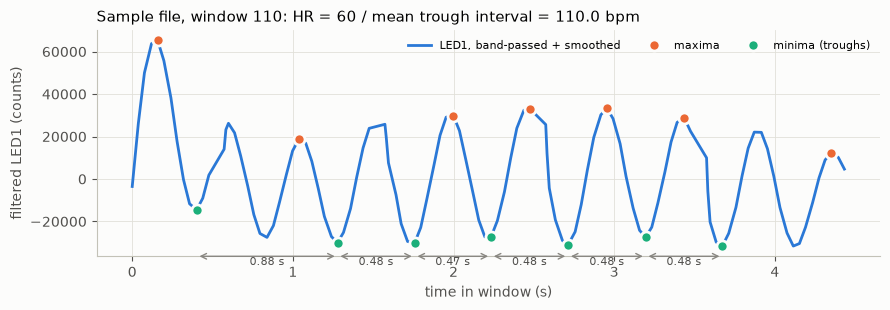

In [9]:
# One window, step by step: what "trough-based HR" and "PA" mean
wid = int(ten['Raw_Window_Index'].iloc[3])
w = sophia_data[sophia_data.raw_window_index == wid].sort_values('row_index')
t = w.timestamp_ms.to_numpy() / 1000; t = t - t[0]
fs = 1 / np.median(np.diff(t)); ny = fs / 2
b_bp, a_bp = butter(4, [0.5 / ny, 3.0 / ny], 'bandpass'); b_lp, a_lp = butter(4, 2.5 / ny, 'low')
sm = matlab_filtfilt(b_lp, a_lp, matlab_filtfilt(b_bp, a_bp, w.led1.to_numpy(float)))
f = get_ppg_features(sm, t, 0.45, 0.45, 0.15)

fig, ax = plt.subplots(figsize=(9, 3.2))
ax.plot(t, sm, color=C_BLUE, lw=2, label='LED1, band-passed + smoothed')
ax.plot(f['max_locs'], f['max_peaks'], 'o', ms=8, color=C_ORANGE, mec='#fcfcfb', mew=2, label='maxima')
ax.plot(f['min_locs'], f['min_peaks'], 'o', ms=8, color=C_AQUA, mec='#fcfcfb', mew=2, label='minima (troughs)')
for a_, b_ in zip(f['min_locs'][:-1], f['min_locs'][1:]):
    ax.annotate('', xy=(b_, f['min_peaks'].min() * 1.15), xytext=(a_, f['min_peaks'].min() * 1.15),
                arrowprops=dict(arrowstyle='<->', color=C_GREY, lw=1))
    ax.text((a_ + b_) / 2, f['min_peaks'].min() * 1.28, f'{b_ - a_:.2f} s', ha='center', fontsize=8, color='#52514e')
ax.set_xlabel('time in window (s)'); ax.set_ylabel('filtered LED1 (counts)')
ax.set_title(f'Sample file, window {wid}: HR = 60 / mean trough interval = {f["HR"]:.1f} bpm', loc='left', fontsize=11)
ax.legend(loc='upper right', fontsize=8, frameon=False, ncol=3)
plt.tight_layout()
FIG_SKIPPED_BEAT = OUT_DIR / 'fig_A1_step1_minpeakdistance_skipped_beat.png'
fig.savefig(FIG_SKIPPED_BEAT, dpi=150, bbox_inches='tight')
plt.show()

**Takeaway:** HR comes from the gaps between troughs (aqua); PA is the mean height of each up- and down-stroke between neighbouring maxima and minima. This window also shows a failure mode of the MATLAB rule itself: the trough near 0.85 s is deleted because a deeper trough sits exactly 0.45 s away (MinPeakDistance counts *within ±0.45 s inclusive*), leaving one 0.88 s gap. One missed beat pulls HR down and inflates SDNN/RMSSD. Both the Python and the MATLAB logic do this, so it is not a porting bug, but it is why single-window HRV needs the quality gate (step 3).

**Step 1 result** (numbers from the cells above):
- Her filters, trough-based HR, SDNN/RMSSD (in **seconds**) and PA definition match the MATLAB logic **exactly** (max difference 0.0 on all 326 shared windows, all 19 checked columns). Caveat: the reference is a Python re-implementation of the `.m` (MATLAB isn't installed here), so this confirms the *logic*; tiny floating-point differences against real MATLAB output are still possible.
- Differences from the MATLAB script are all **additions**, not changes to the signal processing:
  1. **30 s warm-up drop:** windows starting < 30 000 ms on `Timestamp_ms` are skipped. `Timestamp_ms` restarts every session, so this drops the first windows of every session.
  2. **Ambiguous-label drop:** windows whose `Label` is not a single value are skipped.
  3. **Saturation flag:** `LED_Saturated` marks any LED ≥ 524287; flagged windows are **kept**. (Value 0 is not checked.)
  4. **PA ratios:** `PA1_PA2_Ratio`, `PA1_PA3_Ratio`, `PA2_PA3_Ratio` are extra columns (for XGBoost).
- **No signal-quality filter** in her code (or in the MATLAB): every complete window gets features. Step 3 adds one.
- **Watch-outs found while checking** (not differences from MATLAB): `PA*_Ratio` explodes when the denominator PA is ~0 but not exactly 0 (e.g. `PA1_PA2_Ratio` reaches 7.1e11 in Ring 1); her 30 s warm-up rule removes 2 small Ring 4 surveys entirely (2 windows each), which is why Ring 4 has 49 surveys here vs 51 in `RESULTS_SUMMARY.md`.

## Step 2 · Run on Rings 3, 4 and 1

All `*_labeled_continuous.xlsx` files for days 0–10 under each ring folder; `*_new_format*` files and Ring 1's day 12/13 files are skipped. The day key is the **calendar date from `RealTime`** (Ring 4 has two files both named "day5"). Window-level features are cached in `CACHE_DIR` (outside the repo); delete that folder to recompute.

In [10]:
MAX_DAY = 10   # study days 0-10 only (matches Workstream B); drops Ring 1 day 12 and 13

def ring_files(ring_dir):
    fs = sorted(p for p in (DATA_DIR / ring_dir).rglob('*.xlsx')
                if 'new_format' not in p.name and not p.name.startswith('~$'))
    late = [p.name for p in fs if (file_day(p.name) or 0) > MAX_DAY]
    if late:
        print(f'{ring_dir}: skipping {len(late)} file(s) after day {MAX_DAY}: {late}')
    return [p for p in fs if (file_day(p.name) or 0) <= MAX_DAY]

def file_day(name):
    m = re.search(r'_day(\d+)_', name)
    return int(m.group(1)) if m else None

def process_file(ring, path):
    cache = CACHE_DIR / f'{path.stem}__features.csv'
    cache_chk = CACHE_DIR / f'{path.stem}__check.csv'
    if cache.exists() and cache_chk.exists() and cache.stat().st_mtime > path.stat().st_mtime:
        return pd.read_csv(cache, low_memory=False), pd.read_csv(cache_chk)
    data, id_cols, amb, n_rows_raw = run_quietly(load_m3x_file, path)
    feats, check = run_quietly(extract_features, data, id_cols)
    for df in (feats, check):
        df.insert(0, 'ring', ring); df.insert(1, 'file', path.name); df.insert(2, 'file_day', file_day(path.name))
    # extra bookkeeping on the check table: rows in the raw file per window, Survey_ID/Period ambiguity
    raw_rows = data.groupby('raw_window_index').size()
    check['n_rows_raw'] = check['Raw_Window_Index'].map(raw_rows)
    check['n_survey_ids'] = check['Raw_Window_Index'].map(amb['Survey_ID'])
    check['n_periods'] = check['Raw_Window_Index'].map(amb['Period'])
    check['n_rows_file'] = n_rows_raw
    feats.to_csv(cache, index=False); check.to_csv(cache_chk, index=False)
    return feats, check

t0 = time.time()
feat_parts, check_parts = [], []
for ring, folder in RINGS.items():
    for path in ring_files(folder):
        f_, c_ = process_file(ring, path)
        feat_parts.append(f_); check_parts.append(c_)
        print(f'{ring}  {path.name:<60s} windows {len(c_):>5d}   feature rows {len(f_):>5d}')
win = pd.concat(feat_parts, ignore_index=True)
checks = pd.concat(check_parts, ignore_index=True)
print(f'\n{len(win)} feature rows from {checks.file.nunique()} files in {time.time() - t0:.0f} s')

R3  Ring3_PID_102_day0_10_13_26_labeled_continuous.xlsx          windows   164   feature rows   162
R3  Ring3_PID_102_day10_10_27_26_labeled_continuous.xlsx         windows   508   feature rows   508
R3  Ring3_PID_102_day1_10_14_26_labeled_continuous.xlsx          windows   381   feature rows   375
R3  Ring3_PID_102_day2_10_15_26_labeled_continuous.xlsx          windows   263   feature rows   259
R3  Ring3_PID_102_day3_10_16_26_labeled_continuous.xlsx          windows   200   feature rows   196


R3  Ring3_PID_102_day5_10_20_26_labeled_continuous.xlsx          windows   506   feature rows   504
R3  Ring3_PID_102_day6_10_21_26_labeled_continuous.xlsx          windows   143   feature rows   143


R3  Ring3_PID_102_day7_10_22_26_labeled_continuous.xlsx          windows   571   feature rows   571


R3  Ring3_PID_102_day8_10_23_26_labeled_continuous.xlsx          windows   424   feature rows   424


R3  Ring3_PID_102_day9_10_26_26_labeled_continuous.xlsx          windows   438   feature rows   438
R4  Ring4_PID_101_day0_10_13_26_labeled_continuous.xlsx          windows   222   feature rows   220
R4  Ring4_PID_101_day10_10_27_26_labeled_continuous.xlsx         windows   202   feature rows   202
R4  Ring4_PID_101_day1_10_14_26_labeled_continuous.xlsx          windows   798   feature rows   794
R4  Ring4_PID_101_day2_10_15_26_labeled_continuous.xlsx          windows   474   feature rows   472
R4  Ring4_PID_101_day3_10_16_26_labeled_continuous.xlsx          windows   153   feature rows   151
R4  Ring4_PID_101_day4_10_19_26_labeled_continuous.xlsx          windows   538   feature rows   536
R4  Ring4_PID_101_day5_10_20_26_labeled_continuous.xlsx          windows   906   feature rows   901
R4  Ring4_PID_101_day5_10_21_26_labeled_continuous.xlsx          windows   571   feature rows   571
R4  Ring4_PID_101_day7_10_22_26_labeled_continuous.xlsx          windows   528   feature rows   528


In [11]:
# Tidy the window table: date, 2-class label, baseline marker, HRV in ms
win['RealTime'] = pd.to_datetime(win['RealTime'])
win['date'] = win['RealTime'].dt.date.astype(str)
win['is_baseline'] = win['Period'].eq('baseline_since_previous_survey')
win['Label2'] = win['Label'].map(TO_2CLASS)
win['SDNN_LED1_ms'] = win['SDNN_LED1'] * 1000
win['RMSSD_LED1_ms'] = win['RMSSD_LED1'] * 1000
win['ring'] = pd.Categorical(win['ring'], categories=list(RINGS), ordered=True)
win = win.sort_values(['ring', 'RealTime']).reset_index(drop=True)

unknown = sorted(set(win['Label'].dropna()) - set(CLASSES_4))
print('Labels not in the 4 classes:', unknown or 'none')
print('Windows with no Survey_ID:', int(win['Survey_ID'].isna().sum()))
# Files whose name date and RealTime date disagree (sanity check on the day key)
fd = win.groupby('file')['date'].agg(lambda s: sorted(s.unique()))
print('Files spanning more than one calendar date:', {k: v for k, v in fd.items() if len(v) > 1} or 'none')

Labels not in the 4 classes: none
Windows with no Survey_ID: 0
Files spanning more than one calendar date: none


### 2a · Window counts and drops per ring

In [12]:
checks['ring'] = pd.Categorical(checks['ring'], categories=list(RINGS), ordered=True)
status = checks.pivot_table(index='ring', columns='Status', values='Raw_Window_Index', aggfunc='count',
                            fill_value=0, observed=False)
counts = pd.DataFrame({
    'files': checks.groupby('ring', observed=False)['file'].nunique(),
    'days (dates)': win.groupby('ring', observed=False)['date'].nunique(),
    'windows in files': checks.groupby('ring', observed=False).size(),
})
counts = counts.join(status)
counts['dropped in processing loop'] = counts['Complete'] - win.groupby('ring', observed=False).size()
counts['feature rows'] = win.groupby('ring', observed=False).size()
counts['% kept'] = (100 * counts['feature rows'] / counts['windows in files']).round(1)
counts['of which day-0 baseline'] = win.groupby('ring', observed=False)['is_baseline'].sum()
counts['LED saturated (flag, kept)'] = win.groupby('ring', observed=False)['LED_Saturated'].sum()
counts['surveys'] = win.groupby('ring', observed=False)['Survey_ID'].nunique()
counts.index = counts.index.astype(str)
counts.loc['total'] = counts.sum(numeric_only=True)
counts.loc['total', '% kept'] = round(100 * counts.loc['total', 'feature rows'] / counts.loc['total', 'windows in files'], 1)
display(counts)

# Why were windows dropped? (Anisha's statuses, broken down)
inc = checks[checks.Status == 'Skipped_Incomplete']
print('Incomplete windows: rows per window ->', inc['Num_Rows'].value_counts().sort_index().to_dict())
warm = checks[checks.Status.str.startswith('Skipped_First')]
print('Warm-up drops: Start_Time_ms range', int(warm.Start_Time_ms.min()), '-', int(warm.Start_Time_ms.max()),
      '| per file median', int(warm.groupby('file').size().median()))
mixed = checks[checks.Status == 'Skipped_Mixed_Label']
print('Mixed/missing-label drops:', len(mixed), '| of these, label missing entirely:', int(mixed['Label'].isna().sum()))
kept_chk = checks[checks.Status == 'Complete']
print('Kept windows spanning >1 Survey_ID:', int((kept_chk.n_survey_ids > 1).sum()),
      '| spanning >1 Period:', int((kept_chk.n_periods > 1).sum()))

,files,days (dates),windows in files,Complete,Skipped_First_30s,dropped in processing loop,feature rows,% kept,of which day-0 baseline,"LED saturated (flag, kept)",surveys
ring,,,,,,,,,,,
R3,10,10,3598,3580,18,0,3580,99.5,162,18,46
R4,11,11,5005,4988,17,0,4988,99.7,220,7,49
R1,8,8,5154,5140,14,0,5140,99.7,239,129,47
total,29,29,13757,13708,49,0,13708,99.6,621,154,142


Incomplete windows: rows per window -> {}
Warm-up drops: Start_Time_ms range 1842 - 22179 | per file median 2
Mixed/missing-label drops: 0 | of these, label missing entirely: 0
Kept windows spanning >1 Survey_ID: 0 | spanning >1 Period: 0


In [13]:
# Per ring x date (feature rows, warm-up and incomplete drops)
per_day = (checks.assign(kept=checks.Status.eq('Complete'),
                         warmup=checks.Status.str.startswith('Skipped_First'),
                         incomplete=checks.Status.eq('Skipped_Incomplete'),
                         mixed=checks.Status.eq('Skipped_Mixed_Label'))
           .groupby(['ring', 'file_day', 'file'], observed=True)[['kept', 'warmup', 'incomplete', 'mixed']].sum())
dates = win.groupby('file')['date'].first()
per_day = per_day.reset_index()
per_day.insert(2, 'date', per_day['file'].map(dates))
display(per_day.drop(columns='file').set_index(['ring', 'file_day', 'date']))

kept  warmup  incomplete  mixed
ring file_day date                                       
R3   0        2026-10-13   162       2           0      0
     1        2026-10-14   375       6           0      0
     2        2026-10-15   259       4           0      0
     3        2026-10-16   196       4           0      0
     5        2026-10-20   504       2           0      0
     6        2026-10-21   143       0           0      0
     7        2026-10-22   571       0           0      0
     8        2026-10-23   424       0           0      0
     9        2026-10-26   438       0           0      0
     10       2026-10-27   508       0           0      0
R4   0        2026-10-13   220       2           0      0
     1        2026-10-14   794       4           0      0
     2        2026-10-15   472       2           0      0
     3        2026-10-16   151       2           0      0
     4        2026-10-19   536       2           0      0
     5        2026-10-20   901       5           0      0
              2026-10-21   571       0           0      0
     7        2026-10-22   528       0           0      0
     8        2026-10-23   313       0           0      0
     9        2026-10-26   300       0           0      0
     10       2026-10-27   202       0           0      0
R1   0        2026-10-06   239       0           0      0
     1        2026-10-07   738       0           0      0
     3        2026-10-09   475       2           0      0
     4        2026-10-12   631       0           0      0
     7        2026-10-15   853       6           0      0
     8        2026-10-16   892       4           0      0
     9        2026-10-19   686       2           0      0
     10       2026-10-20   626       0           0      0

### 2b · Windows per class (before any quality gate)

In [14]:
cls = win.pivot_table(index='ring', columns='Label', values='Raw_Window_Index', aggfunc='count',
                      fill_value=0, observed=False)[CLASSES_4]
cls2 = win.pivot_table(index='ring', columns='Label2', values='Raw_Window_Index', aggfunc='count',
                       fill_value=0, observed=False)[['good', 'bad']]
surv = (win.groupby(['ring', 'Label'], observed=False)['Survey_ID'].nunique().unstack()[CLASSES_4]
        .add_suffix(' (surveys)'))
display(cls.join(cls2).join(surv))

,relax,eustress,distress,eustress+distress,good,bad,relax (surveys),eustress (surveys),distress (surveys),eustress+distress (surveys)
ring,,,,,,,,,,
R3,399,530,272,2379,929,2651,14,13,6,25
R4,1708,882,1199,1199,2590,2398,20,8,13,16
R1,3331,25,25,1759,3356,1784,35,2,2,29


### 2c · Sample of the window-level feature table

In [15]:
FAST = ['HR_LED1', 'SDNN_LED1_ms', 'RMSSD_LED1_ms', 'n_rr_LED1', 'PA1', 'PA2', 'PA3',
        'PA_STD_LED1', 'PA_RMSSD_LED1', 'PA_CV_LED1', 'PA_CV_LED2', 'PA_CV_LED3',
        'PA1_PA2_mean_diff', 'PA1_PA3_mean_diff', 'PA2_PA3_mean_diff', 'PA1_PA2_Ratio']
META = ['ring', 'date', 'RealTime', 'Survey_ID', 'Period', 'Label', 'Label2', 'Acc_Total_STD_g']
sample = win.groupby('ring', observed=True).sample(3, random_state=1)
display(sample[META + FAST].round(3))

desc = win.groupby('ring', observed=True)[['HR_LED1', 'SDNN_LED1_ms', 'RMSSD_LED1_ms', 'PA1', 'Acc_Total_STD_g']].describe(
    percentiles=[.1, .5, .9]).round(2)
display(desc)
nan_share = win.groupby('ring', observed=True)[['HR_LED1', 'SDNN_LED1', 'RMSSD_LED1', 'PA1', 'PA_CV_LED1']].apply(
    lambda d: d.isna().mean().mul(100).round(1))
print('% of windows with NaN (too few extrema / intervals):'); display(nan_share)

/var/folders/z8/_hwr9_y500b4gkf8_zybl7v40000gn/T/ipykernel_5149/1762368782.py:6: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(sample[META + FAST].round(3))


,ring,date,RealTime,Survey_ID,Period,Label,Label2,Acc_Total_STD_g,HR_LED1,SDNN_LED1_ms,RMSSD_LED1_ms,n_rr_LED1,PA1,PA2,PA3,PA_STD_LED1,PA_RMSSD_LED1,PA_CV_LED1,PA_CV_LED2,PA_CV_LED3,PA1_PA2_mean_diff,PA1_PA3_mean_diff,PA2_PA3_mean_diff,PA1_PA2_Ratio
349,R3,2026-10-14,2026-10-14 16:05:14.582,102-20261014T151220-B88E7012,past_5to30min,eustress+distress,bad,0.169,86.518,50.290,87.516,6,1498.903,1438.526,180.852,694.660,693.158,0.463,0.740,0.489,60.378,1318.051,1257.674,1.042
3323,R3,2026-10-27,2026-10-27 14:31:09.257,102-20261027T140831-420CC58C,past_5to30min,eustress+distress,bad,0.349,82.164,325.329,392.750,4,4727.770,5789.836,609.740,3294.944,3039.478,0.697,0.865,0.812,-1062.067,4118.029,5180.096,0.817
93,R3,2026-10-13,2026-10-13 11:20:03.437,R_6ZmYv2PgrGwsjbb,baseline_since_previous_survey,eustress+distress,bad,0.218,66.574,82.714,135.073,4,1509.934,1118.020,132.688,524.541,539.492,0.347,0.816,1.082,391.914,1377.246,985.332,1.351
8273,R4,2026-10-26,2026-10-26 12:37:42.462,101-20261026T131251-1B625021,before_30to60min,relax,good,0.137,60.621,305.409,330.580,4,18737.950,3490.161,149.611,7052.526,7181.540,0.376,0.477,0.434,15247.789,18588.339,3340.550,5.369
7145,R4,2026-10-21,2026-10-21 17:35:38.371,101-20261021T180855-FEE3DAA0,before_30to60min,distress,bad,0.016,78.906,137.335,149.380,5,418.179,623.718,12.992,132.068,133.604,0.316,0.296,0.164,-205.538,405.188,610.726,0.670
6055,R4,2026-10-20,2026-10-20 13:43:50.534,101-20261020T140457-CFEFC686,past_5to30min,distress,bad,0.845,78.023,300.568,447.524,5,1728.451,6106.461,206.023,1695.854,1090.919,0.981,0.844,0.299,-4378.010,1522.428,5900.438,0.283
10545,R1,2026-10-12,2026-10-12 14:33:38.181,104-20261012T145850-043090BB,before_30to60min,relax,good,0.017,61.560,199.410,327.060,3,808.693,267.147,9.357,196.216,181.357,0.243,0.629,0.250,541.546,799.336,257.790,3.027
11242,R1,2026-10-15,2026-10-15 15:08:41.637,104-20261015T155902-D9173C51,before_30to60min,eustress+distress,bad,0.008,71.259,30.757,28.065,4,4949.683,836.892,14.737,854.486,757.121,0.173,0.202,0.216,4112.792,4934.946,822.154,5.914
13506,R1,2026-10-20,2026-10-20 11:39:15.016,104-20261020T114746-83448896,past_5to30min,relax,good,0.103,67.265,194.842,279.842,4,766.056,1161.670,13.319,439.680,441.388,0.574,1.657,1.086,-395.614,752.737,1148.350,0.659


HR_LED1                                                   SDNN_LED1_ms                                                       RMSSD_LED1_ms                                                        \
       count   mean    std    min    10%    50%    90%     max        count    mean     std   min    10%     50%     90%      max         count    mean     std  min     10%     50%     90%      max   
ring                                                                                                                                                                                                    
R3    3580.0  74.56  12.80  27.76  59.36  74.20  90.77  122.20       3570.0  189.46  139.75  2.31  51.09  161.71  351.14  1040.36        3570.0  258.67  200.75  4.0   67.74  210.80  504.51  1779.39   
R4    4988.0  70.30  14.52  21.38  50.70  71.36  88.33  119.32       4964.0  284.80  188.19  1.41  88.97  243.72  536.56  1644.73        4964.0  391.92  271.06  2.0  119.49  332.41  743.59  2326.00   
R1    5140.0  70.04  11.45  24.97  56.23  70.46  84.03  109.37       5128.0  193.81  159.27  0.00  44.79  150.46  403.59  1330.07        5128.0  271.06  229.84  0.0   55.84  210.04  577.41  1881.00   

         PA1                                                                    Acc_Total_STD_g                                           
       count      mean       std    min      10%       50%       90%        max           count  mean   std  min   10%   50%   90%   max  
ring                                                                                                                                      
R3    3580.0   7967.76  19082.05   0.00   498.21   1684.32  19176.18  183055.74          3580.0  0.19  0.28  0.0  0.01  0.07  0.57  1.70  
R4    4988.0  36405.62  35737.01  74.50  1480.40  25375.57  87677.56  194225.29          4988.0  0.49  0.45  0.0  0.03  0.35  1.18  3.14  
R1    5140.0   2213.60   6835.67   5.09   216.52    864.58   3981.88  167915.02          5140.0  0.18  0.29  0.0  0.01  0.06  0.50  4.77

% of windows with NaN (too few extrema / intervals):


,HR_LED1,SDNN_LED1,RMSSD_LED1,PA1,PA_CV_LED1
ring,,,,,
R3,0.0,0.3,0.3,0.0,0.0
R4,0.0,0.5,0.5,0.0,0.0
R1,0.0,0.2,0.2,0.0,0.0


## Step 3 · Clean-pulse quality gate (A1 addition: not part of Anisha's code)

Her code (and the MATLAB) gives every complete window a feature row, including windows where the hand is moving or the pulse is not visible. This step **adds a separate quality gate**. It does not change any feature value; it only marks each window `usable` or not. **Every result from here on is computed twice: on all windows and on usable windows only.**

A window is usable only if **all five** rules hold:

| # | Rule | Why |
|---|---|---|
| 1 | No LED1 sample at 524287 (sensor ceiling) or 0 | clipped light → the pulse shape is cut off |
| 2 | Low motion: `Acc_Total_STD_g` below a cut-off chosen to keep the same share of windows as "SD of √(X²+Y²+Z²) < 40 mg" | movement swamps the optical pulse |
| 3 | Periodic pulse: autocorrelation of band-passed LED1 has a peak > 0.4 at a lag of 40–180 bpm | a real pulse repeats itself |
| 4 | HR from beat intervals within 10% of HR from that autocorrelation peak | the beat finder and the "repetition rate" agree |
| 5 | Steady beats: ≥ 3 beat intervals and interval CV < 0.15 | no skipped or doubled beats |

To get the inputs for rules 1, 3, 4 and 5, each window's LED1 is re-filtered with **her exact calls** (`butter`, `matlab_filtfilt`, `get_ppg_features`) so the beat intervals are the same ones her HR came from (checked below).

**Autocorrelation details:** correlation of the band-passed window with itself shifted by *k* samples, normalised by overlap length; the peak is the first local maximum in the 40–180 bpm lag range that reaches ≥ 90% of the highest one (so a two-beat lag isn't picked instead of one beat), refined by a parabola through the 3 points around it.

In [16]:
LED1_CEILING = 524287
ACF_MIN, HR_AGREE_MAX, RR_CV_MAX, MIN_RR = 0.4, 0.10, 0.15, 3
MAG_SD_MAX_MG = 40          # earlier-pass motion rule, used only to calibrate rule 2

def acf_peak_hr(x, fs):
    """Peak of the autocorrelation in the 40-180 bpm lag range -> (peak value, HR in bpm)."""
    x = np.asarray(x, float); x = x - x.mean(); n = len(x); v = np.dot(x, x) / n
    if not np.isfinite(v) or v == 0:
        return np.nan, np.nan
    kmin = int(np.ceil(fs * 60 / 180)); kmax = min(int(np.floor(fs * 60 / 40)), n - 3)
    r = np.full(kmax + 2, np.nan)
    for k in range(1, kmax + 2):
        r[k] = np.dot(x[:-k], x[k:]) / (n - k) / v
    cand = [k for k in range(max(kmin, 2), kmax + 1) if r[k] >= r[k - 1] and r[k] >= r[k + 1]]
    if not cand:
        return np.nan, np.nan
    best = max(r[k] for k in cand)
    k = next(k for k in cand if r[k] >= best - 0.1 * abs(best))   # 'within 10% of the best peak'
    den = r[k - 1] - 2 * r[k] + r[k + 1]
    k_ref = k + (0.5 * (r[k - 1] - r[k + 1]) / den if den != 0 else 0.0)
    return r[k], 60 * fs / k_ref

def gate_inputs(path):
    """Per window: LED1 saturation, accelerometer-magnitude SD, autocorrelation HR, her beat intervals."""
    cache = CACHE_DIR / f'{path.stem}__gate.csv'
    if cache.exists() and cache.stat().st_mtime > path.stat().st_mtime:
        return pd.read_csv(cache)
    data, _, _, _ = run_quietly(load_m3x_file, path)
    data = data.sort_values(['raw_window_index', 'row_index'], kind='stable')
    rows = []
    for wid, w in data.groupby('raw_window_index', sort=True):
        if len(w) != expected_samples or not np.array_equal(w['row_index'].to_numpy(), expected_row_index):
            continue
        t_sec = w['timestamp_ms'].to_numpy() / 1000; t_local = t_sec - t_sec[0]
        dt = np.diff(t_sec); valid_dt = dt[np.isfinite(dt) & (dt > 0)]
        if valid_dt.size == 0:
            continue
        fs = 1 / np.median(valid_dt); nyq = fs / 2
        # --- her exact filter + beat calls (LED1) ---
        b_bp, a_bp = butter(4, [low_cutoff / nyq, high_cutoff / nyq], btype='bandpass')
        b_lp, a_lp = butter(4, fc_smooth / nyq, btype='low')
        led1 = w['led1'].to_numpy()
        led1_filt = matlab_filtfilt(b_bp, a_bp, led1); led1_smooth = matlab_filtfilt(b_lp, a_lp, led1_filt)
        f1 = get_ppg_features(led1_smooth, t_local, min_peak_distance_max, min_peak_distance_min,
                              min_time_after_min_to_max)
        rr = np.diff(f1['min_locs']); rr = rr[np.isfinite(rr) & (rr > 0)]
        # --- gate inputs ---
        peak, hr_acf = acf_peak_hr(led1_filt, fs)
        mag_mg = np.sqrt(w['accx'] ** 2 + w['accy'] ** 2 + w['accz'] ** 2).to_numpy() * 1000
        rows.append({'file': path.name, 'Raw_Window_Index': int(wid),
                     'led1_saturated': bool(((led1 >= LED1_CEILING) | (led1 <= 0)).any()),
                     'acc_mag_sd_mg': np.std(mag_mg, ddof=1), 'acf_peak': peak, 'HR_acf': hr_acf,
                     'HR_check': f1['HR'], 'rr_s': ' '.join(f'{v:.4f}' for v in rr)})
    out = pd.DataFrame(rows); out.to_csv(cache, index=False)
    return out

t0 = time.time()
gate_in = pd.concat([gate_inputs(p) for folder in RINGS.values() for p in ring_files(folder)], ignore_index=True)
gw = win.merge(gate_in, on=['file', 'Raw_Window_Index'], how='left', validate='1:1')
gw['rr'] = gw['rr_s'].fillna('').map(lambda s: np.array([float(v) for v in s.split()]) if s else np.array([]))
assert gw['acf_peak'].notna().sum() > 0 and gw['HR_check'].notna().sum() == gw['HR_LED1'].notna().sum()
assert np.allclose(gw['HR_check'], gw['HR_LED1'], equal_nan=True), 're-filtered LED1 must reproduce her HR'
assert (gw['rr'].map(len) == gw['n_rr_LED1']).all()
print(f'gate inputs for {len(gw)} windows in {time.time() - t0:.0f} s; re-filtered HR matches her HR_LED1 exactly.')

Ring_01_PID_104: skipping 2 file(s) after day 10: ['Ring1_PID_104_day12_10_22_26_labeled_continuous.xlsx', 'Ring1_PID_104_day13_10_23_26_labeled_continuous.xlsx']
gate inputs for 13708 windows in 0 s; re-filtered HR matches her HR_LED1 exactly.


### 3a · Calibrate the motion rule (rule 2) to the team's `Acc_Total_STD_g`

In [17]:
gw['motion_sum_mg'] = gw['Acc_Total_STD_g'] * 1000          # team's motion measure, in mg
keep_share = (gw['acc_mag_sd_mg'] < MAG_SD_MAX_MG).mean()     # share kept by the earlier-pass rule (all rings pooled)
MOTION_SUM_MAX_MG = round(float(np.quantile(gw['motion_sum_mg'], keep_share)), 1)
print(f'"SD of magnitude < {MAG_SD_MAX_MG} mg" keeps {keep_share:.1%} of all windows.')
print(f'Same share on Acc_Total_STD_g -> cut-off {MOTION_SUM_MAX_MG} mg ({MOTION_SUM_MAX_MG / 1000:.4f} g).')

a = gw['acc_mag_sd_mg'] < MAG_SD_MAX_MG; b = gw['motion_sum_mg'] < MOTION_SUM_MAX_MG
cal = pd.DataFrame({'% kept, magnitude-SD rule': a.groupby(gw.ring, observed=True).mean() * 100,
                    '% kept, Acc_Total_STD_g rule': b.groupby(gw.ring, observed=True).mean() * 100,
                    '% windows where both rules agree': (a == b).groupby(gw.ring, observed=True).mean() * 100}).round(1)
display(cal)

"SD of magnitude < 40 mg" keeps 65.6% of all windows.
Same share on Acc_Total_STD_g -> cut-off 285.2 mg (0.2852 g).


,"% kept, magnitude-SD rule","% kept, Acc_Total_STD_g rule",% windows where both rules agree
ring,,,
R3,77.2,76.6,88.0
R4,42.8,42.9,87.5
R1,79.6,80.0,88.4


### 3b · Which rules remove windows

In [18]:
hr_rel = (gw['HR_LED1'] - gw['HR_acf']).abs() / gw['HR_acf']
rr_cv = gw['rr'].map(lambda r: r.std(ddof=1) / r.mean() if len(r) >= 2 else np.nan)
gw['rr_cv'] = rr_cv
gw['g1_no_saturation'] = ~gw['led1_saturated']
gw['g2_low_motion'] = gw['motion_sum_mg'] < MOTION_SUM_MAX_MG
gw['g3_periodic'] = gw['acf_peak'] > ACF_MIN
gw['g4_hr_agrees'] = hr_rel <= HR_AGREE_MAX
gw['g5_steady_beats'] = (gw['n_rr_LED1'] >= MIN_RR) & (rr_cv < RR_CV_MAX)
RULES = ['g1_no_saturation', 'g2_low_motion', 'g3_periodic', 'g4_hr_agrees', 'g5_steady_beats']
gw['usable'] = gw[RULES].all(axis=1)
gw['nonwear_flag'] = gw['motion_sum_mg'] < 8.0               # repo loader's non-wear rule (flag only)

rule_tab = (gw.groupby('ring', observed=True)[RULES + ['usable']].mean() * 100).round(1)
rule_tab.columns = ['1 no saturation', '2 low motion', '3 periodic', '4 HR agrees', '5 steady beats', 'ALL FIVE (usable)']
rule_tab['usable windows'] = gw.groupby('ring', observed=True)['usable'].sum()
rule_tab['non-wear flag (<8 mg)'] = gw.groupby('ring', observed=True)['nonwear_flag'].sum()
rule_tab['non-wear AND usable'] = (gw['nonwear_flag'] & gw['usable']).groupby(gw.ring, observed=True).sum()
print('% of windows passing each rule:')
display(rule_tab)

% of windows passing each rule:


,1 no saturation,2 low motion,3 periodic,4 HR agrees,5 steady beats,ALL FIVE (usable),usable windows,non-wear flag (<8 mg),non-wear AND usable
ring,,,,,,,,,
R3,99.5,76.6,58.9,47.9,35.4,25.3,904,712,376
R4,100.0,42.9,33.9,25.9,14.5,6.6,331,135,67
R1,100.0,80.0,54.2,56.0,42.2,31.8,1633,644,421


### 3c · % usable windows per ring × class

In [19]:
def usable_pct(col, order):
    t = gw.groupby(['ring', col], observed=True)['usable'].agg(['size', 'sum'])
    t['pct'] = (100 * t['sum'] / t['size']).round(1)
    t['cell'] = t['pct'].map('{:.1f}%'.format) + ' (' + t['sum'].astype(int).astype(str) + '/' + t['size'].astype(str) + ')'
    return t['cell'].unstack()[order], t['pct'].unstack()[order]

u4, u4_pct = usable_pct('Label', CLASSES_4)
u2, u2_pct = usable_pct('Label2', ['good', 'bad'])
usable_table = u4.join(u2)
usable_table['all classes'] = (gw.groupby('ring', observed=True)['usable'].mean() * 100).round(1).map('{:.1f}%'.format)
display(usable_table)
usable_long = gw.groupby(['ring', 'Label'], observed=True)['usable'].agg(windows='size', usable='sum').reset_index()
usable_long.to_csv(OUT_DIR / 'A1_usable_windows_by_ring_class.csv', index=False)

,relax,eustress,distress,eustress+distress,good,bad,all classes
ring,,,,,,,
R3,37.1% (148/399),24.0% (127/530),33.5% (91/272),22.6% (538/2379),29.6% (275/929),23.7% (629/2651),25.3%
R4,7.7% (131/1708),7.1% (63/882),5.8% (69/1199),5.7% (68/1199),7.5% (194/2590),5.7% (137/2398),6.6%
R1,35.3% (1177/3331),52.0% (13/25),48.0% (12/25),24.5% (431/1759),35.5% (1190/3356),24.8% (443/1784),31.8%


### 3d · Surveys remaining per ring × class

A survey counts for a class if it has a **survey × label** segment with **≥ 3 windows** (all windows) or **≥ 3 usable windows** (gated). Cells with **fewer than 3 surveys are flagged ⚠**; their comparisons are still computed in step 5 but carry the `n<3` flag.

In [20]:
MIN_WIN = 3
gw['unit'] = gw['Survey_ID'].astype(str) + ' | ' + gw['Label'].astype(str)

def surveys_per_class(d, col, order):
    u = d.groupby(['ring', 'unit'], observed=True).agg(n=('Raw_Window_Index', 'size'), cls=(col, 'first'),
                                                      sid=('Survey_ID', 'first'))
    u = u[u.n >= MIN_WIN]
    return u.groupby(['ring', 'cls'], observed=True)['sid'].nunique().unstack().reindex(columns=order).fillna(0).astype(int)

def cell(n_all, n_g):
    return f'{n_all} → {n_g}' + (' ⚠' if n_g < 3 else '')

sc = {}
for col, order in (('Label', CLASSES_4), ('Label2', ['good', 'bad'])):
    a_ = surveys_per_class(gw, col, order); g_ = surveys_per_class(gw[gw.usable], col, order).reindex_like(a_).fillna(0).astype(int)
    sc[col] = (a_, g_)
survey_counts = pd.concat([pd.DataFrame({c: [cell(sc[col][0].loc[r, c], sc[col][1].loc[r, c]) for r in sc[col][0].index]
                                         for c in sc[col][0].columns}, index=sc[col][0].index)
                           for col in ('Label', 'Label2')], axis=1)
survey_counts['surveys, all → gated'] = [
    f"{gw[gw.ring == r].groupby('unit').filter(lambda g: len(g) >= MIN_WIN)['Survey_ID'].nunique()} → "
    f"{gw[(gw.ring == r) & gw.usable].groupby('unit').filter(lambda g: len(g) >= MIN_WIN)['Survey_ID'].nunique()}"
    for r in survey_counts.index]
print('Surveys per class: all windows → gated (⚠ = fewer than 3 surveys after the gate)')
display(survey_counts)
pd.concat({'all': sc['Label'][0].join(sc['Label2'][0]), 'gated': sc['Label'][1].join(sc['Label2'][1])},
          names=['windows']).to_csv(OUT_DIR / 'A1_surveys_by_ring_class.csv')

Surveys per class: all windows → gated (⚠ = fewer than 3 surveys after the gate)


,relax,eustress,distress,eustress+distress,good,bad,"surveys, all → gated"
ring,,,,,,,
R3,14 → 14,13 → 12,6 → 3,25 → 21,26 → 25,30 → 24,46 → 43
R4,20 → 12,8 → 7,13 → 7,14 → 8,26 → 19,25 → 15,47 → 33
R1,34 → 34,2 → 2 ⚠,2 → 2 ⚠,28 → 23,34 → 34,30 → 25,45 → 43


### 3e · HRV before vs after the gate

Real resting RMSSD is usually tens of ms. If the gated median is still **> 150 ms**, the HRV features for that ring are marked **low confidence** in every table below.

Caveat: rule 5 (interval CV < 0.15) selects windows *on* beat-interval variability, so gated SDNN/RMSSD are capped by the gate itself. Gated HRV differences between classes should be read with that in mind.

In [21]:
HRV_IMPLAUSIBLE_MS = 150
def hrv_summary(d):
    return pd.Series({'windows': len(d), 'median SDNN (ms)': d['SDNN_LED1_ms'].median(),
                      'median RMSSD (ms)': d['RMSSD_LED1_ms'].median()})
hrv_cmp = pd.concat({'all windows': gw.groupby('ring', observed=True).apply(hrv_summary),
                     'gated': gw[gw.usable].groupby('ring', observed=True).apply(hrv_summary)}, axis=1).round(1)
hrv_cmp[('gated', 'HRV confidence')] = np.where(hrv_cmp[('gated', 'median RMSSD (ms)')] > HRV_IMPLAUSIBLE_MS,
                                               'LOW (RMSSD > 150 ms)', 'ok')
display(hrv_cmp)
HRV_LOW = {('gated', r): hrv_cmp.loc[r, ('gated', 'median RMSSD (ms)')] > HRV_IMPLAUSIBLE_MS for r in hrv_cmp.index}
HRV_LOW.update({('all', r): hrv_cmp.loc[r, ('all windows', 'median RMSSD (ms)')] > HRV_IMPLAUSIBLE_MS for r in hrv_cmp.index})
HRV_LOW[('gated', 'ALL')] = gw.loc[gw.usable, 'RMSSD_LED1_ms'].median() > HRV_IMPLAUSIBLE_MS
HRV_LOW[('all', 'ALL')] = gw['RMSSD_LED1_ms'].median() > HRV_IMPLAUSIBLE_MS
print('HRV marked low confidence for:', [k for k, v in HRV_LOW.items() if v] or 'none')

all windows                                      gated                                                  
         windows median SDNN (ms) median RMSSD (ms) windows median SDNN (ms) median RMSSD (ms) HRV confidence
ring                                                                                                         
R3        3580.0            161.7             210.8   904.0             66.8              86.2             ok
R4        4988.0            243.7             332.4   331.0             62.1              84.7             ok
R1        5140.0            150.5             210.0  1633.0             63.1              81.6             ok

HRV marked low confidence for: [('all', 'R3'), ('all', 'R4'), ('all', 'R1'), ('all', 'ALL')]


### 3f · Note for the team: the 0.45 s MinPeakDistance rule can skip beats

Both the MATLAB script and Anisha's port find troughs with `MinPeakDistance = 0.45 s`, and MATLAB deletes any trough **within ±0.45 s inclusive** of a deeper one. When two troughs are ~0.45 s apart (fast HR, or timing jitter at 25 Hz), one is dropped and the window gets one long interval. That **lowers HR and inflates SDNN/RMSSD** for that window. This is not a porting bug; Python and MATLAB agree exactly (step 1). The figure is the step-1 example; the table counts how often a window has a likely skipped beat (longest interval ≥ 1.6 × shortest).

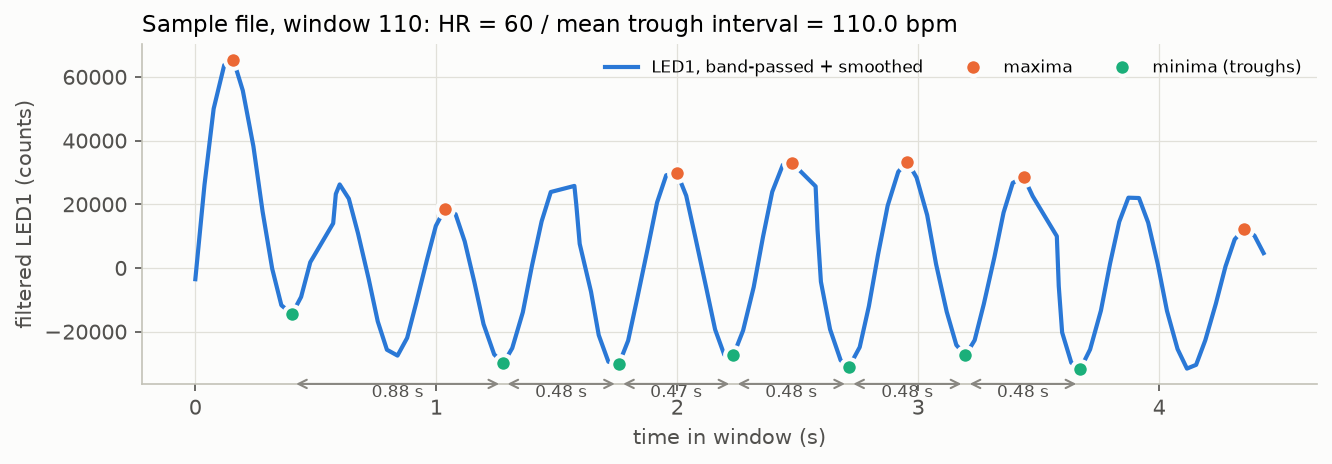

,% windows with likely skipped beat (all),"median RMSSD (ms), windows WITH skip","median RMSSD (ms), windows without",% with skipped beat after gate
ring,,,,
R3,50.6,330.3,113.8,0.0
R4,72.3,401.5,151.1,0.0
R1,43.8,385.7,111.7,0.0


In [22]:
from IPython.display import Image
display(Image(filename=str(FIG_SKIPPED_BEAT), width=760))
has2 = gw['rr'].map(len) >= 2
skip = gw['rr'].map(lambda r: len(r) >= 2 and r.max() / r.min() >= 1.6)
skip_tab = pd.DataFrame({
    '% windows with likely skipped beat (all)': (skip[has2].groupby(gw.ring[has2], observed=True).mean() * 100),
    'median RMSSD (ms), windows WITH skip': gw[skip].groupby('ring', observed=True)['RMSSD_LED1_ms'].median(),
    'median RMSSD (ms), windows without': gw[has2 & ~skip].groupby('ring', observed=True)['RMSSD_LED1_ms'].median(),
    '% with skipped beat after gate': (skip[gw.usable].groupby(gw.ring[gw.usable], observed=True).mean() * 100),
}).round(1)
display(skip_tab)

## Step 4 · One value per survey, three normalisations

- **Unit = survey × label segment** (agreed decision). Value = **median** of the segment's windows (all windows, or usable windows for the gated version). A segment needs **≥ 3 windows**.
- **raw**: feature as extracted (SDNN/RMSSD in ms).
- **per-person**: robust z within ring, `(x − ring median) / ring IQR`, applied to windows before taking the survey median.
- **per-day**: robust z within ring × calendar date, same formula. Days with < 10 windows in the set get no per-day value (too few to estimate the day's level).
- **Pooled RMSSD (A1 extra, not in Anisha's code):** within each window, take successive differences of its beat intervals (**never across the gap between windows**); pool those differences over all windows of the segment; RMSSD = √mean(diff²). Needs ≥ 5 differences. Normalisation for this survey-level feature: per-person = log(segment / ring pooled RMSSD), per-day = log(segment / that day's pooled RMSSD).

Note: per-person normalisation is a single positive linear rescale per ring, so **within one ring its Cliff's δ is identical to raw** (checked in step 5). It matters only for the pooled "all rings" rows.

In [23]:
FEATURE_GROUPS = {
    'HR_LED1': 'HR', 'SDNN_LED1_ms': 'HRV', 'RMSSD_LED1_ms': 'HRV',
    'PA1': 'PA', 'PA2': 'PA', 'PA3': 'PA',
    **{f'{m}_LED{k}': 'PA variability' for m in ('PA_STD', 'PA_RMSSD', 'PA_CV') for k in (1, 2, 3)},
    **{f'{p}_{s}': 'PA difference' for p in ('PA1_PA2', 'PA1_PA3', 'PA2_PA3') for s in ('mean_diff', 'AbsDiff')},
    **{f'{p}_Ratio': 'PA ratio (Anisha extra)' for p in ('PA1_PA2', 'PA1_PA3', 'PA2_PA3')},
}
WIN_FEATURES = list(FEATURE_GROUPS)
POOLED = 'pooled_RMSSD_LED1_ms'
FEATURE_GROUPS[POOLED] = 'HRV (A1 extra)'
ALL_FEATURES = WIN_FEATURES + [POOLED]
HRV_FEATURES = ['SDNN_LED1_ms', 'RMSSD_LED1_ms', POOLED]
NORMS = ['raw', 'person', 'day']
MIN_WIN_PER_DAY = 10

def robust_z(d, cols, by):
    g = d.groupby(by, observed=True)[cols]
    med = g.transform('median')
    iqr = g.transform('quantile', q=0.75) - g.transform('quantile', q=0.25)
    n = d.groupby(by, observed=True)[cols[0]].transform('size')
    z = (d[cols] - med) / iqr.where(iqr > 0)
    return z.where(n >= (MIN_WIN_PER_DAY if by != 'ring' else 1))

def pooled_rmssd(rr_list, min_diffs=5):
    diffs = [np.diff(r) for r in rr_list if len(r) >= 2]
    d = np.concatenate(diffs) if diffs else np.array([])
    return np.sqrt(np.mean(d ** 2)) * 1000 if d.size >= min_diffs else np.nan

def build_survey_tables(d):
    keys = ['ring', 'unit']
    meta = d.groupby(keys, observed=True).agg(
        Survey_ID=('Survey_ID', 'first'), Label=('Label', 'first'), Label2=('Label2', 'first'),
        date=('date', 'first'), n_dates=('date', 'nunique'), n_windows=('Raw_Window_Index', 'size'),
        Stress_0to100=('Stress_0to100', 'first'), is_baseline=('is_baseline', 'first'),
        start=('RealTime', 'min'))
    meta = meta[meta.n_windows >= MIN_WIN]
    p_unit = d.groupby(keys, observed=True)['rr'].apply(lambda s: pooled_rmssd(list(s)))
    p_day = d.groupby(['ring', 'date'], observed=True)['rr'].apply(lambda s: pooled_rmssd(list(s)))
    p_ring = d.groupby('ring', observed=True)['rr'].apply(lambda s: pooled_rmssd(list(s)))
    out = {}
    for norm in NORMS:
        if norm == 'raw':
            vals = d[WIN_FEATURES]
        elif norm == 'person':
            vals = robust_z(d, WIN_FEATURES, 'ring')
        else:
            vals = robust_z(d, WIN_FEATURES, ['ring', 'date'])
        med = vals.join(d[keys]).groupby(keys, observed=True)[WIN_FEATURES].median()
        t = meta.join(med, how='left')
        pu = p_unit.reindex(t.index)
        if norm == 'raw':
            t[POOLED] = pu.values
        elif norm == 'person':
            t[POOLED] = np.log(pu.values / t.index.get_level_values('ring').map(p_ring).to_numpy(float))
        else:
            day_ref = [p_day.get((r, dt), np.nan) for r, dt in zip(t.index.get_level_values('ring'), t['date'])]
            t[POOLED] = np.log(pu.values / np.array(day_ref, float))
        out[norm] = t
    return out

GATES = {'all': gw, 'gated': gw[gw.usable]}
SURV = {(g, n): tab for g, d in GATES.items() for n, tab in build_survey_tables(d).items()}

summ = []
for g in GATES:
    t = SURV[(g, 'raw')]
    for r in RINGS:
        tr = t.loc[r]
        summ.append({'windows': 'all windows' if g == 'all' else 'gated', 'ring': r, 'segments': len(tr),
                     'surveys': tr['Survey_ID'].nunique(), 'segments spanning 2 dates': int((tr.n_dates > 1).sum()),
                     'median windows / segment': tr['n_windows'].median(),
                     'segments with per-day value': int(SURV[(g, 'day')].loc[r]['HR_LED1'].notna().sum()),
                     'median pooled RMSSD (ms)': round(tr[POOLED].median(), 1)})
display(pd.DataFrame(summ).set_index(['windows', 'ring']))

segments  surveys  segments spanning 2 dates  median windows / segment  segments with per-day value  median pooled RMSSD (ms)
windows     ring                                                                                                                               
all windows R3          58       46                          0                      49.5                           58                     263.8
            R4          55       47                          0                     117.0                           55                     421.5
            R1          66       45                          0                      75.0                           66                     330.8
gated       R3          50       43                          0                      11.5                           50                     100.2
            R4          34       33                          0                       6.5                           33                      96.7
            R1          61       43                          0                      18.0                           61                     109.8

**Why per-day normalisation matters here:** days differ in level, and a day's surveys tend to share one label, so "class" and "day" are tangled. The table shows both (gated windows).

In [24]:
g_ = gw[gw.usable]
day_lvl = g_.groupby(['ring', 'date'], observed=True).agg(n=('HR_LED1', 'size'), hr=('HR_LED1', 'median'),
                                                          rmssd=('RMSSD_LED1_ms', 'median'))
day_lvl = day_lvl[day_lvl.n >= MIN_WIN_PER_DAY]
seg_ = SURV[('gated', 'raw')].reset_index()
mix = seg_.groupby(['ring', 'date'], observed=True)['Label2'].agg(lambda s: s.value_counts(normalize=True).max())
day_tab = pd.DataFrame({
    'days with ≥10 usable windows': day_lvl.groupby('ring', observed=True).size(),
    'daily median HR, min–max (bpm)': day_lvl.groupby('ring', observed=True)['hr'].agg(lambda s: f'{s.min():.0f}–{s.max():.0f}'),
    'daily median HR range (bpm)': day_lvl.groupby('ring', observed=True)['hr'].agg(lambda s: s.max() - s.min()).round(1),
    'daily median RMSSD range (ms)': day_lvl.groupby('ring', observed=True)['rmssd'].agg(lambda s: s.max() - s.min()).round(1),
    'days where ≥80% of segments share one 2-class label': mix.groupby('ring', observed=True).agg(lambda s: f'{(s >= 0.8).sum()} / {len(s)}'),
})
display(day_tab)

,days with ≥10 usable windows,"daily median HR, min–max (bpm)",daily median HR range (bpm),daily median RMSSD range (ms),days where ≥80% of segments share one 2-class label
ring,,,,,
R3,10,63–91,28.4,42.9,2 / 10
R4,10,65–81,15.8,33.5,6 / 11
R1,8,64–77,12.8,35.6,3 / 8


## Step 5 · Effect sizes per feature × ring × comparison

- **Cliff's δ** = P(A > B) − P(A < B) over survey segments of class A vs class B. Range −1…+1; **positive means class A is higher**. Rough guide: |δ| ≈ 0.15 small, 0.33 medium, 0.47 large.
- **95% CI**: 2000 bootstrap resamples of **whole surveys** (`Survey_ID`), so windows and segments of one survey always move together.
- **Comparisons:** the 6 four-class pairs + good vs bad. **Rings:** R3, R4, R1 separately, plus **ALL** (pooled; per-person and per-day rows are the meaningful ones there).
- **Flags:** `n<3` = a side has fewer than 3 surveys (computed, not dropped, but don't trust it); `n<5` = small; `HRV low conf` = that ring's gated median RMSSD > 150 ms (step 3e).
- Saved to `outputs/A1_fast_feature_effects.csv` (one row per ring × windows × normalisation × comparison × feature; `row_id` is the citation key used in the findings table).

In [25]:
import zlib
N_BOOT = 2000
COMPARISONS = [('relax', 'eustress'), ('relax', 'distress'), ('relax', 'eustress+distress'),
               ('eustress', 'distress'), ('eustress', 'eustress+distress'), ('distress', 'eustress+distress'),
               ('good', 'bad')]
SHORT = {'relax': 'relax', 'eustress': 'eu', 'distress': 'dis', 'eustress+distress': 'eu+dis', 'good': 'good', 'bad': 'bad'}

def boot_counts(n_clusters, seed, n_boot=N_BOOT):
    """How many times each survey appears in each bootstrap resample."""
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, n_clusters, size=(n_boot, n_clusters))
    C = np.zeros((n_boot, n_clusters))
    np.add.at(C, (np.repeat(np.arange(n_boot), n_clusters), idx.ravel()), 1)
    return C

def cliffs_delta_ci(a, ca, b, cb, C):
    """Cliff's delta of a vs b, with a survey-cluster bootstrap CI (ca/cb = cluster column in C)."""
    if len(a) == 0 or len(b) == 0:
        return np.nan, np.nan, np.nan, 0
    S = np.sign(a[:, None] - b[None, :])
    Wa, Wb = C[:, ca], C[:, cb]
    den = Wa.sum(1) * Wb.sum(1); ok = den > 0
    boot = np.einsum('bj,bj->b', Wa @ S, Wb)[ok] / den[ok]
    lo, hi = np.percentile(boot, [2.5, 97.5]) if ok.sum() >= 100 else (np.nan, np.nan)
    return S.mean(), lo, hi, int(ok.sum())

def ring_units(gate, norm, ring):
    t = SURV[(gate, norm)]
    return t.reset_index() if ring == 'ALL' else t.loc[[ring]].reset_index()

pct_usable = gw.groupby(['ring', 'Label'], observed=True)['usable'].mean().mul(100)
pct_usable2 = gw.groupby(['ring', 'Label2'], observed=True)['usable'].mean().mul(100)
def usable_share(ring, cls):
    if ring == 'ALL':
        col = 'Label2' if cls in ('good', 'bad') else 'Label'
        return gw.loc[gw[col] == cls, 'usable'].mean() * 100
    return (pct_usable2 if cls in ('good', 'bad') else pct_usable).get((ring, cls), np.nan)

t0 = time.time(); rows = []
for gate in GATES:
    for ring in list(RINGS) + ['ALL']:
        base = ring_units(gate, 'raw', ring)
        base['cluster'] = base['ring'].astype(str) + ':' + base['Survey_ID'].astype(str)
        for A, B in COMPARISONS:
            col = 'Label2' if A == 'good' else 'Label'
            sel = base[col].isin([A, B]).to_numpy()
            units = base[sel]
            clusters = {c: i for i, c in enumerate(units['cluster'].unique())}
            C = boot_counts(len(clusters), zlib.crc32(f'{gate}|{ring}|{A}|{B}'.encode()))
            for norm in NORMS:
                T = ring_units(gate, norm, ring)[sel]
                assert (T['unit'].to_numpy() == units['unit'].to_numpy()).all()
                for feat in ALL_FEATURES:
                    v = T[feat].to_numpy(float); isA = (units[col] == A).to_numpy(); ok = np.isfinite(v)
                    ma, mb = isA & ok, ~isA & ok
                    ca = units['cluster'][ma].map(clusters).to_numpy(); cb = units['cluster'][mb].map(clusters).to_numpy()
                    d, lo, hi, nb = cliffs_delta_ci(v[ma], ca, v[mb], cb, C)
                    nA, nB = units['Survey_ID'][ma].nunique(), units['Survey_ID'][mb].nunique()
                    hrv_low = feat in HRV_FEATURES and HRV_LOW.get((gate, ring), False)
                    rows.append({
                        'row_id': f'{ring}|{gate}|{norm}|{SHORT[A]} vs {SHORT[B]}|{feat}',
                        'ring': ring, 'windows': gate, 'norm': norm,
                        'level': '2-class' if A == 'good' else '4-class', 'comparison': f'{A} vs {B}',
                        'class_A': A, 'class_B': B, 'feature': feat, 'feature_group': FEATURE_GROUPS[feat],
                        'source': 'A1 extra' if feat == POOLED else 'Anisha code',
                        'cliffs_delta': d, 'ci_low': lo, 'ci_high': hi,
                        'ci_excludes_0': bool(np.isfinite(lo) and (lo > 0 or hi < 0)),
                        'direction': ('A higher' if d > 0 else 'B higher' if d < 0 else 'no difference') if np.isfinite(d) else 'n/a',
                        'n_surveys_A': nA, 'n_surveys_B': nB, 'n_segments_A': int(ma.sum()), 'n_segments_B': int(mb.sum()),
                        'pct_usable_windows_A': round(usable_share(ring, A), 1), 'pct_usable_windows_B': round(usable_share(ring, B), 1),
                        'flag_n': 'n<3' if min(nA, nB) < 3 else ('n<5' if min(nA, nB) < 5 else ''),
                        'flag_hrv': 'HRV low conf' if hrv_low else '', 'n_boot_valid': nb})
eff = pd.DataFrame(rows)
eff.to_csv(OUT_DIR / 'A1_fast_feature_effects.csv', index=False)
print(f'{len(eff)} rows in {time.time() - t0:.0f} s -> {OUT_DIR / "A1_fast_feature_effects.csv"}')

# Check: within one ring, per-person delta == raw delta
chk = eff[eff.ring != 'ALL'].pivot_table(index=['ring', 'windows', 'comparison', 'feature'], columns='norm', values='cliffs_delta')
print(f"max |delta(per-person) - delta(raw)| within rings: {(chk['person'] - chk['raw']).abs().max():.2e}")

4200 rows in 4 s -> /Users/tenor/Documents/m3x_work/m3x/PilotPhaseC/analysis/outputs/A1_fast_feature_effects.csv
max |delta(per-person) - delta(raw)| within rings: 0.00e+00


### 5a · How many CIs exclude 0, compared with chance

With ~25 features × 7 comparisons per ring, about 5% of CIs would exclude 0 even if nothing were going on. (Features are correlated, so this is a rough yardstick, not a correction.)

In [26]:
tests = eff[eff.flag_n != 'n<3'].groupby(['ring', 'windows', 'norm'])['ci_excludes_0'].agg(['size', 'sum'])
tests['% excluding 0'] = (100 * tests['sum'] / tests['size']).round(1)
tests['expected by chance'] = (0.05 * tests['size']).round(1)
tests = tests.rename(columns={'size': 'tests (n≥3)', 'sum': 'CI excludes 0'})
display(tests.loc[['R3', 'R4', 'R1', 'ALL']].reset_index().pivot_table(
    index=['ring', 'windows'], columns='norm', values=['CI excludes 0', '% excluding 0'], sort=False))
print('tests per ring x windows x norm:', tests['tests (n≥3)'].unique())

CI excludes 0              % excluding 0             
norm                   day person   raw           day person   raw
ring windows                                                      
R3   all              22.0   17.0  17.0          12.6    9.7   9.7
     gated             8.0   13.0  13.0           4.6    7.4   7.4
R4   all              18.0    8.0   8.0          10.3    4.6   4.6
     gated             5.0   19.0  19.0           2.9   10.9  10.9
R1   all              13.0   33.0  33.0          26.0   66.0  66.0
     gated             0.0   11.0  11.0           0.0   22.0  22.0
ALL  all              35.0   40.0  74.0          20.0   22.9  42.3
     gated            24.0   31.0  46.0          13.7   17.7  26.3

tests per ring x windows x norm: [175  50]


### 5b · Ranked tables

Columns: δ [95% CI] on survey medians, **gated** windows, raw and per-day; then raw δ with **all** windows for comparison; survey counts per side; flags. `✓` = CI excludes 0. Ranked by |raw gated δ|.

In [27]:
def fmt(d, lo, hi):
    if not np.isfinite(d):
        return '–'
    star = ' ✓' if np.isfinite(lo) and (lo > 0 or hi < 0) else ''
    return f'{d:+.2f} [{lo:+.2f}, {hi:+.2f}]{star}'

def ranked(ring, top=15, comparison=None, norms=('raw', 'day'), sort_norm='raw'):
    e = eff[(eff.ring == ring)]
    if comparison:
        e = e[e.comparison == comparison]
    key = ['comparison', 'feature']
    g = e[e.windows == 'gated'].set_index(key)
    a = e[(e.windows == 'all') & (e.norm == 'raw')].set_index(key)
    out = pd.DataFrame(index=g[g.norm == sort_norm].index)
    for n in norms:
        gn = g[g.norm == n]
        out[f'δ gated, {"per-day" if n == "day" else "per-person" if n == "person" else "raw"}'] = [
            fmt(*gn.loc[i, ['cliffs_delta', 'ci_low', 'ci_high']]) for i in out.index]
    out['δ all windows, raw'] = [fmt(*a.loc[i, ['cliffs_delta', 'ci_low', 'ci_high']]) for i in out.index]
    gs = g[g.norm == sort_norm]
    out['surveys A / B (gated)'] = [f"{gs.loc[i, 'n_surveys_A']} / {gs.loc[i, 'n_surveys_B']}" for i in out.index]
    out['% usable A / B'] = [f"{gs.loc[i, 'pct_usable_windows_A']:.0f} / {gs.loc[i, 'pct_usable_windows_B']:.0f}" for i in out.index]
    out['flags'] = [' '.join(x for x in gs.loc[i, ['flag_n', 'flag_hrv']] if x) for i in out.index]
    out['_abs'] = gs['cliffs_delta'].abs().reindex(out.index)
    return out.sort_values('_abs', ascending=False).drop(columns='_abs').head(top)

for ring in ('R3', 'R4'):
    print(f'\n=== {ring}: top 15 feature x comparison (all 7 comparisons) ===')
    display(ranked(ring))
    print(f'=== {ring}: good vs bad (official 2-class), top 10 ===')
    display(ranked(ring, top=10, comparison='good vs bad'))


=== R3: top 15 feature x comparison (all 7 comparisons) ===


δ gated, raw        δ gated, per-day      δ all windows, raw surveys A / B (gated) % usable A / B flags
comparison                    feature                                                                                                                             
distress vs eustress+distress PA1_PA3_AbsDiff    +0.78 [+0.18, +1.00] ✓    +0.14 [-0.74, +0.79]  +0.40 [+0.03, +0.76] ✓                3 / 21        34 / 23   n<5
                              PA1                +0.78 [+0.18, +1.00] ✓    +0.14 [-0.74, +0.79]  +0.40 [+0.02, +0.78] ✓                3 / 21        34 / 23   n<5
                              PA1_PA3_mean_diff  +0.78 [+0.18, +1.00] ✓    +0.14 [-0.74, +0.79]  +0.40 [+0.03, +0.76] ✓                3 / 21        34 / 23   n<5
                              PA_RMSSD_LED1      +0.71 [+0.33, +1.00] ✓    +0.33 [-0.09, +0.71]    +0.11 [-0.33, +0.54]                3 / 21        34 / 23   n<5
relax vs distress             PA_STD_LED1          -0.71 [-1.00, +0.14]    -0.52 [-0.92, +0.00]    -0.38 [-0.86, +0.28]                14 / 3        37 / 34   n<5
                              PA1_PA2_AbsDiff    -0.71 [-1.00, -0.07] ✓    +0.10 [-0.47, +0.73]    -0.50 [-0.90, +0.06]                14 / 3        37 / 34   n<5
                              PA1_PA2_mean_diff  -0.71 [-1.00, -0.07] ✓    +0.00 [-0.51, +0.57]    +0.02 [-0.65, +0.69]                14 / 3        37 / 34   n<5
distress vs eustress+distress PA1_PA2_AbsDiff      +0.68 [-0.05, +1.00]    +0.21 [-0.65, +0.82]    +0.20 [-0.33, +0.73]                3 / 21        34 / 23   n<5
                              PA1_PA2_mean_diff    +0.68 [-0.05, +1.00]    +0.17 [-0.65, +0.79]    -0.07 [-0.66, +0.54]                3 / 21        34 / 23   n<5
                              PA_STD_LED1        +0.68 [+0.04, +1.00] ✓  +0.43 [+0.03, +0.78] ✓    +0.17 [-0.24, +0.58]                3 / 21        34 / 23   n<5
relax vs distress             HR_LED1            +0.67 [+0.20, +1.00] ✓    +0.38 [-0.08, +0.83]    +0.38 [-0.14, +0.86]                14 / 3        37 / 34   n<5
distress vs eustress+distress PA1_PA2_Ratio        +0.59 [-0.27, +1.00]    -0.08 [-0.75, +0.82]    +0.19 [-0.51, +0.83]                3 / 21        34 / 23   n<5
                              PA_RMSSD_LED3        +0.59 [-0.09, +1.00]    +0.17 [-0.91, +1.00]    -0.04 [-0.69, +0.61]                3 / 21        34 / 23   n<5
relax vs distress             PA1_PA2_Ratio        -0.57 [-1.00, +0.33]    +0.33 [-0.33, +0.86]    +0.07 [-0.66, +0.69]                14 / 3        37 / 34   n<5
distress vs eustress+distress PA_STD_LED3          +0.56 [-0.22, +1.00]    +0.17 [-0.91, +1.00]    -0.03 [-0.65, +0.59]                3 / 21        34 / 23   n<5

=== R3: good vs bad (official 2-class), top 10 ===


δ gated, raw      δ gated, per-day    δ all windows, raw surveys A / B (gated) % usable A / B flags
comparison  feature                                                                                                                         
good vs bad PA_STD_LED2        +0.30 [+0.00, +0.59] ✓  +0.09 [-0.24, +0.41]  -0.11 [-0.40, +0.16]               25 / 24        30 / 24      
            PA_RMSSD_LED2        +0.27 [-0.02, +0.55]  +0.10 [-0.22, +0.41]  -0.10 [-0.40, +0.18]               25 / 24        30 / 24      
            PA2_PA3_AbsDiff      +0.26 [-0.04, +0.55]  -0.06 [-0.38, +0.29]  -0.02 [-0.29, +0.26]               25 / 24        30 / 24      
            PA2_PA3_mean_diff    +0.26 [-0.04, +0.55]  -0.06 [-0.39, +0.28]  -0.02 [-0.29, +0.26]               25 / 24        30 / 24      
            PA2                  +0.25 [-0.05, +0.55]  -0.07 [-0.40, +0.27]  -0.04 [-0.32, +0.23]               25 / 24        30 / 24      
            HR_LED1              +0.24 [-0.07, +0.53]  +0.13 [-0.19, +0.46]  +0.16 [-0.11, +0.43]               25 / 24        30 / 24      
            PA_RMSSD_LED1        +0.21 [-0.13, +0.54]  +0.10 [-0.24, +0.42]  +0.01 [-0.29, +0.29]               25 / 24        30 / 24      
            PA1_PA3_AbsDiff      +0.21 [-0.13, +0.52]  +0.22 [-0.09, +0.53]  +0.17 [-0.12, +0.44]               25 / 24        30 / 24      
            PA1_PA3_mean_diff    +0.21 [-0.13, +0.52]  +0.22 [-0.09, +0.53]  +0.17 [-0.12, +0.44]               25 / 24        30 / 24      
            PA1                  +0.20 [-0.14, +0.52]  +0.19 [-0.11, +0.50]  +0.17 [-0.13, +0.45]               25 / 24        30 / 24


=== R4: top 15 feature x comparison (all 7 comparisons) ===


δ gated, raw        δ gated, per-day    δ all windows, raw surveys A / B (gated) % usable A / B flags
comparison                    feature                                                                                                                              
distress vs eustress+distress PA_RMSSD_LED2         -0.79 [-1.00, -0.33] ✓  -0.71 [-1.00, -0.18] ✓  -0.01 [-0.50, +0.53]                 7 / 8          6 / 6      
                              PA_STD_LED2           -0.75 [-1.00, -0.25] ✓  -0.75 [-1.00, -0.26] ✓  +0.01 [-0.45, +0.52]                 7 / 8          6 / 6      
eustress vs distress          PA_STD_LED2           +0.67 [+0.09, +1.00] ✓    +0.57 [-0.11, +1.00]  -0.25 [-0.78, +0.31]                 7 / 7          7 / 6      
                              PA_STD_LED1           +0.67 [+0.11, +1.00] ✓    +0.29 [-0.45, +0.88]  -0.25 [-0.71, +0.24]                 7 / 7          7 / 6      
relax vs eustress             PA2_PA3_AbsDiff       -0.67 [-0.98, -0.20] ✓    -0.44 [-0.91, +0.14]  +0.01 [-0.42, +0.46]                12 / 7          8 / 7      
                              PA2_PA3_mean_diff     -0.67 [-0.98, -0.20] ✓    -0.44 [-0.91, +0.14]  +0.01 [-0.42, +0.46]                12 / 7          8 / 7      
distress vs eustress+distress PA_STD_LED1           -0.64 [-1.00, -0.05] ✓    -0.43 [-0.92, +0.21]  +0.22 [-0.26, +0.68]                 7 / 8          6 / 6      
                              PA_RMSSD_LED1         -0.64 [-1.00, -0.07] ✓    -0.54 [-1.00, +0.08]  +0.29 [-0.19, +0.73]                 7 / 8          6 / 6      
relax vs eustress             PA2                   -0.64 [-0.96, -0.17] ✓    -0.44 [-0.91, +0.14]  +0.03 [-0.41, +0.46]                12 / 7          8 / 7      
eustress vs distress          PA2_PA3_mean_diff       +0.63 [+0.00, +1.00]    +0.52 [-0.17, +1.00]  -0.21 [-0.69, +0.26]                 7 / 7          7 / 6      
                              PA2_PA3_AbsDiff         +0.63 [+0.00, +1.00]    +0.52 [-0.17, +1.00]  -0.21 [-0.69, +0.26]                 7 / 7          7 / 6      
eustress vs eustress+distress PA_CV_LED3            -0.61 [-1.00, -0.04] ✓    -0.08 [-0.78, +0.60]  +0.21 [-0.31, +0.70]                 7 / 8          7 / 6      
eustress vs distress          PA2                     +0.59 [-0.02, +1.00]    +0.52 [-0.17, +1.00]  -0.19 [-0.67, +0.28]                 7 / 7          7 / 6      
                              PA_RMSSD_LED2           +0.59 [-0.02, +1.00]    +0.57 [-0.11, +1.00]  -0.21 [-0.70, +0.26]                 7 / 7          7 / 6      
relax vs distress             pooled_RMSSD_LED1_ms  -0.57 [-0.93, -0.13] ✓    -0.24 [-0.71, +0.29]  -0.11 [-0.51, +0.29]                12 / 7          8 / 6

=== R4: good vs bad (official 2-class), top 10 ===


δ gated, raw      δ gated, per-day      δ all windows, raw surveys A / B (gated) % usable A / B flags
comparison  feature                                                                                                                            
good vs bad pooled_RMSSD_LED1_ms  -0.33 [-0.67, +0.06]  -0.19 [-0.57, +0.21]    -0.10 [-0.43, +0.21]               19 / 15          8 / 6      
            PA_CV_LED3            -0.27 [-0.64, +0.14]  +0.10 [-0.33, +0.51]  +0.28 [+0.02, +0.54] ✓               19 / 15          8 / 6      
            RMSSD_LED1_ms         -0.24 [-0.62, +0.19]  -0.27 [-0.63, +0.17]  -0.35 [-0.66, -0.02] ✓               19 / 15          8 / 6      
            SDNN_LED1_ms          -0.24 [-0.61, +0.17]  -0.23 [-0.61, +0.18]    -0.30 [-0.61, +0.04]               19 / 15          8 / 6      
            PA1_PA2_mean_diff     -0.16 [-0.56, +0.24]  -0.19 [-0.61, +0.24]    -0.26 [-0.53, +0.03]               19 / 15          8 / 6      
            PA1                   -0.14 [-0.56, +0.25]  -0.19 [-0.59, +0.19]    -0.25 [-0.52, +0.06]               19 / 15          8 / 6      
            PA1_PA3_AbsDiff       -0.13 [-0.55, +0.25]  -0.19 [-0.59, +0.19]    -0.25 [-0.52, +0.06]               19 / 15          8 / 6      
            PA1_PA3_mean_diff     -0.13 [-0.55, +0.25]  -0.19 [-0.59, +0.19]    -0.25 [-0.52, +0.06]               19 / 15          8 / 6      
            PA_CV_LED2            -0.12 [-0.52, +0.30]  +0.20 [-0.22, +0.60]    +0.19 [-0.14, +0.50]               19 / 15          8 / 6      
            PA1_PA2_AbsDiff       -0.12 [-0.55, +0.28]  -0.20 [-0.62, +0.22]    -0.22 [-0.49, +0.07]               19 / 15          8 / 6

#### Ring 1 (secondary)

In [28]:
print('=== R1: top 10 (all comparisons) ===')
display(ranked('R1', top=10))
print('=== R1: good vs bad, top 10 ===')
display(ranked('R1', top=10, comparison='good vs bad'))

=== R1: top 10 (all comparisons) ===


δ gated, raw        δ gated, per-day      δ all windows, raw surveys A / B (gated) % usable A / B flags
comparison                    feature                                                                                                                                
eustress vs distress          PA_STD_LED1           +1.00 [+1.00, +1.00] ✓  +1.00 [+1.00, +1.00] ✓  +1.00 [+1.00, +1.00] ✓                 2 / 2        52 / 48   n<3
                              PA_CV_LED3            -1.00 [-1.00, -1.00] ✓  -1.00 [-1.00, -1.00] ✓    +0.00 [-1.00, +1.00]                 2 / 2        52 / 48   n<3
eustress vs eustress+distress PA_CV_LED2            -1.00 [-1.00, -1.00] ✓  -0.83 [-1.00, -0.55] ✓    -0.36 [-1.00, +0.38]                2 / 23        52 / 24   n<3
eustress vs distress          PA3                   +1.00 [+1.00, +1.00] ✓  +1.00 [+1.00, +1.00] ✓    +0.50 [-1.00, +1.00]                 2 / 2        52 / 48   n<3
eustress vs eustress+distress PA_CV_LED1            -1.00 [-1.00, -1.00] ✓  -0.87 [-1.00, -0.57] ✓  -0.89 [-1.00, -0.68] ✓                2 / 23        52 / 24   n<3
                              pooled_RMSSD_LED1_ms  -1.00 [-1.00, -1.00] ✓  -1.00 [-1.00, -1.00] ✓  -0.79 [-1.00, -0.52] ✓                2 / 23        52 / 24   n<3
                              RMSSD_LED1_ms         -1.00 [-1.00, -1.00] ✓  -0.91 [-1.00, -0.73] ✓  -0.96 [-1.00, -0.83] ✓                2 / 23        52 / 24   n<3
eustress vs distress          pooled_RMSSD_LED1_ms  -1.00 [-1.00, -1.00] ✓  -1.00 [-1.00, -1.00] ✓    -0.50 [-1.00, +1.00]                 2 / 2        52 / 48   n<3
relax vs eustress             pooled_RMSSD_LED1_ms  +1.00 [+1.00, +1.00] ✓  +1.00 [+1.00, +1.00] ✓  +0.68 [+0.29, +1.00] ✓                34 / 2        35 / 52   n<3
eustress vs distress          PA1_PA2_Ratio         +1.00 [+1.00, +1.00] ✓  +1.00 [+1.00, +1.00] ✓    +0.50 [-1.00, +1.00]                 2 / 2        52 / 48   n<3

=== R1: good vs bad, top 10 ===


δ gated, raw      δ gated, per-day      δ all windows, raw surveys A / B (gated) % usable A / B flags
comparison  feature                                                                                                                           
good vs bad PA_CV_LED2         -0.42 [-0.65, -0.17] ✓  -0.13 [-0.40, +0.14]  -0.41 [-0.66, -0.16] ✓               34 / 25        36 / 25      
            PA1_PA2_mean_diff  +0.32 [+0.09, +0.56] ✓  +0.12 [-0.15, +0.38]  +0.46 [+0.23, +0.69] ✓               34 / 25        36 / 25      
            PA1_PA2_AbsDiff    +0.28 [+0.05, +0.52] ✓  +0.06 [-0.21, +0.31]    +0.17 [-0.11, +0.45]               34 / 25        36 / 25      
            PA_STD_LED1        +0.28 [+0.04, +0.52] ✓  +0.16 [-0.10, +0.40]    -0.02 [-0.31, +0.29]               34 / 25        36 / 25      
            PA1_PA3_Ratio      +0.28 [+0.00, +0.53] ✓  +0.20 [-0.06, +0.45]  +0.27 [+0.04, +0.52] ✓               34 / 25        36 / 25      
            PA_CV_LED3           -0.26 [-0.50, +0.00]  +0.01 [-0.26, +0.31]  -0.39 [-0.63, -0.17] ✓               34 / 25        36 / 25      
            PA1_PA2_Ratio        +0.25 [-0.03, +0.52]  +0.08 [-0.20, +0.36]  +0.45 [+0.24, +0.67] ✓               34 / 25        36 / 25      
            PA_RMSSD_LED3      -0.25 [-0.50, -0.01] ✓  -0.13 [-0.41, +0.11]    -0.27 [-0.54, +0.01]               34 / 25        36 / 25      
            HR_LED1            +0.23 [+0.01, +0.45] ✓  +0.20 [-0.05, +0.44]    +0.20 [-0.02, +0.42]               34 / 25        36 / 25      
            PA1_PA3_AbsDiff      +0.23 [-0.01, +0.46]  +0.04 [-0.23, +0.29]    +0.18 [-0.09, +0.46]               34 / 25        36 / 25

#### All rings pooled (per-person and per-day normalised)

In [29]:
print('=== ALL rings, good vs bad, ranked by per-person δ ===')
display(ranked('ALL', top=10, comparison='good vs bad', norms=('person', 'day'), sort_norm='person'))

=== ALL rings, good vs bad, ranked by per-person δ ===


δ gated, per-person      δ gated, per-day      δ all windows, raw surveys A / B (gated) % usable A / B flags
comparison  feature                                                                                                                              
good vs bad HR_LED1               +0.18 [+0.01, +0.34] ✓  +0.12 [-0.06, +0.29]    +0.07 [-0.09, +0.22]               78 / 64        24 / 18      
            RMSSD_LED1_ms         -0.17 [-0.33, -0.00] ✓  -0.07 [-0.24, +0.10]  -0.21 [-0.37, -0.04] ✓               78 / 64        24 / 18      
            SDNN_LED1_ms          -0.17 [-0.33, -0.00] ✓  -0.06 [-0.21, +0.10]  -0.20 [-0.37, -0.03] ✓               78 / 64        24 / 18      
            pooled_RMSSD_LED1_ms  -0.17 [-0.33, -0.00] ✓  -0.05 [-0.20, +0.12]  -0.18 [-0.34, -0.02] ✓               78 / 64        24 / 18      
            PA_STD_LED1             +0.16 [-0.02, +0.34]  +0.05 [-0.13, +0.23]    -0.07 [-0.23, +0.09]               78 / 64        24 / 18      
            PA_RMSSD_LED1           +0.15 [-0.03, +0.33]  +0.04 [-0.14, +0.21]    -0.07 [-0.22, +0.09]               78 / 64        24 / 18      
            PA1_PA2_mean_diff       +0.13 [-0.04, +0.31]  +0.10 [-0.07, +0.28]    +0.09 [-0.07, +0.25]               78 / 64        24 / 18      
            PA1_PA3_mean_diff       +0.13 [-0.05, +0.31]  +0.05 [-0.13, +0.22]    +0.00 [-0.15, +0.16]               78 / 64        24 / 18      
            PA1_PA3_AbsDiff         +0.13 [-0.05, +0.31]  +0.05 [-0.13, +0.22]    +0.00 [-0.15, +0.16]               78 / 64        24 / 18      
            PA1                     +0.12 [-0.06, +0.31]  +0.04 [-0.13, +0.21]    -0.00 [-0.15, +0.15]               78 / 64        24 / 18

## Step 6 · Per-class distributions of the top features

One dot = one survey segment (median of its gated windows). Left: raw; right: per-day normalised. Colour = official 2-class group. Top 3 features per ring = largest |raw gated δ| over the 7 comparisons, using only comparisons with ≥ 5 surveys per side, and skipping near-copies (|Spearman| ≥ 0.9 at survey level with a feature already picked; e.g. `PA1` and `PA1_PA3_mean_diff` are almost the same number because PA3 is tiny).

In [30]:
CLS_COLOR = {'good': C_BLUE, 'bad': C_ORANGE}

def distinct_top(candidates, table, k=3, max_rho=0.9):
    """Walk down a ranked feature list; skip features that are near-copies (|Spearman| >= 0.9 at survey level)."""
    chosen = []
    for f in candidates:
        if all(abs(table[f].corr(table[c], method='spearman')) < max_rho for c in chosen):
            chosen.append(f)
        if len(chosen) == k:
            break
    return chosen

def top_features(ring, k=3):
    e = eff[(eff.ring == ring) & (eff.windows == 'gated') & (eff.norm == 'raw') & (eff.flag_n == '')]
    ranked_feats = (e.assign(a=e.cliffs_delta.abs()).sort_values('a', ascending=False)
                    .drop_duplicates('feature')['feature'].tolist())
    return distinct_top(ranked_feats, SURV[('gated', 'raw')].loc[ring], k)

def plot_ring(ring, feats):
    fig, axes = plt.subplots(len(feats), 2, figsize=(10, 2.9 * len(feats)), squeeze=False)
    rng = np.random.default_rng(0)
    for i, f in enumerate(feats):
        for j, norm in enumerate(('raw', 'day')):
            ax = axes[i, j]; t = SURV[('gated', norm)].loc[ring]
            for x, c in enumerate(CLASSES_4):
                v = t.loc[t.Label == c, f].dropna().to_numpy()
                if v.size:
                    ax.scatter(x + rng.uniform(-.13, .13, v.size), v, s=34, color=CLS_COLOR[TO_2CLASS[c]],
                               edgecolor='#fcfcfb', linewidth=1.2, zorder=3)
                    ax.hlines(np.median(v), x - .28, x + .28, color='#0b0b0b', lw=2, zorder=4)
                ax.text(x, 1.0, f'n={v.size}', transform=ax.get_xaxis_transform(), ha='center', va='bottom',
                        fontsize=8, color='#898781')
            ax.set_xticks(range(4)); ax.set_xticklabels(['relax', 'eustress', 'distress', 'eu+dis'])
            r = eff[(eff.ring == ring) & (eff.windows == 'gated') & (eff.norm == norm) &
                    (eff.comparison == 'good vs bad') & (eff.feature == f)].iloc[0]
            ax.set_title(f'{f} · {"raw" if norm == "raw" else "per-day z"} · good vs bad δ = '
                         f'{r.cliffs_delta:+.2f} [{r.ci_low:+.2f}, {r.ci_high:+.2f}]', loc='left', fontsize=9.5, pad=14)
            ax.grid(axis='x', visible=False)
    handles = [plt.Line2D([], [], marker='o', ls='', color=CLS_COLOR[k], markeredgecolor='#fcfcfb', ms=7, label=k)
               for k in ('good', 'bad')] + [plt.Line2D([], [], color='#0b0b0b', lw=2, label='class median')]
    fig.legend(handles=handles, loc='upper right', ncol=3, frameon=False, fontsize=9)
    fig.suptitle(f'Ring {ring[1:]}: top fast features, survey level (gated windows)', x=0.01, ha='left', fontsize=12)
    fig.tight_layout(rect=(0, 0, 1, 0.97))
    path = OUT_DIR / f'fig_A1_step6_{ring}_top_features.png'
    fig.savefig(path, dpi=130, bbox_inches='tight'); plt.show()
    return path

TOP = {r: top_features(r) for r in RINGS}
print(TOP)
FIG6 = {}

{'R3': ['PA1_PA3_mean_diff', 'PA_RMSSD_LED1', 'HR_LED1'], 'R4': ['PA_RMSSD_LED2', 'PA_STD_LED1', 'PA2_PA3_AbsDiff'], 'R1': ['PA_CV_LED2', 'PA1_PA2_mean_diff', 'PA_RMSSD_LED3']}


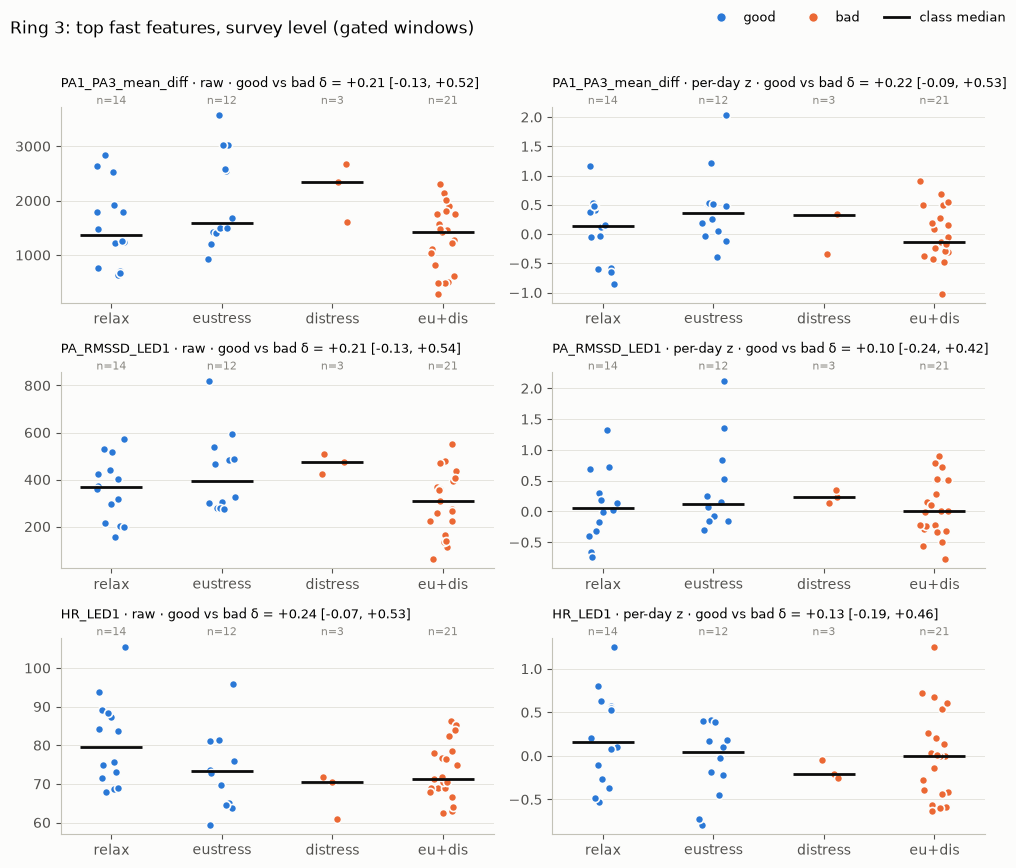

Survey-level class medians (gated, raw); n = surveys segments:


PA1_PA3_mean_diff      PA_RMSSD_LED1      HR_LED1     
                             median size        median size  median size
Label                                                                   
relax                       1366.85   14        367.30   14   79.66   14
eustress                    1589.86   12        396.01   12   73.27   12
distress                    2351.01    3        474.09    3   70.55    3
eustress+distress           1428.59   21        306.75   21   71.28   21

In [31]:
FIG6['R3'] = plot_ring('R3', TOP['R3'])
t_ = SURV[('gated', 'raw')].loc['R3']
print('Survey-level class medians (gated, raw); n = surveys segments:')
display(t_.groupby('Label')[TOP['R3']].agg(['median', 'size']).reindex(CLASSES_4).round(2))

**Takeaway (Ring 3):** the clearest Ring 3 differences are 4-class, not good vs bad. HR is highest in relax (survey medians 79.7 vs 70.6–73.3 bpm), and `PA1_PA3_mean_diff` and `PA_RMSSD_LED1` are higher in eustress than in eustress+distress (δ +0.43 and +0.42, CIs just clear of 0). Every good-vs-bad CI spans 0, and HR shrinks per-day (good vs bad +0.24 → +0.13). Distress has only 3 surveys.

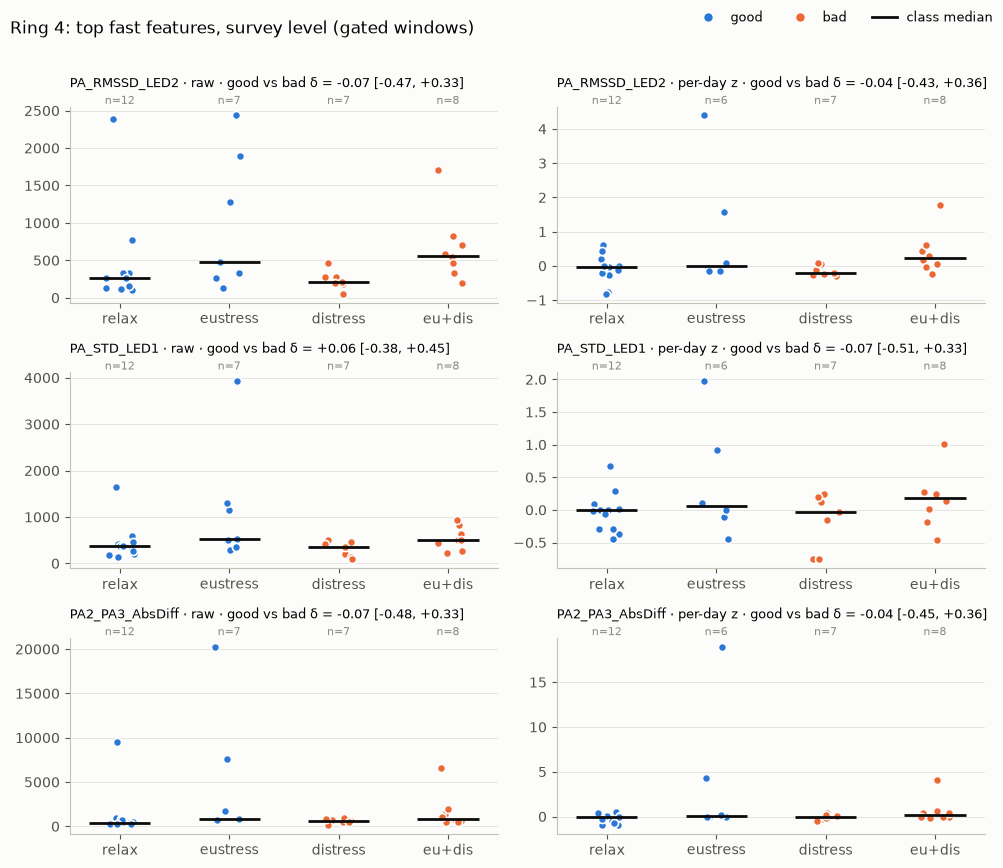

Survey-level class medians (gated, raw); n = surveys segments:


PA_RMSSD_LED2      PA_STD_LED1      PA2_PA3_AbsDiff     
                         median size      median size          median size
Label                                                                     
relax                    260.33   12      365.38   12          421.06   12
eustress                 472.64    7      530.50    7          826.84    7
distress                 210.13    7      345.03    7          570.11    7
eustress+distress        559.46    8      508.31    8          845.42    8

In [32]:
FIG6['R4'] = plot_ring('R4', TOP['R4'])
t_ = SURV[('gated', 'raw')].loc['R4']
print('Survey-level class medians (gated, raw); n = surveys segments:')
display(t_.groupby('Label')[TOP['R4']].agg(['median', 'size']).reindex(CLASSES_4).round(2))

**Takeaway (Ring 4):** Ring 4's top features are all 4-class pulse-amplitude variability. It is low in relax and distress and high in eustress and eustress+distress (`PA_RMSSD_LED2` class medians 260 / 473 / 210 / 559), so it follows *opportunity*, not pressure. Good vs bad is flat (δ −0.07). Distress vs eustress+distress is −0.79 [−1.00, −0.33] raw and −0.71 [−1.00, −0.18] per-day, but with only 7 vs 8 surveys. Treat it as a lead for A2.

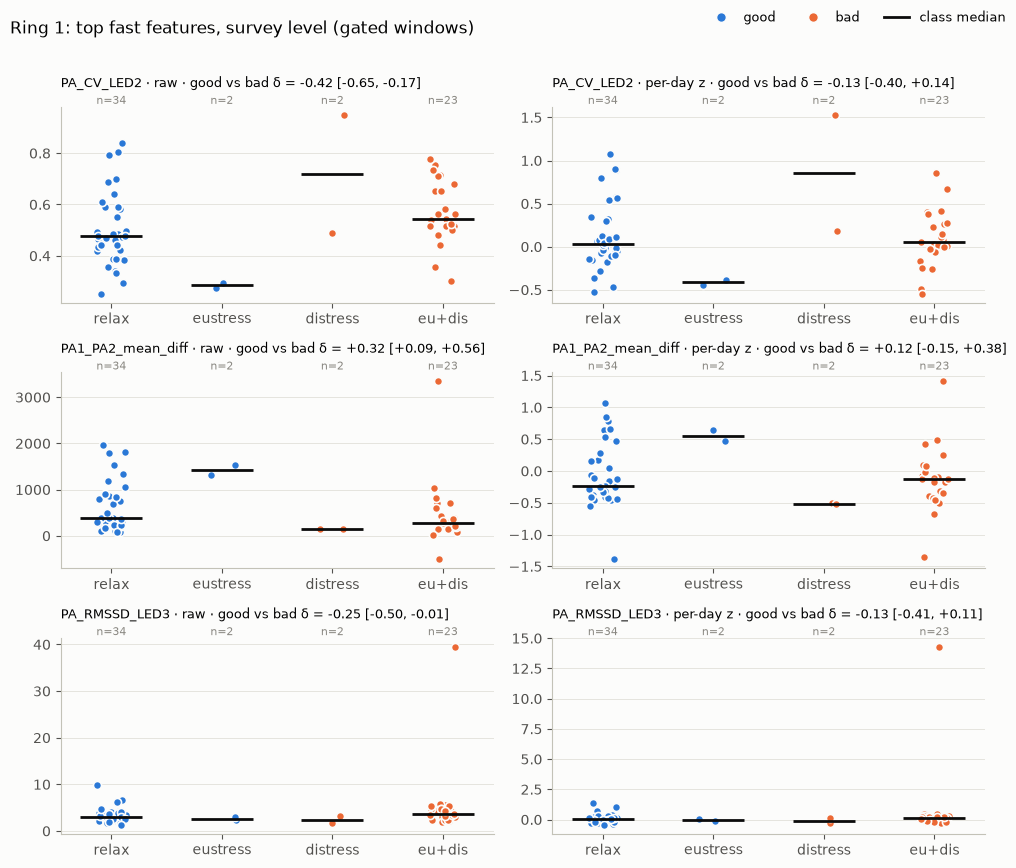

Survey-level class medians (gated, raw); n = surveys segments:


PA_CV_LED2      PA1_PA2_mean_diff      PA_RMSSD_LED3     
                      median size            median size        median size
Label                                                                      
relax                   0.48   34            378.82   34          3.09   34
eustress                0.29    2           1429.43    2          2.60    2
distress                0.72    2            142.05    2          2.41    2
eustress+distress       0.54   23            269.88   23          3.59   23

In [33]:
FIG6['R1'] = plot_ring('R1', TOP['R1'])
t_ = SURV[('gated', 'raw')].loc['R1']
print('Survey-level class medians (gated, raw); n = surveys segments:')
display(t_.groupby('Label')[TOP['R1']].agg(['median', 'size']).reindex(CLASSES_4).round(2))

**Takeaway (Ring 1):** Ring 1 has the strongest raw good-vs-bad effects (`PA_CV_LED2` −0.42 [−0.65, −0.17], `PA1_PA2_mean_diff` +0.32 [+0.09, +0.56]). Both mostly disappear per-day (−0.13 and +0.12), so they mainly reflect *which days* were good or bad. Eustress and distress have only 2 surveys each (days 0–10), too few for 4-class pairs.

## Step 7 · Supporting: window-size check (input for Yaxian, Workstream C)

**Flagged as input for Workstream C**: this overlaps with Yaxian's 10/30/60-minute aggregation, so it is shared, not a competing analysis.

Within each gated survey segment, windows are cut into consecutive **1, 5, 15 and 30 min blocks** (from the segment's first usable window); each block needs ≥ 2 usable windows and gets the median. For the top 3 features (largest mean |good-vs-bad δ| over Rings 3 and 4, gated raw, skipping near-copies as in step 6):
- **δ good vs bad** at block level, CI by resampling whole surveys;
- **within / between**: median SD of block values inside a survey ÷ SD of survey values between surveys (> 1 = the block-to-block noise is bigger than the differences between surveys).

Saved to `outputs/A1_window_size_for_yaxian.csv`.

In [34]:
BLOCK_MIN = [1, 5, 15, 30]
gb = eff[(eff.ring.isin(['R3', 'R4'])) & (eff.windows == 'gated') & (eff.norm == 'raw') & (eff.comparison == 'good vs bad')]
ranked_gb = gb.assign(a=gb.cliffs_delta.abs()).groupby('feature')['a'].mean().sort_values(ascending=False).index.tolist()
TOP3 = distinct_top(ranked_gb, SURV[('gated', 'raw')].loc[['R3', 'R4']])
print('Top 3 (mean |good vs bad δ| over R3 and R4):', TOP3)

dg = gw[gw.usable].copy()
kept_units = SURV[('gated', 'raw')].index
dg = dg.set_index(['ring', 'unit']).loc[lambda x: x.index.isin(kept_units)].reset_index()
dg['t_min'] = (dg['RealTime'] - dg.groupby(['ring', 'unit'], observed=True)['RealTime'].transform('min')).dt.total_seconds() / 60

ws_rows = []
for ring in RINGS:
    for L in BLOCK_MIN + ['survey']:
        if L == 'survey':
            blk = SURV[('gated', 'raw')].loc[ring].reset_index()
            blk['n'] = blk['n_windows']; kept_share = 1.0
        else:
            d = dg[dg.ring == ring].assign(block=lambda x: np.floor(x.t_min / L).astype(int))
            agg = {f: (f, 'median') for f in TOP3 if f != POOLED}
            blk = d.groupby(['unit', 'block']).agg(n=('Raw_Window_Index', 'size'), Survey_ID=('Survey_ID', 'first'),
                                                    Label2=('Label2', 'first'), **agg).reset_index()
            if POOLED in TOP3:
                blk[POOLED] = d.groupby(['unit', 'block'])['rr'].apply(lambda s: pooled_rmssd(list(s))).values
            kept_share = (blk.n >= 2).mean(); blk = blk[blk.n >= 2]
        clusters = {c: i for i, c in enumerate(blk['Survey_ID'].unique())}
        C = boot_counts(len(clusters), zlib.crc32(f'ws|{ring}|{L}'.encode()))
        between = SURV[('gated', 'raw')].loc[ring][TOP3].std()
        for f in TOP3:
            v = blk[f].to_numpy(float); ok = np.isfinite(v); isA = (blk.Label2 == 'good').to_numpy()
            cl = blk['Survey_ID'].map(clusters).to_numpy()
            d_, lo, hi, _ = cliffs_delta_ci(v[isA & ok], cl[isA & ok], v[~isA & ok], cl[~isA & ok], C)
            within = (blk[ok].groupby('unit')[f].std().median() if L != 'survey' else np.nan)
            ws_rows.append({'ring': ring, 'feature': f, 'block': f'{L} min' if L != 'survey' else 'whole survey',
                            'blocks': int(ok.sum()), 'surveys': blk.loc[ok, 'Survey_ID'].nunique(),
                            'median windows / block': float(blk.loc[ok, 'n'].median()),
                            '% blocks with ≥2 usable windows': round(100 * kept_share, 1),
                            'delta good vs bad': d_, 'ci_low': lo, 'ci_high': hi,
                            'within / between SD': within / between[f] if L != 'survey' else np.nan})
ws = pd.DataFrame(ws_rows)
ws.to_csv(OUT_DIR / 'A1_window_size_for_yaxian.csv', index=False)
show_ws = ws.assign(**{'δ good vs bad [CI]': [fmt(*r) for r in ws[['delta good vs bad', 'ci_low', 'ci_high']].to_numpy()]})
display(show_ws.drop(columns=['delta good vs bad', 'ci_low', 'ci_high']).round(2).set_index(['ring', 'feature', 'block']))

Top 3 (mean |good vs bad δ| over R3 and R4): ['pooled_RMSSD_LED1_ms', 'RMSSD_LED1_ms', 'SDNN_LED1_ms']


blocks  surveys  median windows / block  % blocks with ≥2 usable windows  within / between SD      δ good vs bad [CI]
ring feature              block                                                                                                                              
R3   pooled_RMSSD_LED1_ms 1 min            239       40                     2.0                             41.7                 0.95    -0.23 [-0.47, +0.04]
     RMSSD_LED1_ms        1 min            242       40                     2.0                             41.7                 0.92  -0.27 [-0.49, -0.02] ✓
     SDNN_LED1_ms         1 min            242       40                     2.0                             41.7                 0.90  -0.35 [-0.56, -0.10] ✓
     pooled_RMSSD_LED1_ms 5 min            174       43                     4.0                             80.2                 0.83    -0.20 [-0.43, +0.05]
     RMSSD_LED1_ms        5 min            174       43                     4.0                             80.2                 0.95    -0.23 [-0.46, +0.00]
     SDNN_LED1_ms         5 min            174       43                     4.0                             80.2                 0.98  -0.24 [-0.44, -0.01] ✓
     pooled_RMSSD_LED1_ms 15 min            98       43                     6.0                             94.2                 0.76    -0.18 [-0.45, +0.08]
     RMSSD_LED1_ms        15 min            98       43                     6.0                             94.2                 0.79    -0.18 [-0.43, +0.07]
     SDNN_LED1_ms         15 min            98       43                     6.0                             94.2                 0.99    -0.20 [-0.44, +0.05]
     pooled_RMSSD_LED1_ms 30 min            67       43                     8.0                             98.5                 0.43    -0.14 [-0.41, +0.15]
     RMSSD_LED1_ms        30 min            67       43                     8.0                             98.5                 0.71    -0.23 [-0.51, +0.05]
     SDNN_LED1_ms         30 min            67       43                     8.0                             98.5                 0.81    -0.22 [-0.49, +0.06]
     pooled_RMSSD_LED1_ms whole survey      50       43                    11.5                            100.0                  NaN    -0.13 [-0.42, +0.18]
     RMSSD_LED1_ms        whole survey      50       43                    11.5                            100.0                  NaN    -0.19 [-0.48, +0.13]
     SDNN_LED1_ms         whole survey      50       43                    11.5                            100.0                  NaN    -0.18 [-0.47, +0.13]
R4   pooled_RMSSD_LED1_ms 1 min             54       19                     2.0                             21.5                 1.53    -0.18 [-0.41, +0.14]
     RMSSD_LED1_ms        1 min             54       19                     2.0                             21.5                 1.31    -0.17 [-0.42, +0.19]
     SDNN_LED1_ms         1 min             54       19                     2.0                             21.5                 1.10    -0.10 [-0.38, +0.27]
     pooled_RMSSD_LED1_ms 5 min             75       28                     3.0                             55.9                 0.83    -0.27 [-0.54, +0.02]
     RMSSD_LED1_ms        5 min             76       28                     3.0                             55.9                 1.16    -0.25 [-0.51, +0.03]
     SDNN_LED1_ms         5 min             76       28                     3.0                             55.9                 1.03    -0.24 [-0.50, +0.05]
     pooled_RMSSD_LED1_ms 15 min            59       33                     4.0                             73.8                 0.91    -0.27 [-0.55, +0.05]
     RMSSD_LED1_ms        15 min            59       33                     4.0                             73.8                 0.87    -0.16 [-0.47, +0.15]
     SDNN_LED1_ms         15 min            59       33                     4.0           

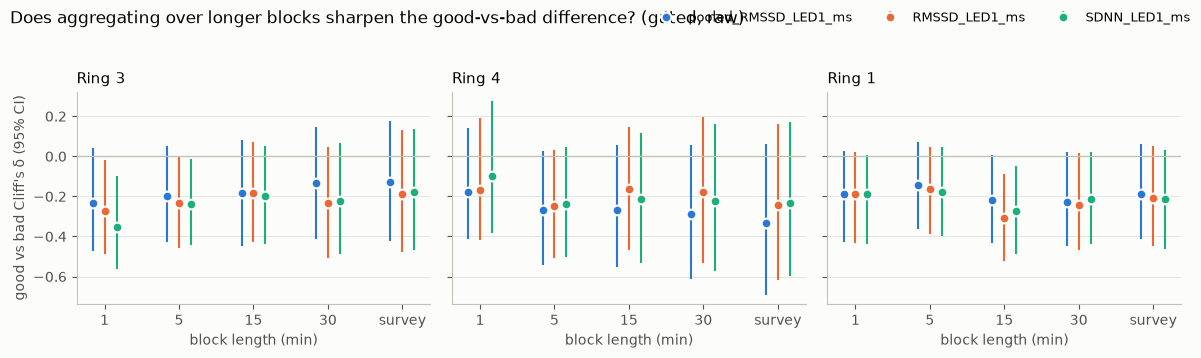

In [35]:
SERIES = [C_BLUE, C_ORANGE, C_AQUA]
labels = [f'{b} min' for b in BLOCK_MIN] + ['whole survey']
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), sharey=True)
for ax, ring in zip(axes, RINGS):
    for k, f in enumerate(TOP3):
        s = ws[(ws.ring == ring) & (ws.feature == f)].set_index('block').reindex(labels)
        x = np.arange(len(labels)) + (k - 1) * 0.16
        ax.errorbar(x, s['delta good vs bad'], yerr=[s['delta good vs bad'] - s['ci_low'], s['ci_high'] - s['delta good vs bad']],
                    fmt='o', ms=7, color=SERIES[k], mec='#fcfcfb', mew=1.5, elinewidth=1.5, capsize=0, label=f)
    ax.axhline(0, color='#c3c2b7', lw=1)
    ax.set_xticks(range(len(labels))); ax.set_xticklabels(['1', '5', '15', '30', 'survey'])
    ax.set_xlabel('block length (min)'); ax.set_title(f'Ring {ring[1:]}', loc='left', fontsize=11)
    ax.grid(axis='x', visible=False)
axes[0].set_ylabel("good vs bad Cliff's δ (95% CI)")
fig.legend(*axes[0].get_legend_handles_labels(), loc='upper right', ncol=3, frameon=False, fontsize=9)
fig.suptitle('Does aggregating over longer blocks sharpen the good-vs-bad difference? (gated, raw)', x=0.01, ha='left', fontsize=12)
fig.tight_layout(rect=(0, 0, 1, 0.94))
FIG7 = OUT_DIR / 'fig_A1_step7_window_size.png'
fig.savefig(FIG7, dpi=130, bbox_inches='tight'); plt.show()

**Takeaway:** longer blocks do **not** sharpen good vs bad. δ stays between about −0.1 and −0.35 at every block length in all three rings, and most CIs touch 0. What longer blocks do is cut block-to-block noise: RMSSD within/between SD falls from 1.06 (1 min) to 0.28 (30 min) in Ring 1, and from 0.92 to 0.71 in Ring 3.

**For Yaxian:**
- In Ring 4, only 21.5% of 1-min blocks have ≥ 2 usable windows, and the 1-min noise is larger than the differences between surveys (1.31). Use ≥ 5 min for Ring 4 and ≥ 15 min for HRV in general.
- Ring 3's 1-min RMSSD δ (−0.27 [−0.49, −0.02]) only *looks* stronger than the whole-survey value (−0.19 [−0.48, +0.13]). At block level, a survey counts once per block, so long surveys get extra weight.

## Step 8 · Findings-table rows and PR description

The findings use the shared table format. Each effect size is read straight from `eff` (the step-5 CSV) by `row_id` (format `ring|windows|norm|comparison|feature`), so the numbers can't drift from the analysis. Every row says whether the finding holds for Ring 4.

**HRV confidence rule (addition 2):** gated median RMSSD is 82–86 ms in every ring (table 3e), below the 150 ms plausibility limit, so gated HRV rows are *not* marked low confidence. Every **ungated** HRV row is (210–332 ms) and carries `flag_hrv = HRV low conf` in the CSV.

Saved to `outputs/A1_findings_rows.csv`.

In [36]:
def es(row_id):
    r = eff.set_index('row_id').loc[row_id]
    n = f" (n {r.n_surveys_A}/{r.n_surveys_B})"
    return fmt(r.cliffs_delta, r.ci_low, r.ci_high) + n

usable = gw.groupby('ring', observed=True)['usable'].mean().mul(100).round(0)
FINDINGS = pd.DataFrame([
    {'id': 'F1', 'feature or group': 'signal quality (all fast features)', 'ring': 'R3, R4, R1',
     'claim': f"Only {usable['R3']:.0f}% (R3), {usable['R4']:.0f}% (R4) and {usable['R1']:.0f}% (R1) of windows pass the clean-pulse gate. "
              "The usable share is lower in bad than in good surveys, and Ring 4 keeps only 33 of 47 surveys.",
     'effect size': 'usable % good vs bad: R3 29.6 vs 23.7, R4 7.5 vs 5.7, R1 35.5 vs 24.8',
     '4-class vs 2-class': 'both (table 3c by 4 classes and by good/bad)',
     'figure / row': 'tables 3c, 3d; outputs/A1_usable_windows_by_ring_class.csv',
     'holds for Ring 4?': 'yes, and is worst there', 'confidence': 'high'},
    {'id': 'F2', 'feature or group': 'SDNN / RMSSD (single window)', 'ring': 'R3, R4, R1',
     'claim': "The 0.45 s MinPeakDistance rule skips beats in 44–72% of ungated windows, which inflates single-window HRV. "
              "Median RMSSD falls from 211 / 332 / 210 ms to 86 / 85 / 82 ms after the gate (R3 / R4 / R1). Ungated HRV is low confidence.",
     'effect size': 'median RMSSD (ms) all → gated: R3 210.8 → 86.2, R4 332.4 → 84.7, R1 210.0 → 81.6',
     '4-class vs 2-class': 'n/a (data quality)',
     'figure / row': 'fig_A1_step1_minpeakdistance_skipped_beat.png; tables 3e, 3f',
     'holds for Ring 4?': 'yes, and is worst there (72% of windows)', 'confidence': 'high'},
    {'id': 'F3', 'feature or group': 'all fast features (day confound)', 'ring': 'R3, R4, R1, ALL',
     'claim': "Within each ring, per-day normalisation brings the share of CIs that exclude 0 down to chance (about 5%): "
              "R3 7.4 → 4.6%, R4 10.9 → 2.9%, R1 22 → 0% (only 2 comparisons testable in R1). Daily median HR spans 28 / 16 / 13 bpm "
              "(R3 / R4 / R1), so most raw class differences look like day differences. Exception: pooled over rings, 26.3 → 13.7% "
              "stay significant per-day, and every one involves eustress (mostly higher pulse amplitude in eustress, same direction in "
              "all 3 rings but not significant in any single ring). This fits Anisha's finding that eustress runs warmer; it is a lead for A2.",
     'effect size': ("share of gated CIs excluding 0, raw → per-day (table 5a); pooled relax vs eustress PA1 per-day "
                     f"{es('ALL|gated|day|relax vs eu|PA1')}; R4 alone {es('R4|gated|day|relax vs eu|PA1')}"),
     '4-class vs 2-class': 'both (all 7 comparisons)',
     'figure / row': 'table 5a; step-4 day table (day_tab); ALL|gated|day|relax vs eu|PA1',
     'holds for Ring 4?': 'yes (10.9% → 2.9%); eustress lead: same direction in R4, CI spans 0', 'confidence': 'high (day effect); low (eustress lead)'},
    {'id': 'F4', 'feature or group': 'HRV: RMSSD, SDNN, pooled RMSSD (extra)', 'ring': 'ALL (R3, R4, R1)',
     'claim': "Bad surveys show slightly *higher* gated HRV in every ring. The pooled per-person effect is just significant, "
              "but it drops to near 0 per-day, so it is mostly a day effect. This is the opposite of the usual stress → lower HRV.",
     'effect size': (f"ALL per-person RMSSD {es('ALL|gated|person|good vs bad|RMSSD_LED1_ms')} → per-day "
                     f"{es('ALL|gated|day|good vs bad|RMSSD_LED1_ms')}; R4 per-day {es('R4|gated|day|good vs bad|RMSSD_LED1_ms')}"),
     '4-class vs 2-class': '2-class (good vs bad)',
     'figure / row': 'ALL|gated|person|good vs bad|RMSSD_LED1_ms; ALL|gated|day|good vs bad|RMSSD_LED1_ms; fig_A1_step7_window_size.png',
     'holds for Ring 4?': 'same direction, and does not shrink per-day, but the CI is wide (18 vs 15 surveys)', 'confidence': 'low'},
    {'id': 'F5', 'feature or group': 'HR_LED1', 'ring': 'R3',
     'claim': "Ring 3's HR is highest in relax (survey medians 79.7 vs 70.6–73.3 bpm). The earlier hint of an inversion survives at "
              "survey level but weakens per-day, and every CI with n ≥ 5 spans 0.",
     'effect size': (f"relax vs eu+dis raw {es('R3|gated|raw|relax vs eu+dis|HR_LED1')} → per-day "
                     f"{es('R3|gated|day|relax vs eu+dis|HR_LED1')}; good vs bad {es('R3|gated|raw|good vs bad|HR_LED1')}"),
     '4-class vs 2-class': '4-class clearer (relax vs rest) than good vs bad',
     'figure / row': 'R3|gated|raw|relax vs eu+dis|HR_LED1; fig_A1_step6_R3_top_features.png',
     'holds for Ring 4?': f"no: relax vs eu+dis {es('R4|gated|raw|relax vs eu+dis|HR_LED1')}", 'confidence': 'low'},
    {'id': 'F6', 'feature or group': 'PA_RMSSD_LED2 (pulse-amplitude variability)', 'ring': 'R4',
     'claim': "In Ring 4, distress has lower LED2 pulse-amplitude variability than eustress+distress, and this survives per-day. "
              "It appears only with the gate, is invisible in good vs bad, and does not repeat in R3 or R1. "
              "It is one hit out of 175 tests per ring, so it may be chance. Treat it as a lead for A2.",
     'effect size': (f"raw {es('R4|gated|raw|dis vs eu+dis|PA_RMSSD_LED2')}, per-day {es('R4|gated|day|dis vs eu+dis|PA_RMSSD_LED2')}; "
                     f"ungated {es('R4|all|raw|dis vs eu+dis|PA_RMSSD_LED2')}; good vs bad {es('R4|gated|raw|good vs bad|PA_RMSSD_LED2')}"),
     '4-class vs 2-class': '4-class only',
     'figure / row': 'R4|gated|day|dis vs eu+dis|PA_RMSSD_LED2; fig_A1_step6_R4_top_features.png',
     'holds for Ring 4?': 'Ring 4 only (R3 n=3 distress, R1 n=2)', 'confidence': 'low'},
])
FINDINGS.to_csv(OUT_DIR / 'A1_findings_rows.csv', index=False)
with pd.option_context('display.max_colwidth', None):
    display(FINDINGS.set_index('id'))

,feature or group,ring,claim,effect size,4-class vs 2-class,figure / row,holds for Ring 4?,confidence
id,,,,,,,,
F1,signal quality (all fast features),"R3, R4, R1","Only 25% (R3), 7% (R4) and 32% (R1) of windows pass the clean-pulse gate. The usable share is lower in bad than in good surveys, and Ring 4 keeps only 33 of 47 surveys.","usable % good vs bad: R3 29.6 vs 23.7, R4 7.5 vs 5.7, R1 35.5 vs 24.8",both (table 3c by 4 classes and by good/bad),"tables 3c, 3d; outputs/A1_usable_windows_by_ring_class.csv","yes, and is worst there",high
F2,SDNN / RMSSD (single window),"R3, R4, R1","The 0.45 s MinPeakDistance rule skips beats in 44–72% of ungated windows, which inflates single-window HRV. Median RMSSD falls from 211 / 332 / 210 ms to 86 / 85 / 82 ms after the gate (R3 / R4 / R1). Ungated HRV is low confidence.","median RMSSD (ms) all → gated: R3 210.8 → 86.2, R4 332.4 → 84.7, R1 210.0 → 81.6",n/a (data quality),"fig_A1_step1_minpeakdistance_skipped_beat.png; tables 3e, 3f","yes, and is worst there (72% of windows)",high
F3,all fast features (day confound),"R3, R4, R1, ALL","Within each ring, per-day normalisation brings the share of CIs that exclude 0 down to chance (about 5%): R3 7.4 → 4.6%, R4 10.9 → 2.9%, R1 22 → 0% (only 2 comparisons testable in R1). Daily median HR spans 28 / 16 / 13 bpm (R3 / R4 / R1), so most raw class differences look like day differences. Exception: pooled over rings, 26.3 → 13.7% stay significant per-day, and every one involves eustress (mostly higher pulse amplitude in eustress, same direction in all 3 rings but not significant in any single ring). This fits Anisha's finding that eustress runs warmer; it is a lead for A2.","share of gated CIs excluding 0, raw → per-day (table 5a); pooled relax vs eustress PA1 per-day -0.46 [-0.69, -0.20] ✓ (n 60/20); R4 alone -0.33 [-0.86, +0.28] (n 12/6)",both (all 7 comparisons),table 5a; step-4 day table (day_tab); ALL|gated|day|relax vs eu|PA1,"yes (10.9% → 2.9%); eustress lead: same direction in R4, CI spans 0",high (day effect); low (eustress lead)
F4,"HRV: RMSSD, SDNN, pooled RMSSD (extra)","ALL (R3, R4, R1)","Bad surveys show slightly *higher* gated HRV in every ring. The pooled per-person effect is just significant, but it drops to near 0 per-day, so it is mostly a day effect. This is the opposite of the usual stress → lower HRV.","ALL per-person RMSSD -0.17 [-0.33, -0.00] ✓ (n 78/64) → per-day -0.07 [-0.24, +0.10] (n 77/64); R4 per-day -0.27 [-0.63, +0.17] (n 18/15)",2-class (good vs bad),ALL|gated|person|good vs bad|RMSSD_LED1_ms; ALL|gated|day|good vs bad|RMSSD_LED1_ms; fig_A1_step7_window_size.png,"same direction, and does not shrink per-day, but the CI is wide (18 vs 15 surveys)",low
F5,HR_LED1,R3,"Ring 3's HR is highest in relax (survey medians 79.7 vs 70.6–73.3 bpm). The earlier hint of an inversion survives at survey level but weakens per-day, and every CI with n ≥ 5 spans 0.","relax vs eu+dis raw +0.39 [-0.00, +0.75] (n 14/21) → per-day +0.24 [-0.17, +0.62] (n 14/21); good vs bad +0.24 [-0.07, +0.53] (n 25/24)",4-class clearer (relax vs rest) than good vs bad,R3|gated|raw|relax vs eu+dis|HR_LED1; fig_A1_step6_R3_top_features.png,"no: relax vs eu+dis +0.08 [-0.46, +0.57] (n 12/8)",low
F6,PA_RMSSD_LED2 (pulse-amplitude variability),R4,"In Ring 4, distress has lower LED2 pulse-amplitude variability than eustress+distress, and this survives per-day. It appears only with the gate, is invisible in good vs bad, and does not repeat in R3 or R1. It is one hit out of 175 tests per ring, so it may be chance. Treat it as a lead for A2.","raw -0.79 [-1.00, -0.33] ✓ (n 7/8), per-day -0.71 [-1.00, -0.18] ✓ (n 7/8); ungated -0.01 [-0.50, +0.53] (n 13/14); good vs bad -0.07 [-0.47, +0.33] (n 19/15)",4-class only,R4|gated|day|dis vs eu+dis|PA_RMSSD_LED2; fig_A1_step6_R4_top_features.png,"Ring 4 only (R3 n=3 distress, R1 n=2)",low


### PR description (5 lines)

1. Adds `PilotPhaseC/analysis/A_fast_features.ipynb` (Workstream A, A1). It runs Anisha's feature code unchanged on Rings 3, 4 and 1, where it exactly matches an independent MATLAB-logic re-implementation on the sample file. A clean-pulse gate is a separate, labelled step. It ranks Cliff's δ with survey-bootstrap 95% CIs for 25 fast features × 7 comparisons × raw / per-person / per-day, with and without the gate, in `outputs/A1_fast_feature_effects.csv`.
2. **Headline:** only 25% / 7% / 32% of windows are usable (R3 / R4 / R1). After per-day normalisation, the share of CIs excluding 0 falls to about chance within each ring (R3 4.6%, R4 2.9%, R1 0%). No fast feature reliably separates good vs bad, in Ring 4 or elsewhere. One lead for A2: pooled over rings, pulse amplitude is higher in eustress even per-day. Days 0–10 only, to match Workstream B. Findings F1–F6 are in `outputs/A1_findings_rows.csv`.
3. **Team note:** the 0.45 s MinPeakDistance rule can skip beats and inflate single-window HRV. Beats are skipped in 44–72% of ungated windows, and median RMSSD is 210–332 ms ungated vs 82–86 ms gated (`fig_A1_step1_minpeakdistance_skipped_beat.png`). Use gated or pooled HRV.
4. **Anisha, please confirm these extras in the Python port are intended:**
   - the 30 s warm-up drop (it removes 2 small R4 surveys: 49 vs the team's 51);
   - the ambiguous-label drop;
   - the saturation flag (≥ 524287 on any LED; it flags but keeps windows, and 0 is not checked);
   - the PA ratios (`PA1_PA2_Ratio` reaches 7.1e11 when PA2 is near 0).

   Also, the 8 mg non-wear flag marks 376 / 67 / 421 windows that pass the clean-pulse gate.
5. **Supporting:** window-size check for Yaxian in `outputs/A1_window_size_for_yaxian.csv`. Classes with fewer than 3 surveys are flagged ⚠, not dropped. The derived cache lives outside the repo, and no data is committed.

## Step 9 · Beat detection v2 (follow-up from the 19 Nov meeting)

At the 19 Nov meeting, Tenor was asked to replace the fixed 0.45 s minimum beat spacing with one based on each window's own heart rate, and to check that all heartbeats are found. This step builds that **v2** for LED1 heart rate and HRV, tests it, and re-runs the A1 HR/HRV results with it.

**Steps 1–8 are unchanged** and still use Anisha's code exactly (v1). v2 only changes how **LED1 beats** are timed: HR, SDNN, RMSSD and pooled RMSSD. Pulse-amplitude (PA) features are not touched.

**What v2 changes, and why:**

| # | Change | Why |
|---|---|---|
| 1 | **Minimum beat spacing = 70% of the window's own beat length**, instead of a fixed 0.45 s. The beat length comes from the autocorrelation (the same one the quality gate uses) | the fixed 0.45 s drops a real beat when beats are ~0.45 s apart (step 3f), and caps HR at 133 bpm |
| 2 | **Even time grid:** sample *i* is at *i* / fs, with fs = (samples − 1) / window duration | the timestamps jitter (9a); the samples themselves are evenly spaced |
| 3 | **Sample rate from the mean spacing**, not the median timestamp gap | the median gap overstates fs by ~5% (9a), which shifts the filter cut-offs and the gate's reference HR |
| 4 | **Refined beat timing:** a parabola through the 3 samples around each trough gives a time between samples | at 25 Hz each sample is 40 ms apart, which by itself adds noise to RMSSD |

**Choice of 70%:** Tenor chose 70%. The meeting suggested 65%, so 9c tests 50, 60, 65, 70 and 75% (and the fixed 0.45 s) side by side.

**Ready for the new firmware:** the v2 function takes any sample rate and window length (the new cohort records 30 s windows at 100 Hz; 9d tests that format).

### 9a · Timestamps and sample rate

Raw LED windows are reloaded once and cached in `CACHE_DIR` (derived data, not committed). Two checks:
1. **Are the odd timestamp gaps real?** If a gap of 8 ms were real, the LED signal would change far less across it than across a 40 ms gap. On clean-pulse windows, compare the raw LED1 change per sample step against the timestamp gap.
2. **How far off is the median-gap sample rate?** Compare 1 / median gap (what v1 uses) with (samples − 1) / window duration.

In [37]:
def raw_windows(path):
    """Complete windows of one file: raw timestamps and LED values (cached; derived data, not committed)."""
    cache = CACHE_DIR / f'{path.stem}__raw.pkl'
    if cache.exists() and cache.stat().st_mtime > path.stat().st_mtime:
        return pd.read_pickle(cache)
    data, _, _, _ = run_quietly(load_m3x_file, path)
    data = data.sort_values(['raw_window_index', 'row_index'], kind='stable')
    rows = []
    for wid_, w_ in data.groupby('raw_window_index', sort=True):
        if len(w_) != expected_samples or not np.array_equal(w_['row_index'].to_numpy(), expected_row_index):
            continue
        rows.append({'file': path.name, 'Raw_Window_Index': int(wid_), 't_ms': w_['timestamp_ms'].to_numpy(float),
                     **{k: w_[k].to_numpy(float) for k in ('led1', 'led2', 'led3')}})
    out = pd.DataFrame(rows); out.to_pickle(cache)
    return out

t0 = time.time()
raw = pd.concat([raw_windows(p) for folder in RINGS.values() for p in ring_files(folder)], ignore_index=True)
raw = gw[['ring', 'file', 'Raw_Window_Index']].merge(raw, on=['file', 'Raw_Window_Index'], how='left', validate='1:1')
assert raw['t_ms'].notna().all() and len(raw) == len(gw)
print(f'raw LED windows for all {len(raw)} feature rows ({time.time() - t0:.0f} s)')

# 1. timestamp gaps, and raw LED1 change per step on clean-pulse windows
GAP_BINS = [0, 15, 30, 36, 42, 50, 100, 1000]
GAP_LABELS = ['<15', '15–30', '30–36', '36–42', '42–50', '50–100', '>100']
steps = pd.DataFrame({'gap_ms': np.concatenate(raw['t_ms'].map(np.diff).to_list()),
                      'led1_change': np.concatenate(raw['led1'].map(lambda v: np.abs(np.diff(v))).to_list()),
                      'usable': np.repeat(gw['usable'].to_numpy(), expected_samples - 1)})
steps['gap'] = pd.cut(steps['gap_ms'], GAP_BINS, labels=GAP_LABELS)
jit = steps.groupby('gap', observed=True).agg(share_of_gaps=('gap_ms', 'size'))
jit['share_of_gaps'] = (100 * jit['share_of_gaps'] / len(steps)).round(1)
clean = steps[steps.usable].groupby('gap', observed=True)
jit['median gap (ms)'] = clean['gap_ms'].median()
jit['median raw LED1 change per step (clean windows)'] = clean['led1_change'].median()
jit['change per ms of gap'] = (jit.iloc[:, 2] / jit['median gap (ms)']).round(2)
print('Timestamp gaps (% of all sample steps) and how much raw LED1 changes across them:')
display(jit)

# 2. sample rate: median gap vs mean spacing
raw['fs_median_gap'] = raw['t_ms'].map(lambda t: 1000 / np.median(np.diff(t)))
raw['fs_mean_spacing'] = raw['t_ms'].map(lambda t: 1000 * (len(t) - 1) / (t[-1] - t[0]))
raw['duration_s'] = raw['t_ms'].map(lambda t: (t[-1] - t[0]) / 1000)
fs_tab = raw.groupby('ring', observed=True)[['fs_median_gap', 'fs_mean_spacing', 'duration_s']].median()
fs_tab['median-gap fs overstates by (%)'] = (100 * (fs_tab.fs_median_gap / fs_tab.fs_mean_spacing - 1))
display(fs_tab.round(3))
print(f"window duration over all windows: {raw.duration_s.mean():.3f} ± {raw.duration_s.std():.3f} s")

Ring_01_PID_104: skipping 2 file(s) after day 10: ['Ring1_PID_104_day12_10_22_26_labeled_continuous.xlsx', 'Ring1_PID_104_day13_10_23_26_labeled_continuous.xlsx']
raw LED windows for all 13708 feature rows (0 s)
Timestamp gaps (% of all sample steps) and how much raw LED1 changes across them:


,share_of_gaps,median gap (ms),median raw LED1 change per step (clean windows),change per ms of gap
gap,,,,
<15,4.9,8.0,158.0,19.75
15–30,3.0,21.0,160.5,7.64
30–36,0.8,34.0,156.0,4.59
36–42,62.5,38.0,156.0,4.11
42–50,25.1,44.0,156.0,3.55
50–100,2.7,89.0,156.0,1.75
>100,0.9,116.0,159.0,1.37


,fs_median_gap,fs_mean_spacing,duration_s,median-gap fs overstates by (%)
ring,,,,
R3,26.316,24.977,4.444,5.358
R4,26.316,24.972,4.445,5.382
R1,26.316,24.933,4.452,5.548


window duration over all windows: 4.447 ± 0.004 s


**Takeaway:** the odd timestamp gaps aren't real. Raw LED1 changes by the same ~156–160 counts per sample step whether the timestamp gap says 8 ms or 116 ms; a real 8 ms gap would show about a fifth of the change. Every window lasts 4.447 ± 0.004 s, so the ring samples evenly at about 25.0 Hz and only the timestamps jitter (likely stamped when the firmware reads its sample buffer, not when each sample is taken). Taking the sample rate from the median gap overstates it by 5.4–5.5% (26.3 vs ~25.0 Hz).

**For Md / Farhad (new firmware):** timestamps should follow the sample clock, or the firmware should log a sample counter; otherwise the 100 Hz data will have the same timing noise.

### 9b · The v2 beat detector

One function, `ppg_beats_v2`, for any sample rate and window length. It reuses Anisha's filter settings (`low_cutoff`, `high_cutoff`, `fc_smooth`, 4th-order Butterworth, `matlab_filtfilt`), her `matlab_findpeaks`, and the gate's `acf_peak_hr`. HR, SDNN and RMSSD use her definitions (60 / mean interval, `std` with N − 1, √mean of squared successive differences).

If a window has no autocorrelation peak in the 40–180 bpm range, there is no beat length to scale from, so v2 falls back to the fixed 0.45 s (counted below). Those windows fail the quality gate anyway (rule 3).

`ppg_beats_v1_timebase` reproduces v1's time base (timestamps, fs from the median gap); with a fixed 0.45 s and no refinement it must give **exactly** Anisha's HR, which is checked.

In [38]:
V2_FACTOR = 0.70        # min beat spacing = 70% of the window's beat length (Tenor's choice; 9c tests the alternatives)
V2_FALLBACK_S = 0.45    # used only when the window has no autocorrelation peak

def refine_trough_times(s, t, idx):
    """Parabola through the 3 samples around each trough -> trough time between samples."""
    out = t[idx].astype(float).copy()
    for m, i in enumerate(idx):
        if 0 < i < len(s) - 1:
            den = s[i - 1] - 2 * s[i] + s[i + 1]
            if den > 0:
                off = float(np.clip(0.5 * (s[i - 1] - s[i + 1]) / den, -0.5, 0.5))
                out[m] = t[i] + off * ((t[i + 1] - t[i]) if off > 0 else (t[i] - t[i - 1]))
    return out

def trough_intervals(smooth, t, min_dist, refine):
    _, locs = matlab_findpeaks(-smooth, t, min_dist)          # Anisha's findpeaks, on minus the signal = troughs
    idx = np.searchsorted(t, locs)
    times = refine_trough_times(smooth, t, idx) if refine else t[idx]
    rr = np.diff(times)
    return rr[np.isfinite(rr) & (rr > 0)]

def rr_stats(rr):
    """HR / SDNN / RMSSD with Anisha's definitions (SDNN, RMSSD in ms here)."""
    out = {'HR': np.nan, 'SDNN_ms': np.nan, 'RMSSD_ms': np.nan, 'n_rr': len(rr)}
    if len(rr):
        out['HR'] = 60 / rr.mean()
    if len(rr) >= 2:
        out['SDNN_ms'] = np.std(rr, ddof=1) * 1000
        out['RMSSD_ms'] = np.sqrt(np.mean(np.diff(rr) ** 2)) * 1000
    return out

def filter_led1(led1, fs):
    nyq = fs / 2
    b_bp, a_bp = butter(4, [low_cutoff / nyq, high_cutoff / nyq], btype='bandpass')
    b_lp, a_lp = butter(4, fc_smooth / nyq, btype='low')
    filt = matlab_filtfilt(b_bp, a_bp, led1)
    return filt, matlab_filtfilt(b_lp, a_lp, filt)

def v2_timebase(led1, t_ms):
    """Even time grid at the true sample rate; band-passed + smoothed LED1; autocorrelation beat length."""
    led1 = np.asarray(led1, float); t_ms = np.asarray(t_ms, float); n = len(led1)
    fs = 1000 * (n - 1) / (t_ms[-1] - t_ms[0])
    filt, smooth = filter_led1(led1, fs)
    acf_pk, hr_ref = acf_peak_hr(filt, fs)
    return {'t': np.arange(n) / fs, 'fs': fs, 'smooth': smooth, 'acf_peak': acf_pk, 'HR_ref': hr_ref}

def ppg_beats_v1_timebase(led1, t_ms):
    """v1 time base: beats placed on the timestamps, filters designed with fs = 1 / median gap (Anisha's code)."""
    t_sec = np.asarray(t_ms, float) / 1000; t = t_sec - t_sec[0]      # same arithmetic order as her code
    dt = np.diff(t_sec); fs = 1 / np.median(dt[np.isfinite(dt) & (dt > 0)])
    return {'t': t, 'fs': fs, 'smooth': filter_led1(np.asarray(led1, float), fs)[1]}

def min_spacing(factor, hr_ref):
    if factor is None or not np.isfinite(hr_ref):
        return V2_FALLBACK_S
    return factor * 60 / hr_ref

def ppg_beats_v2(led1, t_ms, factor=V2_FACTOR, refine=True):
    """LED1 beat intervals, v2. Any sample rate, any window length. Returns stats, intervals (s) and reference HR."""
    tb = v2_timebase(led1, t_ms)
    d = min_spacing(factor, tb['HR_ref'])
    rr = trough_intervals(tb['smooth'], tb['t'], d, refine)
    return {**rr_stats(rr), 'rr': rr, 'HR_ref': tb['HR_ref'], 'acf_peak': tb['acf_peak'], 'fs': tb['fs'],
            'min_spacing_s': d, 'fallback': not np.isfinite(tb['HR_ref'])}

# Check: v1 time base + fixed 0.45 s + no refinement reproduces Anisha's HR exactly
chk = [rr_stats(trough_intervals(tb['smooth'], tb['t'], 0.45, False))['HR']
       for tb in (ppg_beats_v1_timebase(r.led1, r.t_ms) for r in raw.itertuples())]
assert np.allclose(chk, gw['HR_LED1'], equal_nan=True), 'v1 time base must reproduce her HR_LED1'
print('check passed: v1 time base + 0.45 s reproduces her HR_LED1 for all', len(chk), 'windows')

check passed: v1 time base + 0.45 s reproduces her HR_LED1 for all 13708 windows


### 9c · Which spacing rule? Test on the real data

Every combination of **spacing rule** (fixed 0.45 s, or 50 / 60 / 65 / 70 / 75% of the beat length) × **time base** (v1 timestamps, or v2 even grid) × **refined timing** (off / on), on the same windows.

The comparison set is the windows that pass gate rules 1–3 (no saturation, low motion, periodic pulse). None of those rules depend on the beat finder, so every version is judged on identical windows. For each version:
- **skipped beat:** the longest interval is ≥ 1.6 × the window's median interval (two beats merged into one);
- **double-counted beat:** the shortest interval is ≤ median / 1.6 (noise or the second bump of a pulse counted as a beat);
- **HR agrees:** HR within 10% of the autocorrelation HR. The adaptive rule also uses that HR, so this column flatters the adaptive versions a little; the simulation in 9d has no such bias;
- **usable windows:** rules 1–3 plus the gate's rules 4 and 5 recomputed with that version's beats.

In [39]:
SWEEP_FACTORS = [None, 0.50, 0.60, 0.65, 0.70, 0.75]
def variant_name(timebase, factor, refine):
    rule = 'fixed 0.45 s' if factor is None else f'{factor:.0%} of beat'
    return f"{rule} | {timebase}{' | refined' if refine else ''}"
VARIANTS = [(tb_, f_, r_) for tb_ in ('v1 timestamps', 'v2 even grid') for f_ in SWEEP_FACTORS for r_ in (False, True)]
V1_NAME = variant_name('v1 timestamps', None, False)
V2_NAME = variant_name('v2 even grid', V2_FACTOR, True)

def beat_flags(rr):
    if len(rr) < 2:
        return np.nan, np.nan
    med = np.median(rr)
    return float(rr.max() >= 1.6 * med), float(rr.min() <= med / 1.6)

t0 = time.time(); recs = []
for i, r in enumerate(raw.itertuples()):
    bases = {'v1 timestamps': ppg_beats_v1_timebase(r.led1, r.t_ms), 'v2 even grid': v2_timebase(r.led1, r.t_ms)}
    hr_ref = bases['v2 even grid']['HR_ref']
    for tb_, f_, r_ in VARIANTS:
        b = bases[tb_]
        rr = trough_intervals(b['smooth'], b['t'], min_spacing(f_, hr_ref), r_)
        s = rr_stats(rr); sk, db = beat_flags(rr)
        cv = rr.std(ddof=1) / rr.mean() if len(rr) >= 2 else np.nan
        recs.append((i, variant_name(tb_, f_, r_), s['HR'], s['RMSSD_ms'], s['n_rr'], sk, db,
                     float(abs(s['HR'] - hr_ref) <= HR_AGREE_MAX * hr_ref) if np.isfinite(hr_ref) else 0.0,
                     float(s['n_rr'] >= MIN_RR and cv < RR_CV_MAX)))
sweep = pd.DataFrame(recs, columns=['i', 'variant', 'HR', 'RMSSD_ms', 'n_rr', 'skipped', 'double', 'hr_agrees', 'steady'])
sweep['ring'] = gw['ring'].to_numpy()[sweep.i]
sweep['pre_clean'] = (gw['g1_no_saturation'] & gw['g2_low_motion'] & gw['g3_periodic']).to_numpy()[sweep.i]
sweep['usable'] = sweep.pre_clean & (sweep.hr_agrees == 1) & (sweep.steady == 1)
print(f'{sweep.variant.nunique()} versions x {len(raw)} windows in {time.time() - t0:.0f} s; '
      f'v1 reproduces her RMSSD: {np.allclose(sweep[sweep.variant == V1_NAME].RMSSD_ms, gw.RMSSD_LED1_ms, equal_nan=True)}')

ORDER = [variant_name(*v) for v in VARIANTS]
def sweep_table(d):
    t = d.groupby('variant').agg(skipped=('skipped', 'mean'), double=('double', 'mean'), hr_agrees=('hr_agrees', 'mean'),
                                 rmssd=('RMSSD_ms', 'median'), usable=('usable', 'sum')).reindex(ORDER)
    t[['skipped', 'double', 'hr_agrees']] *= 100
    return t.round(1).rename(columns={'skipped': '% skipped beat', 'double': '% double-counted', 'hr_agrees': '% HR agrees',
                                      'rmssd': 'median RMSSD (ms)', 'usable': 'usable windows'})
pc = sweep[sweep.pre_clean]
SWEEP_ALL = sweep_table(pc)
print(f'All rings, windows passing rules 1–3 (n = {pc.i.nunique()}):')
display(SWEEP_ALL)
per_ring = pd.concat({r: sweep_table(pc[pc.ring == r]) for r in RINGS}, names=['ring'])
per_ring.to_csv(OUT_DIR / 'A1v2_beat_detection_real.csv')
key = [V1_NAME] + [variant_name('v2 even grid', f_, True) for f_ in SWEEP_FACTORS]
print('Per ring, original vs the v2 time base with refined timing:')
display(per_ring.loc[(slice(None), key), :].unstack(0).swaplevel(0, 1, axis=1).sort_index(axis=1, level=0, sort_remaining=False)
        [[(r, c) for r in RINGS for c in ('% skipped beat', '% double-counted', 'usable windows')]])

24 versions x 13708 windows in 35 s; v1 reproduces her RMSSD: True
All rings, windows passing rules 1–3 (n = 5202):


,% skipped beat,% double-counted,% HR agrees,median RMSSD (ms),usable windows
variant,,,,,
fixed 0.45 s | v1 timestamps,6.4,6.9,72.5,125.6,2966
fixed 0.45 s | v1 timestamps | refined,6.3,7.1,72.4,120.6,3011
50% of beat | v1 timestamps,3.5,9.1,78.5,129.7,3049
50% of beat | v1 timestamps | refined,3.7,9.6,78.5,124.9,3093
60% of beat | v1 timestamps,2.0,2.0,85.2,119.4,3231
60% of beat | v1 timestamps | refined,2.1,2.4,85.1,113.1,3277
65% of beat | v1 timestamps,2.1,1.0,85.8,116.0,3301
65% of beat | v1 timestamps | refined,2.2,1.1,85.8,110.4,3349
70% of beat | v1 timestamps,2.8,0.8,85.3,113.0,3380


Per ring, original vs the v2 time base with refined timing:


ring                                              R3                                             R4                                             R1                                
                                      % skipped beat % double-counted usable windows % skipped beat % double-counted usable windows % skipped beat % double-counted usable windows
variant                                                                                                                                                                           
fixed 0.45 s | v1 timestamps                     6.7              7.6            922           13.3             12.6            350            3.7              4.3           1694
fixed 0.45 s | v2 even grid | refined            6.6              8.4            904           14.6             12.1            334            3.4              4.1           1678
50% of beat | v2 even grid | refined             3.2             14.3            910            6.4             12.4            377            2.3              5.0           1691
60% of beat | v2 even grid | refined             1.2              3.0           1056            4.0              3.2            425            1.3              1.4           1728
65% of beat | v2 even grid | refined             1.7              0.9           1099            3.4              1.5            442            1.6              0.8           1750
70% of beat | v2 even grid | refined             2.3              0.6           1137            4.3              1.5            454            2.3              0.7           1786
75% of beat | v2 even grid | refined             3.7              0.5           1154            5.1              1.7            461            3.7              0.7           1815

**Takeaway:** any beat-length rule between 60% and 75% beats the fixed 0.45 s. On the 5,202 windows passing rules 1–3, v2 (70%, even grid, refined) cuts **skipped beats from 6.4% to 2.6%** and **double-counted beats from 6.9% to 0.8%**, and makes **3,377 windows usable instead of 2,966 (+14%)**. 65% is almost identical (2.0% skipped, 0.9% double-counted, 3,291 usable); 75% starts skipping more (4.0%); 50% double-counts (9.5%). **70% is kept.** Ring 4 gains most: skipped 13.3% → 4.3%, double-counted 12.6% → 1.5%.

### 9d · Ground truth: simulated pulses with known beat times

Real data has no "true" beat times, so this builds synthetic LED1 windows where they are known:
- each beat is a pulse shape (main rise + smaller second bump); beat-to-beat intervals vary with breathing plus random variation (true RMSSD typically 10–60 ms); HR 50–125 bpm;
- **current format:** 112 samples at the ring's true rate (~25 Hz), sampled evenly, then **labelled with real jittered timestamp vectors** taken from the data (like the ring does);
- **new firmware format:** 30 s windows at 100 Hz with exact timestamps (assumes the new firmware's timestamps follow the sample clock);
- noise levels: random noise at 3%, 10% and 20% of the pulse height, plus a slow baseline drift; true beat time = the deepest point of each pulse.

Limits: no movement spikes and no irregular real beats (e.g. early beats). The second point flatters strict spacing rules a little, because a strict rule's main risk is deleting a real early beat.

In [40]:
from scipy.signal import butter as _butter_sim
SIM_RNG = np.random.default_rng(20261124)
REAL_TS = raw['t_ms'].to_list()

def sim_pulse(tau, rr):
    s = np.sqrt(rr / 0.8)
    return np.exp(-((tau - 0.17 * s) / (0.07 * s)) ** 2) + 0.35 * np.exp(-((tau - 0.42 * s) / (0.10 * s)) ** 2)

def sim_window(noise, fmt):
    rng = SIM_RNG
    hr = rng.uniform(50, 125); rr0 = 60 / hr; rsa = rng.uniform(0, 0.06); jit = rng.uniform(0, 0.035)
    if fmt == '25 Hz, 112 samples (current)':
        ts = REAL_TS[rng.integers(len(REAL_TS))]; ts = ts - ts[0]; n = len(ts)
        T = ts[-1] / 1000; t_true = np.arange(n) * T / (n - 1)
    else:                                                    # 30 s at 100 Hz, exact timestamps
        n = 3000; t_true = np.arange(n) / 100.0; ts = t_true * 1000; T = t_true[-1]
    onsets = [-2.0 + rng.uniform(0, rr0)]
    while onsets[-1] < T + 2:
        onsets.append(onsets[-1] + max(rr0 * (1 + rsa * np.sin(2 * np.pi * 0.25 * onsets[-1])) + rng.normal(0, jit), 0.3))
    onsets = np.array(onsets)
    def sig(t):
        out = np.zeros_like(t)
        for k in range(len(onsets) - 1):
            tau = t - onsets[k]; m = (tau >= -0.5) & (tau < 2.5)
            out[m] += sim_pulse(tau[m], onsets[k + 1] - onsets[k])
        return -out                                          # more blood -> less light
    dense = np.arange(-2.0, T + 2.0, 0.001); sd = sig(dense)
    true_t = []
    for k in range(len(onsets) - 1):                         # one true beat per pulse: its deepest point
        m = (dense >= onsets[k]) & (dense < onsets[k] + 0.6 * (onsets[k + 1] - onsets[k]))
        if m.any():
            true_t.append(dense[m][np.argmin(sd[m])])
    true_t = np.array(true_t); true_t = true_t[(true_t >= 0) & (true_t <= T)]
    x = (sig(t_true) * 1000 + rng.normal(0, noise * 1000, n)
         + 800 * np.sin(2 * np.pi * rng.uniform(0.05, 0.3) * t_true + rng.uniform(0, 2 * np.pi)))
    return x, ts, np.diff(true_t)

SIM_PLAN = {'25 Hz, 112 samples (current)': (1000, VARIANTS),
            '100 Hz, 30 s (new firmware)': (150, [('v1 timestamps', None, False), ('v2 even grid', 0.65, True),
                                                  ('v2 even grid', 0.70, True), ('v2 even grid', 0.75, True)])}
t0 = time.time(); srecs = []
for fmt_, (n_win, variants) in SIM_PLAN.items():
    for noise in (0.03, 0.10, 0.20):
        for _ in range(n_win):
            x, ts, rr_true = sim_window(noise, fmt_)
            if len(rr_true) < 2:
                continue
            truth = rr_stats(rr_true)
            bases = {'v1 timestamps': ppg_beats_v1_timebase(x, ts), 'v2 even grid': v2_timebase(x, ts)}
            hr_ref = bases['v2 even grid']['HR_ref']
            for tb_, f_, r_ in variants:
                b = bases[tb_]
                s = rr_stats(trough_intervals(b['smooth'], b['t'], min_spacing(f_, hr_ref), r_))
                srecs.append((fmt_, noise, variant_name(tb_, f_, r_), truth['HR'], truth['RMSSD_ms'], truth['n_rr'],
                              s['HR'], s['RMSSD_ms'], s['n_rr']))
sim = pd.DataFrame(srecs, columns=['format', 'noise', 'variant', 'HR_true', 'RMSSD_true', 'n_rr_true', 'HR', 'RMSSD_ms', 'n_rr'])
sim['rmssd_err'] = sim.RMSSD_ms - sim.RMSSD_true
print(f'{len(sim)} simulated window x version runs in {time.time() - t0:.0f} s; '
      f'true RMSSD median {sim.drop_duplicates(["format", "noise", "HR_true"]).RMSSD_true.median():.1f} ms')

def sim_table(d, order):
    g = d.groupby(['noise', 'variant'])
    t = pd.DataFrame({'% beat count right': 100 * g.apply(lambda x: (x.n_rr == x.n_rr_true).mean()),
                      'HR error (bpm, median |err|)': g.apply(lambda x: (x.HR - x.HR_true).abs().median()),
                      'RMSSD bias (ms, median)': g['rmssd_err'].median(),
                      'RMSSD error (ms, median |err|)': g['rmssd_err'].apply(lambda e: e.abs().median())}).round(1)
    return t.reindex(order, level='variant')
SIM_TABS = {}
for fmt_, (_, variants) in SIM_PLAN.items():
    order = [variant_name(*v) for v in variants]
    SIM_TABS[fmt_] = sim_table(sim[sim.format == fmt_], order)
    print(f'\n=== {fmt_} ===')
    display(SIM_TABS[fmt_].unstack('noise'))
pd.concat(SIM_TABS, names=['format']).to_csv(OUT_DIR / 'A1v2_beat_detection_simulation.csv')

73800 simulated window x version runs in 14 s; true RMSSD median 25.3 ms

=== 25 Hz, 112 samples (current) ===


% beat count right             HR error (bpm, median |err|)           RMSSD bias (ms, median)             RMSSD error (ms, median |err|)            
noise                                                0.03  0.10  0.20                         0.03 0.10 0.20                    0.03  0.10  0.20                           0.03  0.10  0.20
variant                                                                                                                                                                                    
fixed 0.45 s | v1 timestamps                         69.5  67.7  59.0                          0.8  1.0  1.6                    25.7  35.2  61.3                           26.0  35.7  61.6
fixed 0.45 s | v1 timestamps | refined               69.5  67.7  59.0                          0.7  0.9  1.5                    14.0  25.7  55.3                           14.7  26.0  55.3
50% of beat | v1 timestamps                          74.8  72.1  62.8                          0.8  0.9  1.4                    24.0  32.6  54.8                           24.6  32.9  55.1
50% of beat | v1 timestamps | refined                74.8  72.1  62.8                          0.7  0.8  1.4                    12.3  23.3  47.0                           13.3  24.4  47.2
60% of beat | v1 timestamps                          76.6  74.8  66.2                          0.7  0.8  1.2                    22.0  29.8  47.5                           22.6  30.5  48.1
60% of beat | v1 timestamps | refined                76.6  74.8  66.2                          0.6  0.7  1.2                    10.7  21.4  39.9                           12.0  22.6  40.7
65% of beat | v1 timestamps                          76.8  75.0  68.3                          0.7  0.8  1.2                    21.6  29.0  45.7                           22.1  29.5  46.4
65% of beat | v1 timestamps | refined                76.8  75.0  68.3                          0.6  0.7  1.1                    10.3  20.7  38.8                           11.8  21.8  39.4
70% of beat | v1 timestamps                          77.9  77.1  69.9                          0.7  0.8  1.1                    21.0  28.0  44.5                           21.8  28.6  45.2
70% of beat | v1 timestamps | refined                77.9  77.1  69.9                          0.6  0.6  1.1                    10.1  19.5  37.9                           11.5  21.0  38.5
75% of beat | v1 timestamps                          80.8  80.3  71.6                          0.6  0.7  1.0                    20.3  26.7  42.8                           20.9  27.6  43.9
75% of beat | v1 timestamps | refined                80.8  80.3  71.6                          0.5  0.6  1.0                     9.5  18.7  36.8                           10.9  20.0  37.4
fixed 0.45 s | v2 even grid                          69.4  66.4  61.9                          0.7  0.8  1.3                    19.8  28.7  53.1                           20.0  29.0  53.4
fixed 0.45 s | v2 even grid | refined                69.4  66.4  61.9                          0.6  0.7  1.3                     7.3  19.0  45.6                            8.8  19.3  45.6
50% of beat | v2 even grid                           72.9  71.4  61.1                          0.7  0.8  1.4                    18.9  26.6  49.3                           19.5  27.4  49.8
50% of beat | v2 even grid | refined                 72.9  71.4  61.1                          0.6  0.7  1.3                     6.6  16.4  41.2                            8.3  17.3  41.4
60% of beat | v2 even grid                           74.7  72.9  65.4                          0.6  0.7  1.1                    17.1  24.0  41.2                           17.8  24.9  41.7
60% of beat | v2 even grid | refined                 74.7  72.9  65.4                          0.5  0.6  1.1                     5.6  15.0  35.1                            7.4  16.0  35.4
65% of beat | v2 even grid                           75.6  73.7  68.2                      


=== 100 Hz, 30 s (new firmware) ===


% beat count right             HR error (bpm, median |err|)           RMSSD bias (ms, median)            RMSSD error (ms, median |err|)           
noise                                              0.03  0.10  0.20                         0.03 0.10 0.20                    0.03 0.10  0.20                           0.03 0.10  0.20
variant                                                                                                                                                                                
fixed 0.45 s | v1 timestamps                       58.7  52.0  56.7                          0.1  0.1  0.1                     3.6  8.4  19.4                            3.8  8.4  19.4
65% of beat | v2 even grid | refined               69.3  64.0  63.3                          0.1  0.1  0.1                     1.7  5.1  13.7                            2.5  5.4  13.7
70% of beat | v2 even grid | refined               71.3  64.0  65.3                          0.1  0.1  0.1                     1.6  4.6  13.0                            2.3  4.8  13.0
75% of beat | v2 even grid | refined               74.0  69.3  69.3                          0.1  0.1  0.1                     1.5  4.4  12.5                            2.1  4.6  12.5

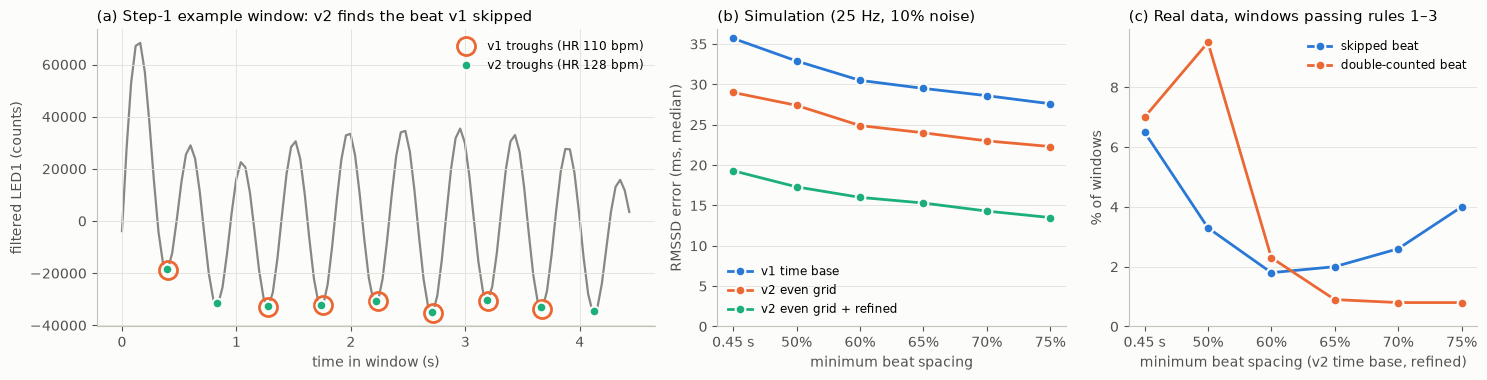

In [41]:
# Figure: (a) the step-1 example window, v1 vs v2 troughs; (b) simulated RMSSD error by spacing rule; (c) real skipped / double beats
ex_wid = int(ten['Raw_Window_Index'].iloc[3])
ew = sophia_data[sophia_data.raw_window_index == ex_wid].sort_values('row_index')
e_led, e_ts = ew.led1.to_numpy(float), ew.timestamp_ms.to_numpy(float)
tb2 = v2_timebase(e_led, e_ts); tb1 = ppg_beats_v1_timebase(e_led, e_ts)
_, loc1 = matlab_findpeaks(-tb1['smooth'], tb1['t'], 0.45)
_, loc2 = matlab_findpeaks(-tb2['smooth'], tb2['t'], min_spacing(V2_FACTOR, tb2['HR_ref']))
idx2 = np.searchsorted(tb2['t'], loc2); t2 = refine_trough_times(tb2['smooth'], tb2['t'], idx2)
hr1 = rr_stats(np.diff(loc1))['HR']; hr2 = rr_stats(np.diff(t2))['HR']

fig, axes = plt.subplots(1, 3, figsize=(15, 3.9), gridspec_kw={'width_ratios': [1.6, 1, 1]})
ax = axes[0]
ax.plot(tb2['t'], tb2['smooth'], color=C_GREY, lw=1.6, zorder=1)
idx1 = np.searchsorted(tb1['t'], loc1)                     # same samples, drawn on the even grid
ax.plot(tb2['t'][idx1], tb2['smooth'][idx1], 'o', ms=13, mfc='none', mec=C_ORANGE, mew=2,
        label=f'v1 troughs (HR {hr1:.0f} bpm)', zorder=2)
ax.plot(t2, np.interp(t2, tb2['t'], tb2['smooth']), 'o', ms=7, color=C_AQUA, mec='#fcfcfb', mew=1.5,
        label=f'v2 troughs (HR {hr2:.0f} bpm)', zorder=3)
ax.set_xlabel('time in window (s)'); ax.set_ylabel('filtered LED1 (counts)')
ax.set_title(f'(a) Step-1 example window: v2 finds the beat v1 skipped', loc='left', fontsize=10.5)
ax.legend(loc='upper right', fontsize=8.5, frameon=False)

ax = axes[1]
s25 = SIM_TABS['25 Hz, 112 samples (current)'].xs(0.10, level='noise')
xlab = ['0.45 s'] + [f'{f:.0%}' for f in SWEEP_FACTORS[1:]]
for (tb_, r_), col, lab in ((('v1 timestamps', False), C_BLUE, 'v1 time base'),
                            (('v2 even grid', False), C_ORANGE, 'v2 even grid'),
                            (('v2 even grid', True), C_AQUA, 'v2 even grid + refined')):
    y = [s25.loc[variant_name(tb_, f_, r_), 'RMSSD error (ms, median |err|)'] for f_ in SWEEP_FACTORS]
    ax.plot(range(len(xlab)), y, '-o', color=col, lw=2, ms=7, mec='#fcfcfb', mew=1.5, label=lab)
ax.set_xticks(range(len(xlab))); ax.set_xticklabels(xlab)
ax.set_xlabel('minimum beat spacing'); ax.set_ylabel('RMSSD error (ms, median)')
ax.set_ylim(bottom=0); ax.set_title('(b) Simulation (25 Hz, 10% noise)', loc='left', fontsize=10.5)
ax.legend(fontsize=8.5, frameon=False, loc='lower left')

ax = axes[2]
for colname, col, lab in (('% skipped beat', C_BLUE, 'skipped beat'), ('% double-counted', C_ORANGE, 'double-counted beat')):
    y = [SWEEP_ALL.loc[variant_name('v2 even grid', f_, True), colname] for f_ in SWEEP_FACTORS]
    ax.plot(range(len(xlab)), y, '-o', color=col, lw=2, ms=7, mec='#fcfcfb', mew=1.5, label=lab)
ax.set_xticks(range(len(xlab))); ax.set_xticklabels(xlab)
ax.set_xlabel('minimum beat spacing (v2 time base, refined)'); ax.set_ylabel('% of windows')
ax.set_ylim(bottom=0); ax.set_title('(c) Real data, windows passing rules 1–3', loc='left', fontsize=10.5)
ax.legend(fontsize=8.5, frameon=False)
for a_ in axes[1:]:
    a_.grid(axis='x', visible=False)
fig.tight_layout()
FIG_V2 = OUT_DIR / 'fig_A1v2_beat_detection.png'
fig.savefig(FIG_V2, dpi=140, bbox_inches='tight'); plt.show()

**Takeaway:** on simulated pulses with known beats (true RMSSD ≈ 25 ms), v2 cuts the **RMSSD error from 35.7 to 14.3 ms** at 10% noise, and from 26.0 to 6.8 ms on clean signal (figure, panel b). Each part helps on its own (clean signal: refined timing 26.0 → 14.7 ms, even grid 26.0 → 20.0 ms, 70% rule 26.0 → 21.8 ms), and together they do best. HR error is under 2 bpm in every version, so these changes matter for HRV, not HR. At **100 Hz / 30 s** the old rule hurts much less (8.4 ms RMSSD error at 10% noise) and v2 still lowers it to 4.8 ms; HR error is 0.1 bpm. 75% is a hair better than 70% in the simulation, but the simulation has no early beats and the real data shows 75% skipping more, so 70% stays.

### 9e · Saturation check (zeros as well as the ceiling)

Anisha's `LED_Saturated` flags a window when any LED reaches the ceiling (524287) but does not check for 0. Gate rule 1 already checks LED1 for both. This counts both, per LED and ring.

In [42]:
sat = pd.DataFrame({'ring': raw['ring']})
for k in ('led1', 'led2', 'led3'):
    sat[f'{k} at ceiling'] = raw[k].map(lambda v: bool((v >= LED_MAX).any()))
    sat[f'{k} at 0'] = raw[k].map(lambda v: bool((v <= 0).any()))
sat['her flag (any LED at ceiling)'] = sat[[f'led{k} at ceiling' for k in (1, 2, 3)]].any(axis=1)
sat['new flag (ceiling or 0)'] = sat[[c for c in sat.columns if c.startswith('led')]].any(axis=1)
assert (sat['her flag (any LED at ceiling)'] == gw['LED_Saturated'].astype(bool)).all(), 'must match her LED_Saturated'
SAT_TAB = sat.groupby('ring', observed=True).sum()
SAT_TAB['windows'] = sat.groupby('ring', observed=True).size()
SAT_TAB['added by the 0 check'] = SAT_TAB['new flag (ceiling or 0)'] - SAT_TAB['her flag (any LED at ceiling)']
display(SAT_TAB.T)
gw['LED_saturated_or_zero'] = sat['new flag (ceiling or 0)'].to_numpy()

ring,R3,R4,R1
led1 at ceiling,17,0,0
led1 at 0,0,0,0
led2 at ceiling,1,7,129
led2 at 0,0,0,6
led3 at ceiling,0,0,0
led3 at 0,0,0,0
her flag (any LED at ceiling),18,7,129
new flag (ceiling or 0),18,7,135
windows,3580,4988,5140
added by the 0 check,0,0,6


**Takeaway:** checking for 0 adds only **6 windows** (Ring 1, LED2, 1–2 zero samples each). The real saturation issue is **Ring 1's LED2, at the ceiling in 129 windows**; Ring 3's LED1 hits it in 17 (already removed by gate rule 1). LED2 isn't used for HR/HRV, so this mainly affects LED2 pulse-amplitude features. The combined flag is kept as `LED_saturated_or_zero` on the window table.

### 9f · Re-run the A1 HR/HRV results with v2

Same pipeline as steps 3–5, with LED1 HR, SDNN, RMSSD, intervals and pooled RMSSD from v2 (70%, even grid, refined). The gate is recomputed with v2: rule 3 (periodic) and rule 4 (HR agrees) use the autocorrelation at the true sample rate, and rule 4 and 5 use v2's beats; rules 1 and 2 are unchanged. Bootstrap seeds are the same as step 5. PA features are not re-run (v2 does not change them).

In [43]:
t0 = time.time()
V2 = [ppg_beats_v2(r.led1, r.t_ms) for r in raw.itertuples()]
gw2 = gw.copy()
gw2['HR_LED1'] = [v['HR'] for v in V2]
gw2['SDNN_LED1_ms'] = [v['SDNN_ms'] for v in V2]
gw2['RMSSD_LED1_ms'] = [v['RMSSD_ms'] for v in V2]
gw2['n_rr_LED1'] = [v['n_rr'] for v in V2]
gw2['rr'] = [v['rr'] for v in V2]
gw2['HR_acf'] = [v['HR_ref'] for v in V2]
gw2['acf_peak'] = [v['acf_peak'] for v in V2]
cv2 = gw2['rr'].map(lambda r: r.std(ddof=1) / r.mean() if len(r) >= 2 else np.nan)
gw2['g3_periodic'] = gw2['acf_peak'] > ACF_MIN
gw2['g4_hr_agrees'] = (gw2['HR_LED1'] - gw2['HR_acf']).abs() / gw2['HR_acf'] <= HR_AGREE_MAX
gw2['g5_steady_beats'] = (gw2['n_rr_LED1'] >= MIN_RR) & (cv2 < RR_CV_MAX)
gw2['usable'] = gw2[RULES].all(axis=1)
print(f'v2 on {len(gw2)} windows in {time.time() - t0:.0f} s; fallback to 0.45 s (no autocorrelation peak): '
      f'{np.mean([v["fallback"] for v in V2]):.1%} of windows')

skip1 = gw['rr'].map(lambda r: len(r) >= 2 and r.max() >= 1.6 * np.median(r))
skip2 = gw2['rr'].map(lambda r: len(r) >= 2 and r.max() >= 1.6 * np.median(r))
cmp_tab = pd.DataFrame({
    'usable % v1': gw.groupby('ring', observed=True)['usable'].mean() * 100,
    'usable % v2': gw2.groupby('ring', observed=True)['usable'].mean() * 100,
    'skipped beat % v1 (all windows)': skip1.groupby(gw.ring, observed=True).mean() * 100,
    'skipped beat % v2 (all windows)': skip2.groupby(gw.ring, observed=True).mean() * 100,
    'median RMSSD v1, all (ms)': gw.groupby('ring', observed=True)['RMSSD_LED1_ms'].median(),
    'median RMSSD v2, all (ms)': gw2.groupby('ring', observed=True)['RMSSD_LED1_ms'].median(),
    'median RMSSD v1, gated (ms)': gw[gw.usable].groupby('ring', observed=True)['RMSSD_LED1_ms'].median(),
    'median RMSSD v2, gated (ms)': gw2[gw2.usable].groupby('ring', observed=True)['RMSSD_LED1_ms'].median(),
    'median HR v1, gated': gw[gw.usable].groupby('ring', observed=True)['HR_LED1'].median(),
    'median HR v2, gated': gw2[gw2.usable].groupby('ring', observed=True)['HR_LED1'].median(),
}).round(1)
display(cmp_tab.T)

v2 on 13708 windows in 5 s; fallback to 0.45 s (no autocorrelation peak): 8.0% of windows


ring,R3,R4,R1
usable % v1,25.3,6.6,31.8
usable % v2,32.2,9.1,35.5
skipped beat % v1 (all windows),16.0,29.5,13.0
skipped beat % v2 (all windows),7.3,12.9,8.8
"median RMSSD v1, all (ms)",210.8,332.4,210.0
"median RMSSD v2, all (ms)",182.0,300.6,188.2
"median RMSSD v1, gated (ms)",86.2,84.7,81.6
"median RMSSD v2, gated (ms)",78.8,70.2,76.8
"median HR v1, gated",73.1,70.0,71.9
"median HR v2, gated",70.8,67.5,71.5


In [44]:
# Survey tables and effect sizes with v2 (HR / HRV features only; same comparisons, norms and bootstrap seeds as step 5)
V2_FEATURES = ['HR_LED1', 'SDNN_LED1_ms', 'RMSSD_LED1_ms', POOLED]
GATES2 = {'all': gw2, 'gated': gw2[gw2.usable]}
SURV2 = {(g, n): tab for g, d in GATES2.items() for n, tab in build_survey_tables(d).items()}
surv_counts = pd.DataFrame({'gated surveys v1': [SURV[('gated', 'raw')].loc[r]['Survey_ID'].nunique() for r in RINGS],
                            'gated surveys v2': [SURV2[('gated', 'raw')].loc[r]['Survey_ID'].nunique() for r in RINGS]},
                           index=list(RINGS))
display(surv_counts.T)
HRV_LOW2 = {(g, r): d[d.ring == r]['RMSSD_LED1_ms'].median() > HRV_IMPLAUSIBLE_MS for g, d in GATES2.items() for r in RINGS}
HRV_LOW2.update({(g, 'ALL'): d['RMSSD_LED1_ms'].median() > HRV_IMPLAUSIBLE_MS for g, d in GATES2.items()})

def effects_for(surv, feats, hrv_low, version):
    rows_ = []
    for gate in ('all', 'gated'):
        for ring in list(RINGS) + ['ALL']:
            base_ = surv[(gate, 'raw')].reset_index()
            if ring != 'ALL':
                base_ = base_[base_.ring == ring]
            base_['cluster'] = base_['ring'].astype(str) + ':' + base_['Survey_ID'].astype(str)
            for A, B in COMPARISONS:
                col = 'Label2' if A == 'good' else 'Label'
                sel = base_[col].isin([A, B]).to_numpy(); units = base_[sel]
                clusters = {c: i for i, c in enumerate(units['cluster'].unique())}
                C = boot_counts(len(clusters), zlib.crc32(f'{gate}|{ring}|{A}|{B}'.encode()))
                for norm in NORMS:
                    T = surv[(gate, norm)].reset_index()
                    T = (T if ring == 'ALL' else T[T.ring == ring])[sel]
                    for feat in feats:
                        v = T[feat].to_numpy(float); isA = (units[col] == A).to_numpy(); ok = np.isfinite(v)
                        ma, mb = isA & ok, ~isA & ok
                        ca = units['cluster'][ma].map(clusters).to_numpy(); cb = units['cluster'][mb].map(clusters).to_numpy()
                        d, lo, hi, nb = cliffs_delta_ci(v[ma], ca, v[mb], cb, C)
                        nA, nB = units['Survey_ID'][ma].nunique(), units['Survey_ID'][mb].nunique()
                        rows_.append({'row_id': f'{ring}|{gate}|{norm}|{SHORT[A]} vs {SHORT[B]}|{feat}', 'version': version,
                                      'ring': ring, 'windows': gate, 'norm': norm,
                                      'level': '2-class' if A == 'good' else '4-class', 'comparison': f'{A} vs {B}',
                                      'feature': feat, 'cliffs_delta': d, 'ci_low': lo, 'ci_high': hi,
                                      'ci_excludes_0': bool(np.isfinite(lo) and (lo > 0 or hi < 0)),
                                      'n_surveys_A': nA, 'n_surveys_B': nB,
                                      'flag_n': 'n<3' if min(nA, nB) < 3 else ('n<5' if min(nA, nB) < 5 else ''),
                                      'flag_hrv': 'HRV low conf' if (feat in HRV_FEATURES and hrv_low.get((gate, ring), False)) else '',
                                      'n_boot_valid': nb})
    return pd.DataFrame(rows_)

t0 = time.time()
eff2 = effects_for(SURV2, V2_FEATURES, HRV_LOW2, 'v2')
eff2.to_csv(OUT_DIR / 'A1v2_hr_hrv_effects.csv', index=False)
print(f'{len(eff2)} v2 rows in {time.time() - t0:.0f} s -> outputs/A1v2_hr_hrv_effects.csv')
print('HRV low confidence (v2):', [k for k, v in HRV_LOW2.items() if v] or 'none')

both_ = eff[eff.feature.isin(V2_FEATURES)][['row_id', 'cliffs_delta', 'ci_low', 'ci_high', 'ci_excludes_0', 'flag_n']].merge(
    eff2[['row_id', 'cliffs_delta', 'ci_low', 'ci_high', 'ci_excludes_0', 'flag_n', 'n_surveys_A', 'n_surveys_B']],
    on='row_id', suffixes=(' v1', ' v2'))
both_[['ring', 'windows', 'norm', 'comparison', 'feature']] = both_['row_id'].str.split('|', expand=True)
both_['v1'] = [fmt(*x) for x in both_[['cliffs_delta v1', 'ci_low v1', 'ci_high v1']].to_numpy()]
both_['v2'] = [fmt(*x) for x in both_[['cliffs_delta v2', 'ci_low v2', 'ci_high v2']].to_numpy()]

# How many HR/HRV CIs exclude 0, v1 vs v2 (gated, n >= 3 on both sides)
ok_ = both_[(both_['flag_n v1'] != 'n<3') & (both_['flag_n v2'] != 'n<3') & (both_.windows == 'gated')]
ci_cmp = ok_.groupby(['ring', 'norm']).agg(tests=('row_id', 'size'), v1=('ci_excludes_0 v1', 'sum'), v2=('ci_excludes_0 v2', 'sum'))
print('HR/HRV CIs excluding 0 (gated, n≥3), v1 vs v2:')
display(ci_cmp.unstack('norm').reindex(['R3', 'R4', 'R1', 'ALL']))

key_ = both_[(both_.windows == 'gated') & both_.norm.isin(['raw', 'day']) &
             both_.comparison.isin(['good vs bad', 'relax vs eu+dis'])]
V2_KEY = key_.pivot_table(index=['ring', 'comparison', 'feature'], columns='norm', values=['v1', 'v2'], aggfunc='first')
V2_KEY = V2_KEY[[('v1', 'raw'), ('v2', 'raw'), ('v1', 'day'), ('v2', 'day')]].reindex(['R3', 'R4', 'R1', 'ALL'], level='ring')
print('Gated, survey level: v1 vs v2 (δ [95% CI]; ✓ = CI excludes 0)')
with pd.option_context('display.max_colwidth', None):
    display(V2_KEY)

,R3,R4,R1
gated surveys v1,43,33,43
gated surveys v2,45,36,43


672 v2 rows in 1 s -> outputs/A1v2_hr_hrv_effects.csv
HRV low confidence (v2): [('all', 'R3'), ('all', 'R4'), ('all', 'R1'), ('all', 'ALL')]
HR/HRV CIs excluding 0 (gated, n≥3), v1 vs v2:


tests             v1             v2           
norm   day person raw day person raw day person raw
ring                                               
R3      28     28  28   0      1   1   4      5   5
R4      28     28  28   0      1   1   0      1   1
R1       8      8   8   0      2   2   0      0   0
ALL     28     28  28   0      7   4   1      3   6

Gated, survey level: v1 vs v2 (δ [95% CI]; ✓ = CI excludes 0)


v1                      v2                    v1                    v2
norm                                                          raw                     raw                   day                   day
ring comparison      feature                                                                                                         
R3   good vs bad     HR_LED1                 +0.24 [-0.07, +0.53]  +0.33 [+0.06, +0.58] ✓  +0.13 [-0.19, +0.46]  +0.25 [-0.03, +0.54]
                     RMSSD_LED1_ms           -0.19 [-0.49, +0.13]    -0.30 [-0.58, +0.02]  +0.03 [-0.30, +0.35]  -0.12 [-0.43, +0.21]
                     SDNN_LED1_ms            -0.18 [-0.47, +0.15]    -0.30 [-0.58, +0.03]  +0.00 [-0.32, +0.33]  -0.09 [-0.41, +0.24]
                     pooled_RMSSD_LED1_ms    -0.13 [-0.43, +0.18]    -0.25 [-0.55, +0.08]  +0.06 [-0.28, +0.40]  +0.06 [-0.28, +0.40]
     relax vs eu+dis HR_LED1                 +0.39 [-0.00, +0.75]  +0.46 [+0.13, +0.75] ✓  +0.24 [-0.17, +0.62]  +0.27 [-0.13, +0.62]
                     RMSSD_LED1_ms           -0.35 [-0.73, +0.09]    -0.39 [-0.76, +0.04]  -0.14 [-0.58, +0.29]  -0.19 [-0.61, +0.24]
                     SDNN_LED1_ms            -0.18 [-0.59, +0.27]    -0.25 [-0.67, +0.17]  -0.03 [-0.47, +0.42]  +0.01 [-0.47, +0.50]
                     pooled_RMSSD_LED1_ms    -0.17 [-0.55, +0.26]    -0.32 [-0.71, +0.11]  -0.03 [-0.45, +0.39]  -0.02 [-0.44, +0.43]
R4   good vs bad     HR_LED1                 +0.02 [-0.38, +0.42]    +0.02 [-0.36, +0.40]  +0.10 [-0.32, +0.53]  -0.00 [-0.40, +0.38]
                     RMSSD_LED1_ms           -0.24 [-0.62, +0.19]    -0.15 [-0.51, +0.24]  -0.27 [-0.63, +0.17]  -0.02 [-0.42, +0.40]
                     SDNN_LED1_ms            -0.24 [-0.61, +0.17]    -0.25 [-0.64, +0.14]  -0.23 [-0.61, +0.18]  -0.13 [-0.52, +0.27]
                     pooled_RMSSD_LED1_ms    -0.33 [-0.67, +0.06]    -0.09 [-0.46, +0.29]  -0.19 [-0.57, +0.21]  -0.08 [-0.47, +0.32]
     relax vs eu+dis HR_LED1                 +0.08 [-0.46, +0.57]    +0.26 [-0.23, +0.69]  +0.08 [-0.53, +0.63]  +0.15 [-0.38, +0.64]
                     RMSSD_LED1_ms           -0.48 [-0.88, +0.07]    -0.18 [-0.64, +0.34]  -0.33 [-0.79, +0.24]  +0.13 [-0.39, +0.65]
                     SDNN_LED1_ms            -0.29 [-0.80, +0.31]    -0.30 [-0.75, +0.22]  -0.15 [-0.70, +0.44]  -0.06 [-0.55, +0.46]
                     pooled_RMSSD_LED1_ms    -0.29 [-0.76, +0.25]    -0.26 [-0.70, +0.27]  -0.17 [-0.64, +0.38]  -0.13 [-0.60, +0.40]
R1   good vs bad     HR_LED1               +0.23 [+0.01, +0.45] ✓    +0.14 [-0.10, +0.37]  +0.20 [-0.05, +0.44]  +0.09 [-0.17, +0.33]
                     RMSSD_LED1_ms           -0.21 [-0.45, +0.05]    -0.17 [-0.42, +0.09]  -0.10 [-0.35, +0.15]  -0.03 [-0.25, +0.21]
                     SDNN_LED1_ms            -0.22 [-0.47, +0.03]    -0.15 [-0.39, +0.10]  -0.12 [-0.36, +0.14]  +0.01 [-0.22, +0.28]
                     pooled_RMSSD_LED1_ms    -0.19 [-0.43, +0.06]    -0.09 [-0.33, +0.16]  -0.08 [-0.30, +0.18]  +0.02 [-0.20, +0.27]
     relax vs eu+dis HR_LED1               +0.23 [+0.02, +0.46] ✓    +0.10 [-0.12, +0.34]  +0.15 [-0.12, +0.44]  +0.03 [-0.24, +0.30]
                     RMSSD_LED1_ms           -0.19 [-0.43, +0.06]    -0.16 [-0.41, +0.07]  -0.03 [-0.28, +0.21]  +0.01 [-0.22, +0.24]
                     SDNN_LED1_ms            -0.20 [-0.45, +0.04]    -0.14 [-0.37, +0.09]  -0.05 [-0.30, +0.19]  +0.07 [-0.17, +0.30]
                     pooled_RMSSD_LED1_ms    -0.18 [-0.39, +0.05]    -0.08 [-0.32, +0.16]  -0.02 [-0.23, +0.20]  +0.08 [-0.13, +0.29]
ALL  good vs bad     HR_LED1                 +0.16 [-0.01, +0.33]  +0.18 [+0.01, +0.34] ✓  +0.12 [-0.06, +0.29]  +0.09 [-0.07, +0.25]
                     RMSSD_LED1_ms         -0.19 [-0.34, -0.02] ✓    -0.17 [-0.34, +0.00]  -0.07 [-0.24, +0.10]  -0.02 [-0.18, +0.14]
                     SDNN_LED1_ms          -0.19 [-0.35, -0.02] ✓  -0.20 [-0.36, -0.03] ✓  -0.06 [-0.21, +0.10]  -0.02 [-0.19, +0.14]
                     pooled_RMSSD_LED1_ms  

**Takeaway:** v2 gives more clean data and changes two A1 findings.
- **More usable data:** usable windows R3 25.3% → 32.2%, R4 6.6% → 9.1%, R1 31.8% → 35.5%; gated surveys R3 43 → 45, R4 33 → 36. Gated median RMSSD drops to 70–79 ms. Ungated HRV is still > 150 ms, so it stays low confidence.
- **F4 ("bad surveys have higher HRV") mostly disappears:** pooled per-day RMSSD good vs bad −0.07 → −0.02, Ring 4 per-day −0.27 → −0.02. Much of it was beat-detection noise.
- **F5 (Ring 3 HR) gets stronger:** with 5 distress surveys now usable (v1: 3), distress has the **lowest HR** in Ring 3, and it survives per-day (relax vs distress +0.69 [+0.19, +1.00], eustress vs distress +0.57 [+0.09, +0.95], distress vs eustress+distress −0.48 [−0.83, −0.11]). Still only 5 distress surveys, and lower HR under distress is the opposite of the usual stress response, so confidence stays low.
- **Good vs bad per-day:** still no HR/HRV CI excludes 0 in any ring. The day-effect conclusion (F3) stands.

### 9g · Findings rows (v2) and PR description

New and updated rows for the shared findings table, read from `eff2` by `row_id` like step 8. Saved to `outputs/A1v2_findings_rows.csv`.

In [45]:
E2 = eff2.set_index('row_id')
def es2(row_id):
    r = E2.loc[row_id]
    return fmt(r.cliffs_delta, r.ci_low, r.ci_high) + f" (n {r.n_surveys_A}/{r.n_surveys_B})"

FINDINGS_V2 = pd.DataFrame([
    {'id': 'F7', 'feature or group': 'LED1 beat detection (HR, SDNN, RMSSD)', 'ring': 'R3, R4, R1',
     'claim': "Beat detection v2 (min spacing 70% of the window's beat length, even time grid, refined trough timing) "
              "is more accurate than the fixed 0.45 s rule. The timestamps jitter and the median-gap sample rate is 5.4% too high.",
     'effect size': (f"simulation (25 Hz, 10% noise): RMSSD error 35.7 → 14.3 ms; real data (rules 1–3 windows): skipped beats "
                     f"6.4 → 2.6%, double-counted 6.9 → 0.8%, usable windows 2,966 → 3,377"),
     '4-class vs 2-class': 'n/a (measurement)',
     'figure / row': 'fig_A1v2_beat_detection.png; tables 9a, 9c, 9d',
     'holds for Ring 4?': 'yes, biggest gain (skipped 13.3 → 4.3%, usable windows 6.6 → 9.1%)', 'confidence': 'high'},
    {'id': 'F4 (v2 update)', 'feature or group': 'HRV: RMSSD, SDNN, pooled RMSSD', 'ring': 'ALL (R3, R4, R1)',
     'claim': "With v2, the slightly higher HRV in bad surveys mostly disappears per-day; it was largely beat-detection noise plus day.",
     'effect size': (f"ALL per-day RMSSD v1 {fmt(*eff.set_index('row_id').loc['ALL|gated|day|good vs bad|RMSSD_LED1_ms', ['cliffs_delta', 'ci_low', 'ci_high']])}"
                     f" → v2 {es2('ALL|gated|day|good vs bad|RMSSD_LED1_ms')}"),
     '4-class vs 2-class': '2-class (good vs bad)',
     'figure / row': 'ALL|gated|day|good vs bad|RMSSD_LED1_ms (A1v2_hr_hrv_effects.csv)',
     'holds for Ring 4?': f"no longer: R4 per-day {es2('R4|gated|day|good vs bad|RMSSD_LED1_ms')}", 'confidence': 'low'},
    {'id': 'F5 (v2 update)', 'feature or group': 'HR_LED1', 'ring': 'R3',
     'claim': "With v2 (5 distress surveys usable instead of 3), Ring 3 distress has the lowest HR, and this survives per-day. "
              "It is the opposite of the usual stress response and rests on 5 surveys.",
     'effect size': (f"relax vs distress per-day {es2('R3|gated|day|relax vs dis|HR_LED1')}; eustress vs distress per-day "
                     f"{es2('R3|gated|day|eu vs dis|HR_LED1')}; good vs bad per-day {es2('R3|gated|day|good vs bad|HR_LED1')}"),
     '4-class vs 2-class': '4-class only (good vs bad per-day CI spans 0)',
     'figure / row': 'R3|gated|day|relax vs dis|HR_LED1 (A1v2_hr_hrv_effects.csv)',
     'holds for Ring 4?': f"no: R4 relax vs distress per-day {es2('R4|gated|day|relax vs dis|HR_LED1')}", 'confidence': 'low'},
])
FINDINGS_V2.to_csv(OUT_DIR / 'A1v2_findings_rows.csv', index=False)
with pd.option_context('display.max_colwidth', None):
    display(FINDINGS_V2.set_index('id'))

,feature or group,ring,claim,effect size,4-class vs 2-class,figure / row,holds for Ring 4?,confidence
id,,,,,,,,
F7,"LED1 beat detection (HR, SDNN, RMSSD)","R3, R4, R1","Beat detection v2 (min spacing 70% of the window's beat length, even time grid, refined trough timing) is more accurate than the fixed 0.45 s rule. The timestamps jitter and the median-gap sample rate is 5.4% too high.","simulation (25 Hz, 10% noise): RMSSD error 35.7 → 14.3 ms; real data (rules 1–3 windows): skipped beats 6.4 → 2.6%, double-counted 6.9 → 0.8%, usable windows 2,966 → 3,377",n/a (measurement),"fig_A1v2_beat_detection.png; tables 9a, 9c, 9d","yes, biggest gain (skipped 13.3 → 4.3%, usable windows 6.6 → 9.1%)",high
F4 (v2 update),"HRV: RMSSD, SDNN, pooled RMSSD","ALL (R3, R4, R1)","With v2, the slightly higher HRV in bad surveys mostly disappears per-day; it was largely beat-detection noise plus day.","ALL per-day RMSSD v1 -0.07 [-0.24, +0.10] → v2 -0.02 [-0.18, +0.14] (n 79/70)",2-class (good vs bad),ALL|gated|day|good vs bad|RMSSD_LED1_ms (A1v2_hr_hrv_effects.csv),"no longer: R4 per-day -0.02 [-0.42, +0.40] (n 19/17)",low
F5 (v2 update),HR_LED1,R3,"With v2 (5 distress surveys usable instead of 3), Ring 3 distress has the lowest HR, and this survives per-day. It is the opposite of the usual stress response and rests on 5 surveys.","relax vs distress per-day +0.69 [+0.19, +1.00] ✓ (n 14/5); eustress vs distress per-day +0.57 [+0.09, +0.95] ✓ (n 13/5); good vs bad per-day +0.25 [-0.03, +0.54] (n 26/27)",4-class only (good vs bad per-day CI spans 0),R3|gated|day|relax vs dis|HR_LED1 (A1v2_hr_hrv_effects.csv),"no: R4 relax vs distress per-day +0.04 [-0.50, +0.58] (n 13/8)",low


#### PR description (v2)

Adds **Step 9** to `A_fast_features.ipynb`: beat detection v2 for LED1 HR/HRV, the follow-up from the 19 Nov meeting. Steps 1–8 (Anisha's code, v1) are unchanged. Builds on PR #4.

- **v2:** minimum beat spacing = 70% of each window's own beat length (not a fixed 0.45 s); beats timed on an even time grid, because the samples are evenly spaced but the timestamps jitter; sample rate from the mean spacing (the median gap overstates it by 5.4%); trough times refined between samples. Works for any sample rate and window length (tested on simulated 100 Hz / 30 s windows).
- **Accuracy:** on simulated pulses with known beats, RMSSD error falls from 36 to 14 ms (25 Hz, 10% noise). On real data, skipped beats fall from 6.4% to 2.6%, double-counted beats from 6.9% to 0.8%, and usable windows rise 14% (Ring 4: 6.6% → 9.1%).
- **Re-run of A1 HR/HRV:** "bad surveys have higher HRV" mostly disappears; Ring 3 distress shows the lowest HR even per-day (only 5 surveys, low confidence). The day-effect conclusion is unchanged.
- **For the new firmware (Md / Farhad):** timestamps should follow the sample clock, or log a sample counter.